In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
sns.set()
pd.reset_option("display.max_rows")

In [2]:
data = pd.read_csv("D://DataSet/bank_marketing.csv" , sep=";")

<div dir='rtl'>

- duration : 
   - فرض کن بانک می‌خواهد قبل از زنگ زدن تصمیم بگیرد به چه کسی زنگ بزند

   - در آن لحظه:

   - سن مشتری را دارد ✅
   - شغل را دارد ✅
   - تحصیلات را دارد ✅
   - سابقه تماس قبلی را دارد ✅
   - ولی duration را ندارد ❌

   - چون duration یعنی:

   - تماس چقدر طول کشید.
----------------------


- default : 
    - این ستون نشان می‌دهد آیا مشتری در بازپرداخت تعهدات اعتباری خود نکول کرده است یا نه
    - مثلا default = yes یعنی : 
    -  یعنی مشتری سابقه نکول اعتباری دارد؛ یعنی بدهی یا اقساط خود را طبق قرارداد پرداخت نکرده است 
---------------------------
- contact : 
    - این ستون روش تماس بانک با مشتری در کمپین فعلی را نشان می‌دهد :
    - cellular  → تماس از طریق موبایل
    - telephone → تماس از طریق تلفن ثابت
----------------------------
- previous : 

    - تعداد تماس‌هایی که قبل از شروع کمپین فعلی و در کمپین‌های گذشته با مشتری انجام شده است

------------------------
- pdays

    - تعداد روزهای گذشته از آخرین تماس مربوط به کمپین قبلی را نشان می‌دهد  
    - pdays = 999 : 

        - این عدد یک کد ویژه است و نشان می‌دهد فاصله زمانی تماس قبلی در دسترس نیست یا تماس قبلی قابل‌استفاده‌ای ثبت نشده است
        - یعنی فاصله تماس قبلی ثبت یا قابل‌استفاده نیست و معمولاً مشتری سابقه تماس قبلی ندارد  

----------------

- emp.var.rate نرخ تغییر اشتغال (سرعتِ بالا/پایین رفتن شغل‌ها) : 
   - چیست؟ می‌گوید: نسبت به همان فصل سال قبل، نرخ اشتغال چند واحد درصدم تغییر کرده.

   - مثال واقعی از دیتا: مقدار 1.1 یعنی: «نرخ اشتغال، ۱.۱ واحد درصدم بهتر از همین ۳ ماه، یک سال پیش است» — مثلاً اگر تابستان سال قبل ۷۵٪ نیروی کار شاغل بودند، امسال ۷۶.۱٪ شده‌اند. مقدار -3.4 یعنی عکس‌اش: ۳.۴ واحد درصدم شغل از دست رفته، یعنی لایه‌ی بزرگ‌ای از مردم یا کارشان را از دست داده‌اند یا ترس بیکاری دارند.

   - چرا برای سپرده مهم است؟ آدمِ شاغل با درآمد منظم، آدمِ پس‌انداز است. وقتی emp.var.rate منفی و بزرگ باشد، مردم یا بی‌کارند یا می‌ترسند — نه پول مازاد دارند، نه خیال‌شان راحت که حساب بانکی‌شان را پر کنند.

------------------------------------

- cons.price.idx شاخص قیمت مصرف‌کننده (تورم؛ سبد خرید مردم) : 
   - چیست: میزان تورم/قیمت اشیایی که مردم روزمره می‌خرند (غذا، بنزین، خدمات) در آن دوره.

   - کاری که می‌کند: نشان می‌دهد قیمت‌ها نسبت به دوره‌ی مرجع چقدر بالا رفته. عدد بالاتر = تورم بیشتر = قدرت خرید مردم کمتر.

   - مقادیر در دیتای شما: بین ۹۲.۲ و ۹۴.۸ (یک شاخص با پایه‌ی صدها). چون محدوده‌اش خیلی باریک است، در عمل نوسانش کم بوده


-----------------------------------

- cons.conf.idx — شاخص اعتماد مصرف‌کننده (روحیه‌ی مردم نسبت به اقتصاد) : 
   - چیست؟ از مردم نظرسنجی می‌شود: «آیا اقتصاد بهتر می‌شود یا بدتر؟ الان وقت خرید اجناس گران است یا نه؟ الان وقت پس‌انداز است یا خرج کردن؟» جواب‌ها جمع -می‌شوند و یک عدد می‌سازند: مثبت = خوش‌بین، منفی = بدبین.

   - مثال واقعی از دیتا: همه‌ی مقادیر منفی هستند (از -26.9 تا -50.8) — یعنی در تمام این دوره، مردم پرتغال بدبین بودند (که با بحران اقتصادی ۲۰۰۸-۲۰۱۲ اروپا همخوانی دارد). مقدار -40.4 یعنی بدبینی نسبتاً عمیق؛ -26.9 یعنی هنوز منفی ولی کمی بهتر از بدترین ماه‌ها.

   - چرا برای سپرده مهم است؟ آدمِ بدبین دو احتمال دارد: یا پولش را در خانه نگه می‌دارد (نه بانک)، یا برعکس، «پناه» می‌برد به جای امن (سپرده‌ی بانکی). -در هر دو صورت، این عدد به مدل می‌گوید «روحیه‌ی اقتصادیِ لحظه» چه بوده است.


---------------------


- euribor3m — نرخ بهره‌ی بین‌بانکیِ ۳ ماهه (قیمتِ پول) : 

   - چیست؟ EURIBOR یعنی میانگین نرخ بهره‌ای که بانک‌های اروپا از هم به هم وام می‌دهند. چرا بانک‌ها از هم وام می‌گیرند؟ چون مثلاً بانک A امروز مشتری‌هایش پول زیادی گرفته‌اند (پول مازاد دارد) و بانک B وام‌های زیادی داده (نقدش کم است) — پس A پولش را به B می‌دهد و کمی سود می‌گیرد. 3m یعنی این وام ۳ ماهه است.

   - مثال واقعی از دیتا: مقادیر از 0.63٪ تا 5.04٪ — پرتِ بزرگی:

   -     0.63٪: پول خیلی ارزان است؛ بانک‌ها راحت و کم‌سود از هم وام می‌گیرند → نرخ سود سپرده در بانک‌ها هم پایین است → سپرده دادن جالب نیست.
   -     5.04٪: پول گران است (بحران اقتصادی؛ بانک‌ها به پول تشنه‌اند) → بانک برای اینکه پول مردم را بگیرد، سود بالاتری روی سپرده اعلام می‌کند → سپرده  دادن جالب می‌شود 

   - چرا این ستون مهم‌ترین شاخص اقتصادی است؟ رابطه‌ی مستقیم با y دارد: سودی که بانک روی سپرده می‌دهد مستقیماً از همین نرخ بازار می‌آید. برای همین         بالاترین ε² را گرفت (0.487).



-----------------------------
- nr.employed — تعداد کل افراد شاغل (اندازه‌ی بازار کار) : 
   - چیست؟ عدد مطلق: در کل کشور چند نفر کار دارند (به هزار نفر).

   - مثال واقعی از دیتا: بین 4,963.6 و 5,228.1 — یعنی تعداد شاغلان کشور در این دوره بین ۴٫۹۶ تا ۵٫۲۳ میلیون نفر بوده. مقدار 5,195.8 یعنی حدود ۵٫۲ میلیون شاغل.

    چرا برای سپرده مهم است؟ هرچه بازار کار بزرگ‌تر باشد، بیشتر مردم حقوق منظم می‌گیرند → بیشتر پس‌انداز → بیشتر سپرده. این هم یک مقدار مطلق است؛ سرعتِ تغییرش را emp.var.rate می‌گوید.







- nonexistent → مشتری کمپین یا تماس قبلی نداشته است  

<div>


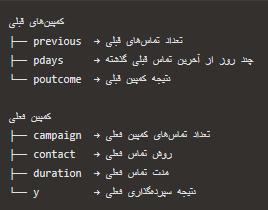

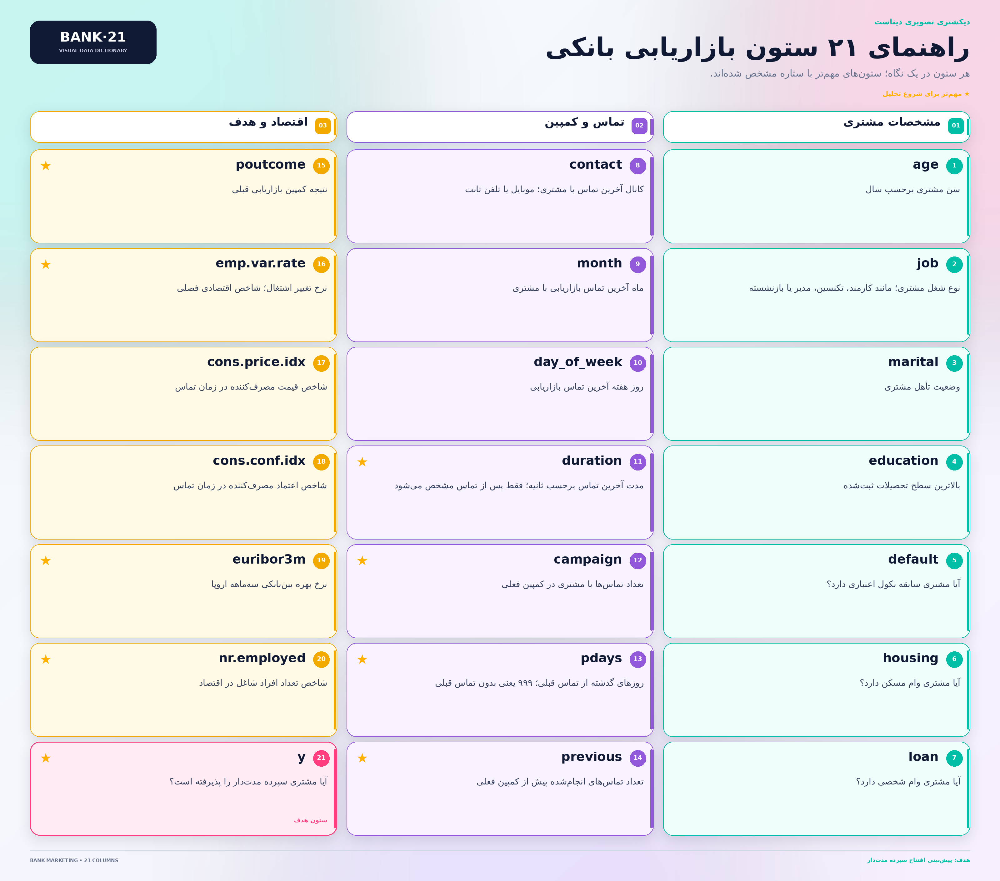

### Preprocessing

In [7]:
data.head(3)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,pdays,previous,poutcome,eco_employment_rate_change_pct,eco_consumer_price_index,eco_consumer_confidence_index,eco_interest_rate_3m_pct,eco_num_employed_thousand,deposit,new_age
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,51-60
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,51-60
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,36-50


In [8]:
data.shape

(41176, 22)

In [9]:
data.info()

<class 'pandas.DataFrame'>
Index: 41176 entries, 0 to 41187
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   age                             41176 non-null  int64   
 1   job                             41176 non-null  str     
 2   marital                         41176 non-null  str     
 3   education                       41176 non-null  str     
 4   default                         41176 non-null  str     
 5   housing                         41176 non-null  str     
 6   loan                            41176 non-null  str     
 7   contact                         41176 non-null  str     
 8   month                           41176 non-null  str     
 9   day_of_week                     41176 non-null  str     
 10  duration                        41176 non-null  int64   
 11  campaign                        41176 non-null  int64   
 12  pdays                           41

In [10]:
data.columns


Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'eco_employment_rate_change_pct',
       'eco_consumer_price_index', 'eco_consumer_confidence_index',
       'eco_interest_rate_3m_pct', 'eco_num_employed_thousand', 'deposit',
       'new_age'],
      dtype='str')

In [11]:
for i in data.select_dtypes("str") :
    print(i) 
    print(np.unique(data[i]))
    print(data[i].nunique())
    print("*"*100)


job
['admin.' 'blue-collar' 'entrepreneur' 'housemaid' 'management' 'retired'
 'self-employed' 'services' 'student' 'technician' 'unemployed' 'unknown']
12
****************************************************************************************************
marital
['divorced' 'married' 'single' 'unknown']
4
****************************************************************************************************
education
['basic.4y' 'basic.6y' 'basic.9y' 'high.school' 'illiterate'
 'professional.course' 'university.degree' 'unknown']
8
****************************************************************************************************
default
['no' 'unknown' 'yes']
3
****************************************************************************************************
housing
['no' 'unknown' 'yes']
3
****************************************************************************************************
loan
['no' 'unknown' 'yes']
3
****************************************************************

In [3]:
categorical_columns = data.select_dtypes(include="str").columns


for column in categorical_columns:
    data[column] = (data[column].str.strip().str.lower())


In [14]:
data.isna().sum() / data.shape[0] * 100

age                               0.0
job                               0.0
marital                           0.0
education                         0.0
default                           0.0
housing                           0.0
loan                              0.0
contact                           0.0
month                             0.0
day_of_week                       0.0
duration                          0.0
campaign                          0.0
pdays                             0.0
previous                          0.0
poutcome                          0.0
eco_employment_rate_change_pct    0.0
eco_consumer_price_index          0.0
eco_consumer_confidence_index     0.0
eco_interest_rate_3m_pct          0.0
eco_num_employed_thousand         0.0
deposit                           0.0
new_age                           0.0
dtype: float64

In [5]:
data.duplicated().sum()
data.drop_duplicates(inplace=True)

<div dir='rtl'>

- درصد unknown های هر ستون و درصد کل unknow های دیتاست

</div>

In [4]:
flag = data == "unknown"
print("Total percentage unknown in percent : " , flag.sum().sum() / data.size * 100)
print("-" * 100)
print(flag.sum() / data.shape[0] * 100)

Total percentage unknown in percent :  1.4703774099714664
----------------------------------------------------------------------------------------------------
age                0.000000
job                0.801204
marital            0.194231
education          4.202680
default           20.872584
housing            2.403613
loan               2.403613
contact            0.000000
month              0.000000
day_of_week        0.000000
duration           0.000000
campaign           0.000000
pdays              0.000000
previous           0.000000
poutcome           0.000000
emp.var.rate       0.000000
cons.price.idx     0.000000
cons.conf.idx      0.000000
euribor3m          0.000000
nr.employed        0.000000
y                  0.000000
dtype: float64


<div dir='rtl'>
فرق NaN و unknown : 

<br><br><br>
NaN یعنی:
اصلاً مقداری ثبت نشده.

ولی unknown یعنی:

برای این رکورد اطلاعات وجود داشته، ولی مقدار واقعی مشخص/در دسترس نبوده
</div>

In [5]:
data.rename(columns={
    "y" : "deposit"
} , inplace=True)

data["deposit"] = data.deposit.map({"yes" : 1 , "no" : 0})



data["new_age"] = pd.cut(
    data["age"],
    bins=[
        17,
        25,
        35,
        50,
        60,
        np.inf
    ],
    labels=[
        "17-25",
        "26-35",
        "36-50",
        "51-60",
        "61+"
    ],
    include_lowest=True
)



data = data.rename(columns={
    "emp.var.rate":   "eco_employment_rate_change_pct",
    "cons.price.idx": "eco_consumer_price_index",
    "cons.conf.idx":  "eco_consumer_confidence_index",
    "euribor3m":      "eco_interest_rate_3m_pct",
    "nr.employed":    "eco_num_employed_thousand",
})


In [18]:
data.select_dtypes("number").std()

age                                10.420680
duration                          259.305321
campaign                            2.770318
pdays                             186.937102
previous                            0.494964
eco_employment_rate_change_pct      1.570883
eco_consumer_price_index            0.578839
eco_consumer_confidence_index       4.627860
eco_interest_rate_3m_pct            1.734437
eco_num_employed_thousand          72.251364
deposit                             0.316184
dtype: float64

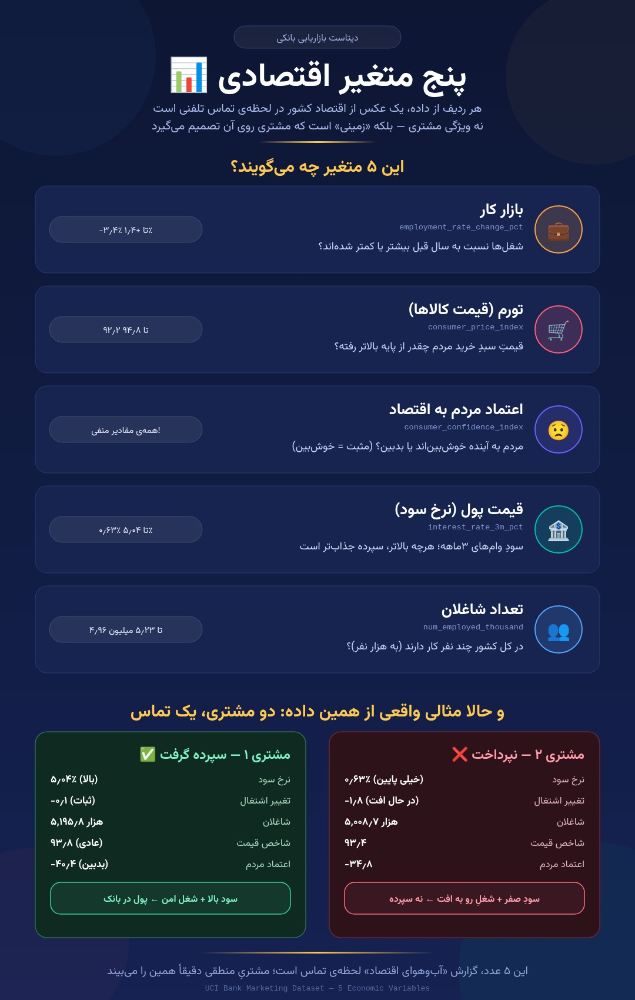

# EDA



هدف : چرا بیشتر افراد سپرده گذاری نکردند 



<div dir='rtl'>

تست‌های آماری
عددی به کتگوری

    T-test: وقتی متغیر عددی تقریباً نرمال و متغیر دسته‌ای دارای دو گروه مستقل باشد.
    Welch T-test: مثل T-test است، ولی زمانی استفاده می‌شود که واریانس دو گروه برابر نباشد.
    Mann–Whitney U: وقتی متغیر عددی غیرنرمال و متغیر دسته‌ای دارای دو گروه مستقل باشد.
    ANOVA: وقتی متغیر عددی تقریباً نرمال و متغیر دسته‌ای دارای سه گروه مستقل یا بیشتر باشد.
    Welch ANOVA: وقتی متغیر عددی تقریباً نرمال، گروه‌ها سه‌تا یا بیشتر و واریانس آن‌ها نابرابر باشد.
    Kruskal–Wallis: وقتی متغیر عددی غیرنرمال و متغیر دسته‌ای دارای سه گروه مستقل یا بیشتر باشد.

کتگوری به کتگوری

    Chi-square: برای بررسی ارتباط و استقلال دو متغیر دسته‌ای، زمانی که تعدادهای مورد انتظار کافی باشند.
    Fisher’s Exact: برای دو متغیر دسته‌ای با جدول 2×2، وقتی تعداد داده یا مقدارهای مورد انتظار کم باشد.
    McNemar: برای دو متغیر باینری وابسته، مانند پاسخ بله/خیر افراد یکسان قبل و بعد از یک اتفاق.

عددی به عددی

    Pearson: وقتی هر دو متغیر عددی، رابطه آن‌ها تقریباً خطی و داده پرت شدید نداشته باشند.
    Spearman: وقتی متغیرها غیرنرمال یا رتبه‌ای باشند و رابطه آن‌ها یکنواخت ولی لزوماً خطی نباشد.
    Kendall: برای متغیرهای رتبه‌ای، نمونه‌های کوچک یا داده‌هایی با رتبه‌های مساوی زیاد.

داده‌های وابسته یا قبل و بعد

    Paired T-test: برای مقایسه دو اندازه‌گیری وابسته، زمانی که اختلاف‌های آن‌ها تقریباً نرمال باشد.
    Wilcoxon Signed-Rank: برای مقایسه دو اندازه‌گیری وابسته و غیرنرمال.
    Repeated-Measures ANOVA: برای سه اندازه‌گیری وابسته یا بیشتر با شرایط نرمال.
    Friedman: برای سه اندازه‌گیری وابسته یا بیشتر با توزیع غیرنرمال.

اندازه اثر

    T-test: مقدار Cohen’s d
    Mann–Whitney U: مقدار Rank-biserial
    ANOVA: مقدار Eta Squared یا Omega Squared
    Kruskal–Wallis: مقدار Epsilon Squared
    Chi-square: مقدار Cramér’s V
    Pearson / Spearman / Kendall: خود ضریب همبستگی


</div>

- Cramér's V :
    - 0.10 → ارتباط ضعیف
    - 0.30 → ارتباط متوسط
    - 0.50 → ارتباط قوی

In [6]:
from scipy.stats import chi2_contingency


def chi2_cramers(data , target , categorical_columns):

    categorical_columns = [
        column
        for column in categorical_columns
        if column != target
    ]

    number_of_tests = len(
        categorical_columns
    )

    results = []

    for column in categorical_columns:

        observed = pd.crosstab(
            data[target],
            data[column]
        )

        chi2, p_value, _, _ = (
            chi2_contingency(observed)
        )

        # اصلاح Bonferroni
        adjusted_p = min(
            p_value * number_of_tests,
            1
        )

        # محاسبه Cramér's V
        n = observed.to_numpy().sum()
        rows, columns = observed.shape

        cramers_v = np.sqrt(
            chi2 / (
                n * min(
                    rows - 1,
                    columns - 1
                )
            )
        )

        results.append(
            {
                "Variable": column,
                "P_Value": adjusted_p,
                "Cramers_V": cramers_v
            }
        )

    return pd.DataFrame(
        results
    ).sort_values(
        "Cramers_V",
        ascending=False
    )

categorical_columns = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome"
]

results = chi2_cramers(
    data=data,
    target="deposit",
    categorical_columns=categorical_columns
)

results


,Variable,P_Value,Cramers_V
9,poutcome,0.000000e+00,0.320520
7,month,0.000000e+00,0.274518
0,job,3.268412e-198,0.152830
6,contact,1.718741e-188,0.144694
3,default,5.217541e-88,0.099366
2,education,3.746768e-37,0.068436
1,marital,1.778423e-25,0.054646
8,day_of_week,3.085755e-04,0.025155
4,housing,5.663793e-01,0.011809
5,loan,1.000000e+00,0.005167


- Kruskal–Wallis : 
    - فرض صفر: توزیع متغیر عددی در تمام گروه‌ها یکسان است.
    - Epsilon Squared : 
        - 0.01 → اثر ضعیف
        - 0.06 → اثر متوسط
        - 0.14 → اثر بزرگ
- U_test : 
    - 0.10	اثر ضعیف
    - 0.30	اثر متوسط
    - 0.50	اثر بزرگ

In [7]:
from scipy.stats import kruskal, mannwhitneyu


def group_association(data, target, columns):
    """
    برای هر ستون، تست مناسب (U یا Kruskal)، P_Value با Bonferroni
    و اندازه‌ی اثر ارتباطش با target را برمی‌گرداند.
    """

    columns = [
        column
        for column in columns
        if column != target
    ]

    number_of_tests = len(columns)

    results = []

    for column in columns:

        clean = data[[target, column]].dropna()

        values = clean[column]
        labels = clean[target].to_numpy()

        groups = [values[labels == g] for g in pd.unique(labels)]
        groups = [g for g in groups if len(g) > 0]

        if len(groups) < 2:
            continue

        if len(groups) == 2:
            # -------- دو گروه: Mann-Whitney U --------
            U, p_value = mannwhitneyu(groups[0], groups[1])

            n1, n2 = len(groups[0]), len(groups[1])

            # همبستگی رانک‌بیسریال (معیار استاندارد ۲ گروهی)
            effect = abs(1 - (2 * U) / (n1 * n2))

            test_name, statistic = "Mann-Whitney U", U

        else:
            # -------- سه گروه به بالا: Kruskal-Wallis --------
            H, p_value = kruskal(*groups)

            n, k = len(clean), len(groups)
            effect = (H - k + 1) / (n - k)  # Epsilon-Squared

            test_name, statistic = "Kruskal-Wallis", H

        # اصلاح Bonferroni
        adjusted_p = min(p_value * number_of_tests, 1)

        results.append(
            {
                "Variable": column,
                "Test": test_name,
                "Statistic": statistic,
                "Bonferroni" : adjusted_p ,
                "P_Value": p_value ,
                "Effect_Size": effect,
            }
        )

    return pd.DataFrame(results).sort_values(
        "Effect_Size",
        ascending=False,
    )



results = group_association(
    data=data,
    target="deposit",                      # deposit
    columns=[
        "age",
        "duration",
        "campaign",
        "pdays",
        "previous",
        "eco_employment_rate_change_pct",
        "eco_consumer_price_index",
        "eco_consumer_confidence_index",
        "eco_interest_rate_3m_pct",
        "eco_num_employed_thousand",
    ]
)

results


,Variable,Test,Statistic,Bonferroni,P_Value,Effect_Size
1,duration,Mann-Whitney U,30773212.0,0.000000e+00,0.000000e+00,0.636884
9,eco_num_employed_thousand,Mann-Whitney U,126943466.5,0.000000e+00,0.000000e+00,0.497901
8,eco_interest_rate_3m_pct,Mann-Whitney U,126006833.0,0.000000e+00,0.000000e+00,0.486849
5,eco_employment_rate_change_pct,Mann-Whitney U,121477346.5,0.000000e+00,0.000000e+00,0.433402
6,eco_consumer_price_index,Mann-Whitney U,103476892.5,1.442761e-134,1.442761e-135,0.221001
4,previous,Mann-Whitney U,66220294.5,0.000000e+00,0.000000e+00,0.218617
3,pdays,Mann-Whitney U,101149077.0,0.000000e+00,0.000000e+00,0.193534
2,campaign,Mann-Whitney U,94103173.5,3.629383e-37,3.629383e-38,0.110394
7,eco_consumer_confidence_index,Mann-Whitney U,78440180.5,7.101349e-16,7.101349e-17,0.074426
0,age,Mann-Whitney U,86590115.5,1.563778e-01,1.563778e-02,0.021742


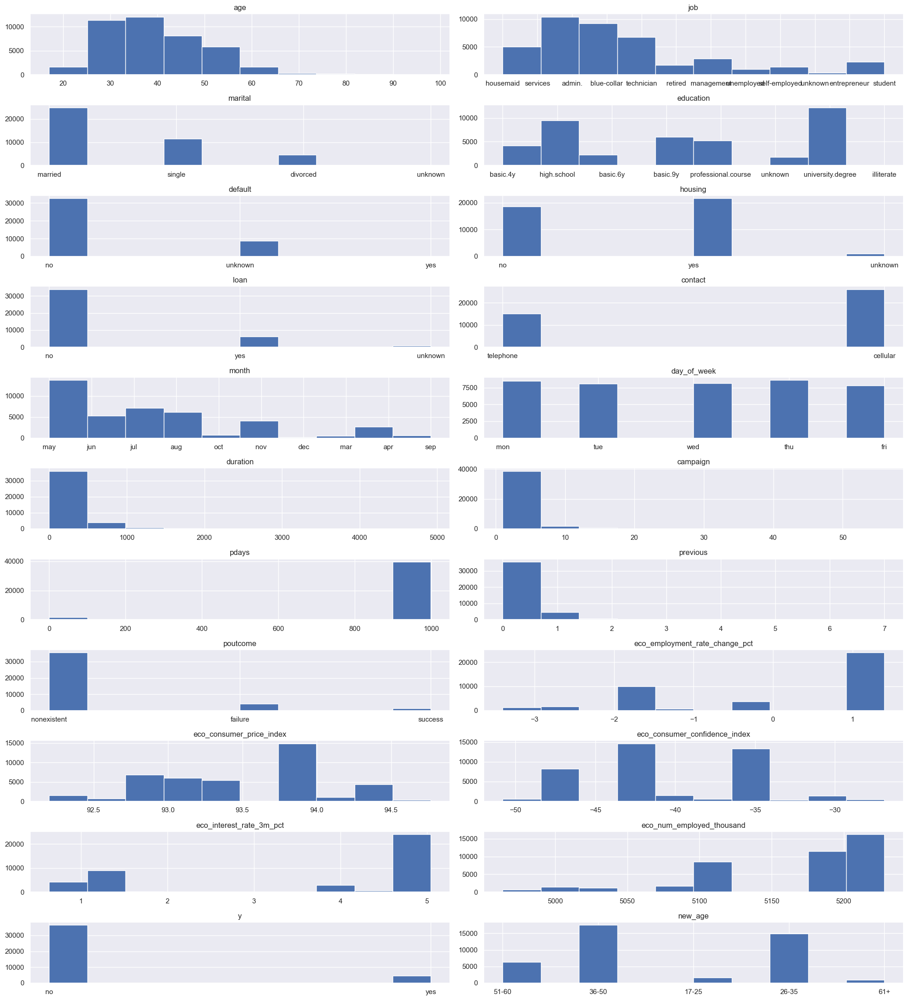

In [ ]:
fig , axes = plt.subplots(11,2,figsize=[20,22])
axes = axes.flatten()


for i , col in enumerate(data) : 
    axes[i].hist(data[col])
    axes[i].set_title(col)

plt.tight_layout()

In [ ]:
for col in data.select_dtypes("number") : 
    print(col)
    print(f"Skew : {data[col].skew()}")
    print("Kurtosis : " , data[col].kurtosis())
    print("mean : " , data[col].mean())
    print("median : " , data[col].median())
    print("-" * 150)

age
Skew : 0.7845602604159752
Kurtosis :  0.7911133225618912
mean :  40.02380027200311
median :  38.0
------------------------------------------------------------------------------------------------------------------------------------------------------
duration
Skew : 3.262807509494723
Kurtosis :  20.24377093511248
mean :  258.3158150378861
median :  180.0
------------------------------------------------------------------------------------------------------------------------------------------------------
campaign
Skew : 4.76204406111779
Kurtosis :  36.97185740479642
mean :  2.567879347192539
median :  2.0
------------------------------------------------------------------------------------------------------------------------------------------------------
pdays
Skew : -4.921386382079702
Kurtosis :  22.221552789558856
mean :  962.464809597824
median :  999.0
------------------------------------------------------------------------------------------------------------------------------------

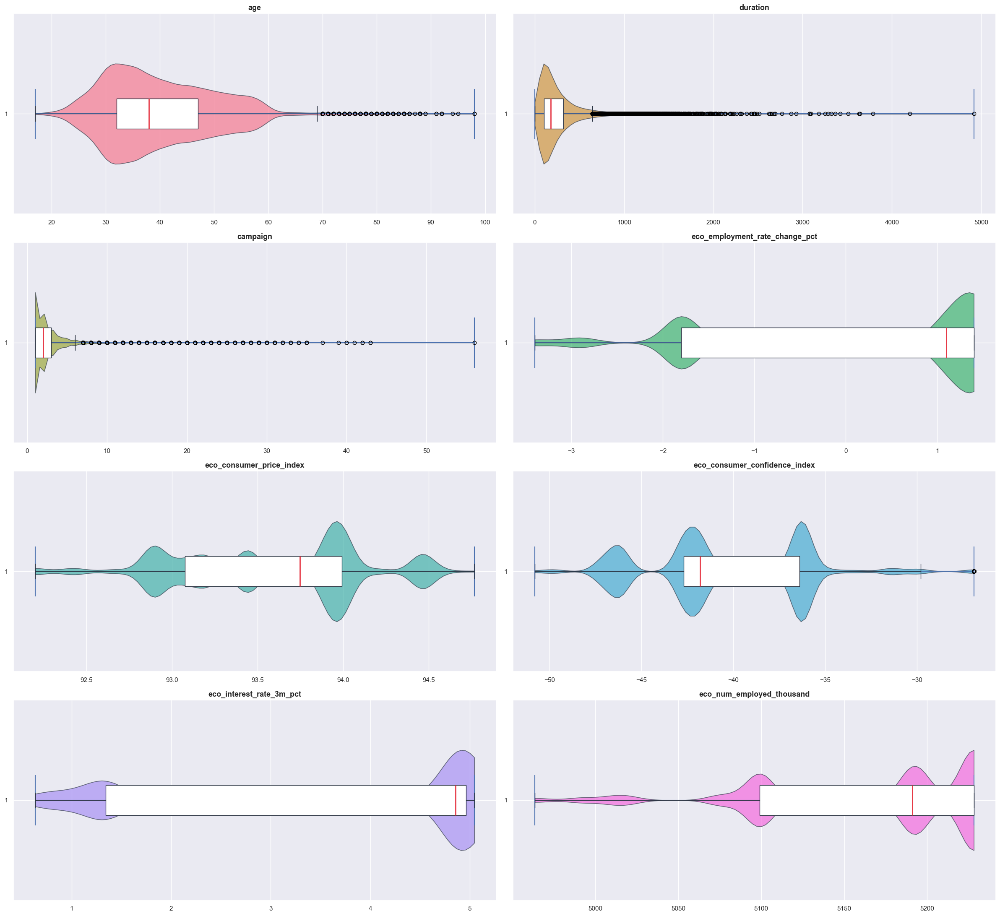

In [ ]:
list_ = [
    "age","duration","campaign","eco_employment_rate_change_pct","eco_consumer_price_index",
    "eco_consumer_confidence_index","eco_interest_rate_3m_pct","eco_num_employed_thousand"
]

colors = sns.color_palette(
    "husl",
    n_colors=len(list_)
)

fig, axes = plt.subplots(
    4,
    2,
    figsize=(24, 22)
)

axes = axes.flatten()

for i, col in enumerate(list_):

    values = data[col].dropna()

    # ابتدا Violin plot
    violin = axes[i].violinplot(values , vert=False,)

    # تغییر رنگ بدنه Violin
    for body in violin["bodies"]:

        body.set_facecolor(
            colors[i]
        )

        body.set_edgecolor(
            "#293241"
        )

        body.set_linewidth(1.2)
        body.set_alpha(0.65)

    # سپس Boxplot تا روی Violin دیده شود
    axes[i].boxplot(
        values,
        vert=False,
        widths=0.15,
        patch_artist=True,
        boxprops={
            "facecolor": "white",
            "edgecolor": "#293241"
        },
        medianprops={
            "color": "#E63946",
            "linewidth": 2
        },
        whiskerprops={
            "color": "#293241"
        },
        capprops={
            "color": "#293241"
        }
    )

    axes[i].set_title(col,fontsize=13,fontweight="bold")

plt.tight_layout()

<div dir='rtl'>

آیا توزیع age نرمال است ؟ 

</div>

Skewness: 0.785
Kurtosis: 0.791


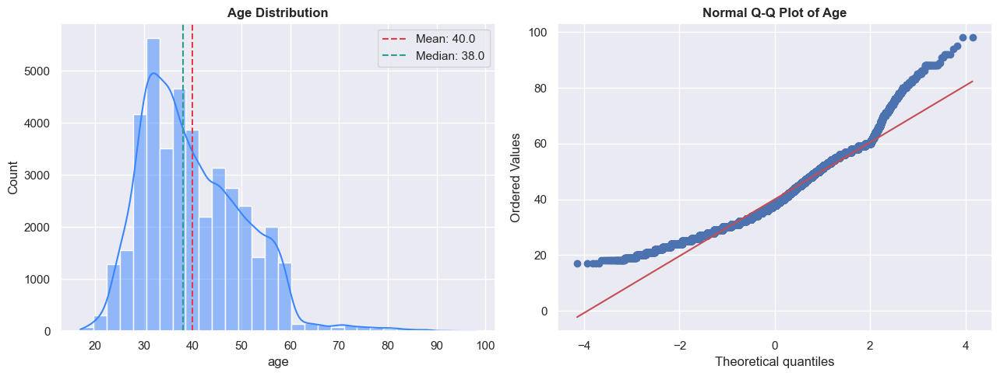

In [ ]:
from scipy.stats import probplot

fig, axes = plt.subplots(1,2,figsize=(13, 5))

# Histogram
sns.histplot(
    data.age,
    bins=30,
    kde=True,
    color="#3A86FF",
    edgecolor="white",
    ax=axes[0]
)

axes[0].axvline(
    data.age.mean(),
    color="#E63946",
    linestyle="--",
    label=f"Mean: {data.age.mean():.1f}"
)

axes[0].axvline(
    data.age.median(),
    color="#2A9D8F",
    linestyle="--",
    label=f"Median: {data.age.median():.1f}"
)

axes[0].set_title(
    "Age Distribution",
    fontweight="bold"
)

axes[0].legend()

# Q-Q Plot
probplot(
    data.age,
    dist="norm",
    plot=axes[1]
)

axes[1].set_title(
    "Normal Q-Q Plot of Age",
    fontweight="bold"
)

plt.tight_layout()

print(f"Skewness: {data.age.skew():.3f}")
print(f"Kurtosis: {data.age.kurtosis():.3f}")

- نرخ کل 

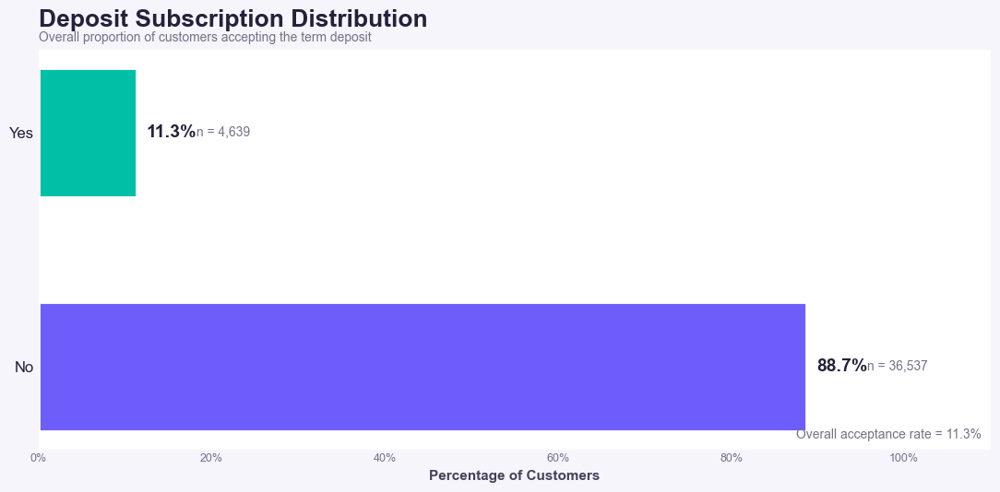

In [19]:
yes_rate = data["deposit"].mean() * 100
no_rate = 100 - yes_rate

yes_count = data["deposit"].sum()
no_count = len(data) - yes_count

labels = ["No", "Yes"]
values = [no_rate, yes_rate]
counts = [no_count, yes_count]

colors = ["#6D5DFB", "#00BFA6"]

fig, ax = plt.subplots(
    figsize=(11, 5.5),
    facecolor="#F7F5FC"
)

ax.set_facecolor("#FFFFFF")

bars = ax.barh(
    labels,
    values,
    height=0.55,
    color=colors,
    edgecolor="white",
    linewidth=2,
    zorder=3
)

for bar, value, count in zip(
    bars,
    values,
    counts
):

    ax.text(
        value + 1.2,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center",
        ha="left",
        fontsize=14,
        fontweight="bold",
        color="#25213B"
    )

    ax.text(
        value + 7,
        bar.get_y() + bar.get_height() / 2,
        f"n = {count:,}",
        va="center",
        ha="left",
        fontsize=10,
        color="#777187"
    )

ax.set_title(
    "Deposit Subscription Distribution",
    fontsize=19,
    fontweight="bold",
    color="#25213B",
    loc="left",
    pad=18
)

ax.text(
    0,
    1.02,
    "Overall proportion of customers accepting the term deposit",
    transform=ax.transAxes,
    fontsize=10,
    color="#777187"
)

ax.set_xlim(0, 110)

ax.set_xlabel(
    "Percentage of Customers",
    fontsize=11,
    fontweight="bold",
    color="#44405A"
)

ax.xaxis.set_major_formatter(
    lambda x, pos: f"{x:.0f}%"
)

ax.tick_params(
    axis="y",
    labelsize=12,
    colors="#25213B",
    length=0
)

ax.tick_params(
    axis="x",
    labelsize=9,
    colors="#777187",
    length=0
)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.8,
    alpha=0.2,
    zorder=0
)

ax.grid(
    axis="y",
    visible=False
)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.text(
    0.99,
    0.02,
    f"Overall acceptance rate = {yes_rate:.1f}%",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
    color="#777187"
)

plt.tight_layout()
plt.show()

- آیا نتیجه کمپین قبلی بر روی سپرده گذاری تاثیر گذار است 

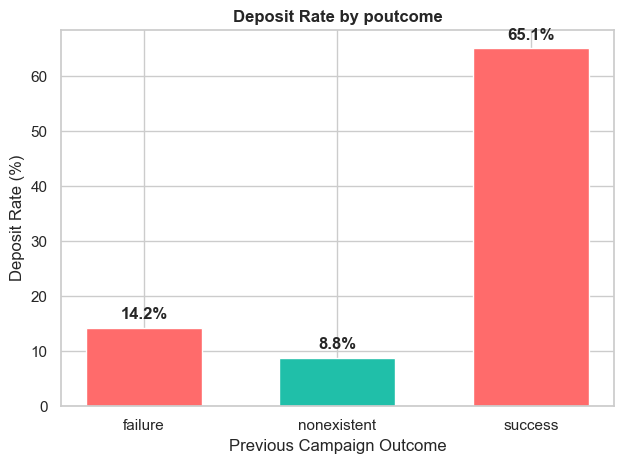

In [ ]:
sns.set_theme(style="whitegrid")

flag = data.groupby("poutcome").deposit.mean().mul(100).reset_index()
# flag = flag[flag["poutcome"] != "nonexistent"]

bars = plt.bar(
    flag["poutcome"],
    flag["deposit"],
    color=["#FF6B6B", "#20BFA9"],
    width=0.60,
    edgecolor="white"
)

plt.bar_label(
    bars,
    fmt="%.1f%%",
    padding=4,
    fontweight="bold"
)

plt.title(
    "Deposit Rate by poutcome",
    fontweight="bold"
)

plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Deposit Rate (%)")

plt.tight_layout()

 - عوامل تاثیر گذار در کمپین قبلی 

<div dir='rtl'>
- poutcome نتیجه کمپین قبلی است. متغیرهای کمپین فعلی مانند:

    - "contact"
    - "month"
    - "day_of_week"
    - "duration"
    - "campaign"

- از نظر زمانی نمی‌توانند علت نتیجه کمپین قبلی باشند؛ چون بعد از آن رخ داده‌اند. ممکن است با آن ارتباط داشته باشند، اما نباید بگوییم روی poutcome اثر گذاشته‌اند

- متغیرهای اقتصادی نیز در زمان کمپین فعلی ثبت شده‌اند پس حتی اگر ارتباطی بین آن ها و poutcome باشد نباید لحاظ شود  : 
    - "emp.var.rate"
    - "cons.price.idx"
    - "cons.conf.idx"
    - "euribor3m"
    - "nr.employed"


- ممکن است این ستون‌ها با poutcome ارتباط آماری قوی نشان دهند، اما نمی‌توان گفت باعث نتیجه کمپین قبلی شده‌اند؛ چون مقدار آن‌ها مربوط به زمان فعلی است


- نتیجه کمپین قبلی در تمام سطوح تحصیلات با نرخ پذیرش فعلی ارتباط قابل‌توجهی دارد. بااین‌حال، ارتباط مستقیم سطح تحصیلات با نتیجه کمپین قبلی ضعیف است و روند منظمی میان کاهش تحصیلات و افزایش پذیرش مشاهده نمی‌شود. نرخ ۱۰۰٪ گروه illiterate نیز فقط براساس یک مشتری محاسبه شده و قابل تعمیم نیست. بنابراین نمی‌توان براساس این نمودار، هدف‌گیری مشتریان کم‌تحصیلات یا کم‌درآمد را توصیه کرد.



</div>


- درصد قبولی کمپین قبلی افراد بر اساس شغل 

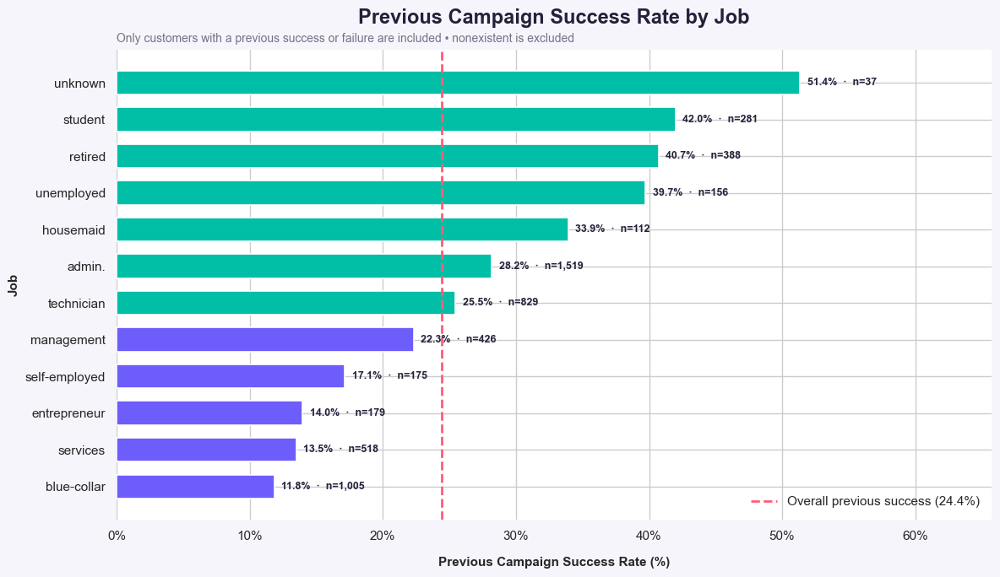

In [ ]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="whitegrid",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)

previous_campaign = data[
    data["poutcome"].isin([
        "success",
        "failure"
    ])
].copy()

previous_campaign["poutcome_success"] = (
    previous_campaign["poutcome"].map({
        "success": 1,
        "failure": 0
    })
)

job_success = (
    previous_campaign.groupby("job")
    ["poutcome_success"]
    .agg(
        Success_Rate="mean",
        Sample_Size="size"
    )
    .reset_index()
)

job_success["Success_Rate"] *= 100

job_success = job_success.sort_values(
    "Success_Rate"
)

overall_success = (
    previous_campaign[
        "poutcome_success"
    ].mean() * 100
)

colors = [
    "#00BFA6"
    if value >= overall_success
    else "#6D5DFB"
    for value in job_success["Success_Rate"]
]

fig, ax = plt.subplots(
    figsize=(12, 7)
)

bars = ax.barh(
    job_success["job"],
    job_success["Success_Rate"],
    height=0.65,
    color=colors,
    edgecolor="white",
    linewidth=1.2
)

ax.bar_label(
    bars,
    labels=[
        (
            f"{rate:.1f}%"
            f"  ·  n={sample_size:,}"
        )
        for rate, sample_size in zip(
            job_success["Success_Rate"],
            job_success["Sample_Size"]
        )
    ],
    padding=6,
    fontsize=9,
    fontweight="bold",
    color="#25213B"
)

ax.axvline(
    overall_success,
    color="#FF5C7A",
    linestyle="--",
    linewidth=2,
    label=(
        f"Overall previous success "
        f"({overall_success:.1f}%)"
    )
)

ax.set_title(
    "Previous Campaign Success Rate by Job",
    fontsize=17,
    fontweight="bold",
    color="#25213B",
    pad=22
)

ax.text(
    0,
    1.015,
    (
        "Only customers with a previous success or failure "
        "are included • nonexistent is excluded"
    ),
    transform=ax.transAxes,
    color="#777187",
    fontsize=10
)

ax.set_xlabel(
    "Previous Campaign Success Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Job",
    fontsize=11,
    fontweight="bold"
)

ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

ax.set_xlim(
    0,
    job_success["Success_Rate"].max() * 1.28
)

ax.legend(
    frameon=False,
    loc="lower right"
)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()


- درصد قبولی کمپین قبلی بر اساس تحصیلات

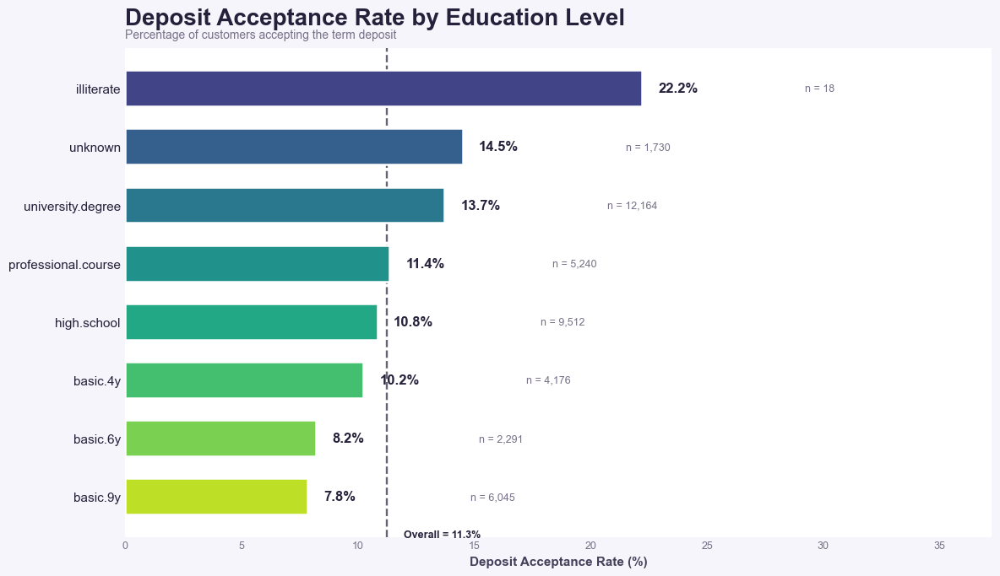

In [51]:
education_rate = (
    data.groupby("education")["deposit"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

labels = education_rate.index
values = education_rate.values

# تعداد نمونه هر گروه
counts = (
    data.groupby("education")["deposit"]
    .size()
    .reindex(labels)
)

fig, ax = plt.subplots(
    figsize=(12, 7),
    facecolor="#F7F5FC"
)

ax.set_facecolor("#FFFFFF")

colors = plt.cm.viridis(
    np.linspace(
        0.2,
        0.9,
        len(values)
    )
)

bars = ax.barh(
    labels,
    values,
    color=colors,
    height=0.62,
    edgecolor="white",
    linewidth=1.8,
    zorder=3
)

ax.invert_yaxis()

for bar, value, count in zip(
    bars,
    values,
    counts
):

    y = (
        bar.get_y()
        + bar.get_height() / 2
    )

    # درصد
    ax.text(
        value + 0.7,
        y,
        f"{value:.1f}%",
        va="center",
        ha="left",
        fontsize=12,
        fontweight="bold",
        color="#25213B"
    )

    # تعداد نمونه
    ax.text(
        value + 7,
        y,
        f"n = {count:,}",
        va="center",
        ha="left",
        fontsize=9,
        color="#777187"
    )


overall_rate = (
    data["deposit"].mean() * 100
)

ax.axvline(
    overall_rate,
    color="#25213B",
    linestyle="--",
    linewidth=1.7,
    alpha=0.7,
    zorder=2
)

ax.text(
    overall_rate + 0.7,
    len(values) - 0.3,
    f"Overall = {overall_rate:.1f}%",
    fontsize=9,
    color="#25213B",
    fontweight="bold"
)


ax.set_title(
    "Deposit Acceptance Rate by Education Level",
    fontsize=20,
    fontweight="bold",
    color="#25213B",
    loc="left",
    pad=20
)

ax.text(
    0,
    1.02,
    "Percentage of customers accepting the term deposit",
    transform=ax.transAxes,
    fontsize=10,
    color="#777187"
)


ax.set_xlabel(
    "Deposit Acceptance Rate (%)",
    fontsize=11,
    fontweight="bold",
    color="#44405A"
)

ax.set_ylabel("")

ax.set_xlim(
    0,
    max(values) + 15
)

ax.tick_params(
    axis="y",
    labelsize=11,
    colors="#25213B",
    length=0
)

ax.tick_params(
    axis="x",
    labelsize=9,
    colors="#777187",
    length=0
)


for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()

- Cramér's V :
    - 0.10 → ارتباط ضعیف
    - 0.30 → ارتباط متوسط
    - 0.50 → ارتباط قوی

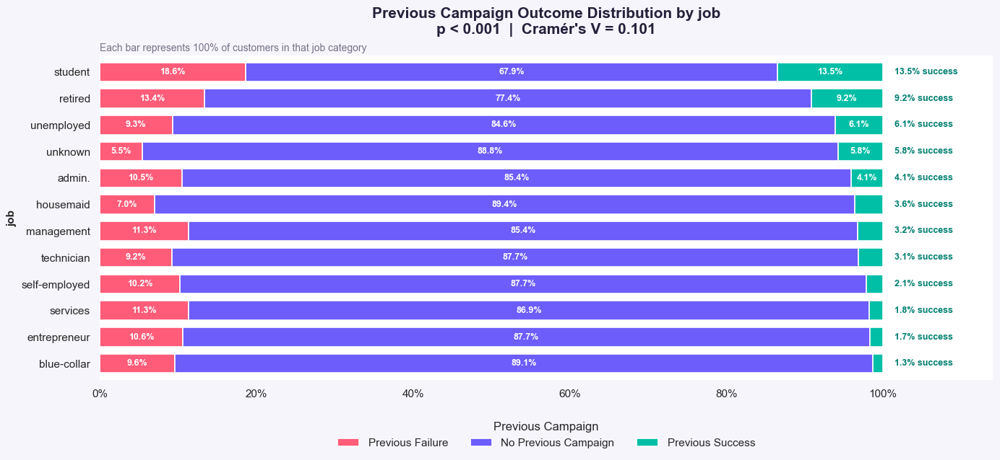

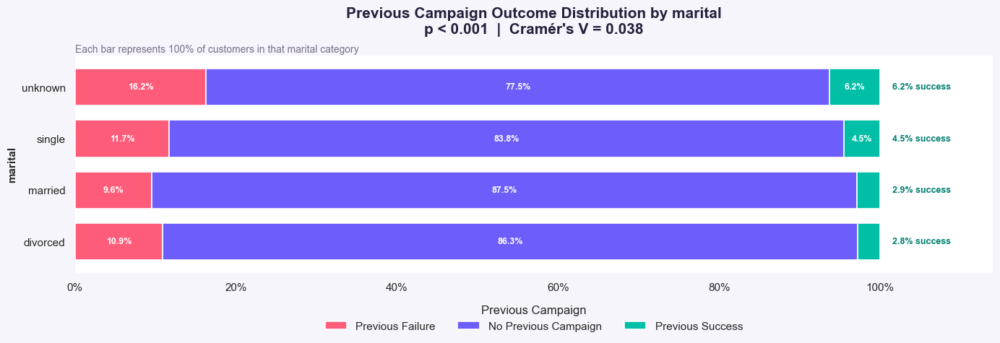

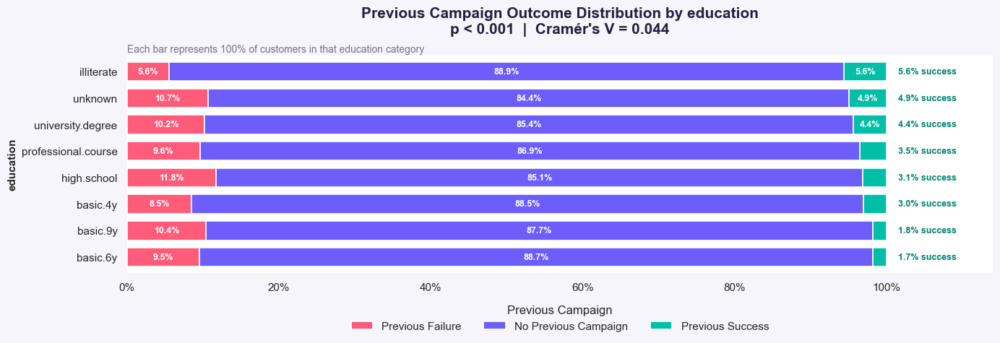

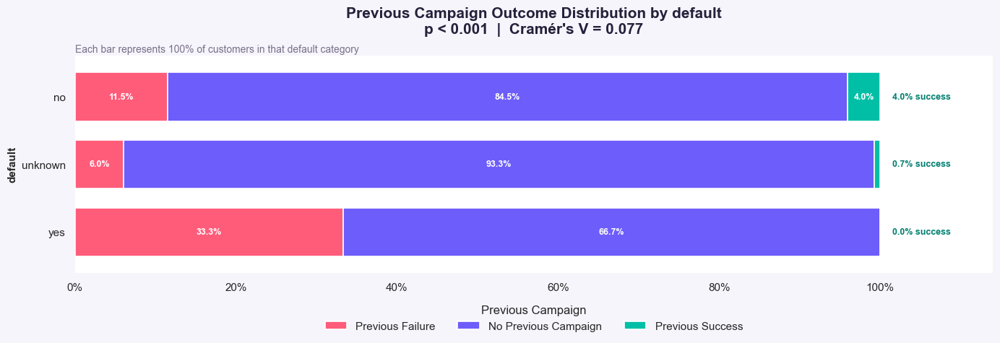

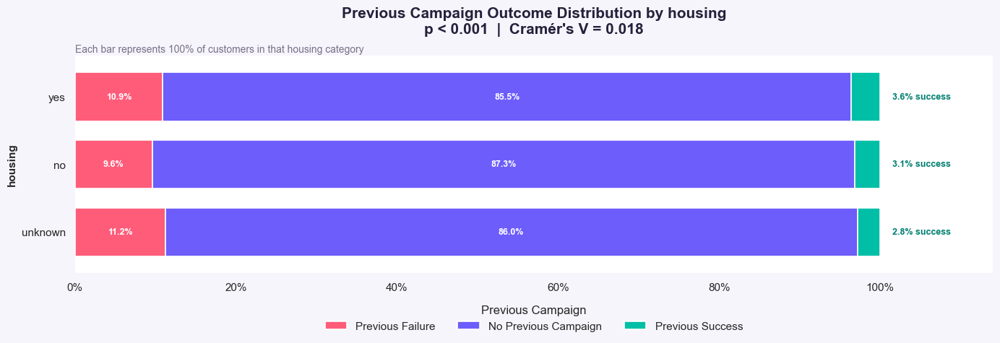

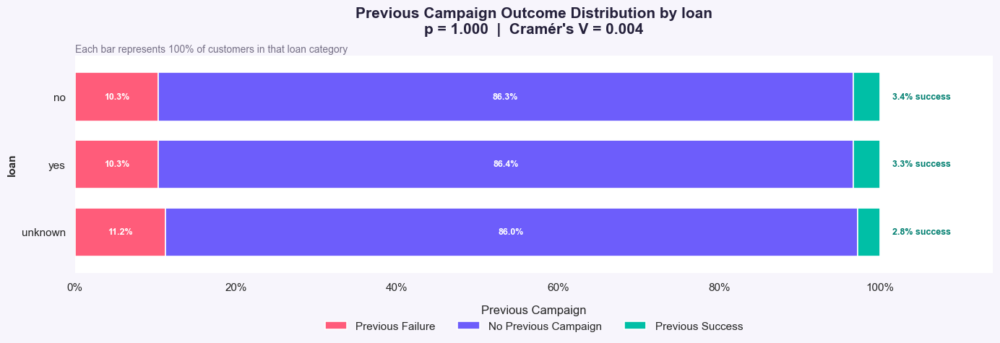

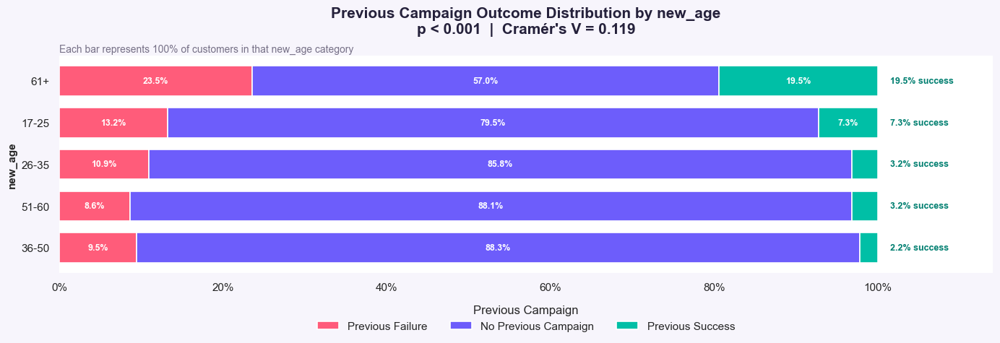

In [49]:
from scipy.stats import chi2_contingency
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)

categorical_columns = ["job","marital","education","default","housing","loan" , "new_age"]
 
number_of_tests = len(
    categorical_columns
)

colors = [
    "#FF5C7A",
    "#6D5DFB",
    "#00BFA6"
]

results = []


for column in categorical_columns:

    # جدول تعدادهای واقعی
    observed = pd.crosstab(
        data[column],
        data["poutcome"],
    )

    # آزمون Chi-square
    chi2, p_value, dof, expected = (
        chi2_contingency(observed)
    )

    # اصلاح Bonferroni
    adjusted_p = min(
        p_value * number_of_tests,
        1
    )

    # محاسبه Cramér's V
    n = observed.to_numpy().sum()
    rows, columns = observed.shape

    cramers_v = np.sqrt(
        chi2 / (
            n * min(
                rows - 1,
                columns - 1
            )
        )
    )

    # بررسی شرایط Expected
    expected_ok = (
        expected.min() >= 1
        and (expected < 5).mean() <= 0.20
    )

    results.append(
        {
            "Variable": column,
            "Adjusted_P": adjusted_p,
            "Cramers_V": cramers_v,
            "Expected_OK": expected_ok
        }
    )

    # تبدیل تعدادها به درصد سطری
    distribution = (
        observed.div(
            observed.sum(axis=1),
            axis=0
        )
        .mul(100)
        .rename(
            columns={
                "failure": "Previous Failure",
                "nonexistent": "No Previous Campaign",
                "success": "Previous Success"
            }
        )
        [
            [
                "Previous Failure",
                "No Previous Campaign",
                "Previous Success"
            ]
        ]
        .sort_values(
            "Previous Success"
        )
    )

    figure_height = max(
        5,
        len(distribution) * 0.55
    )

    fig, ax = plt.subplots(
        figsize=(14, figure_height)
    )

    distribution.plot(
        kind="barh",
        stacked=True,
        width=0.72,
        color=colors,
        edgecolor="white",
        linewidth=1.2,
        ax=ax
    )

    # نوشتن درصد داخل میله‌ها
    for container in ax.containers:

        labels = [
            f"{value:.1f}%"
            if value >= 4
            else ""
            for value in container.datavalues
        ]

        ax.bar_label(
            container,
            labels=labels,
            label_type="center",
            color="white",
            fontsize=9,
            fontweight="bold"
        )

    # نمایش درصد Success کنار هر میله
    for position, value in enumerate(
        distribution["Previous Success"]
    ):

        ax.text(
            101.5,
            position,
            f"{value:.1f}% success",
            va="center",
            color="#007F70",
            fontsize=9,
            fontweight="bold"
        )

    p_text = (
        "p < 0.001"
        if adjusted_p < 0.001
        else f"p = {adjusted_p:.3f}"
    )

    ax.set_title(
        (
            f"Previous Campaign Outcome Distribution by {column}\n"
            f"{p_text}  |  Cramér's V = {cramers_v:.3f}"
        ),
        fontsize=15,
        fontweight="bold",
        color="#25213B",
        pad=22
    )

    ax.text(
        0,
        1.015,
        f"Each bar represents 100% of customers in that {column} category",
        transform=ax.transAxes,
        color="#777187",
        fontsize=10
    )

    ax.set_ylabel(
        column,
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlim(0, 114)

    ax.set_xticks(
        np.arange(0, 101, 20)
    )

    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=100)
    )

    ax.legend(
        title="Previous Campaign",
        ncol=3,
        frameon=False,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.10)
    )

    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout()



- دلیل اینکه افراد بی سواد بیشتر سپرده گذاری میکنند چیست

In [ ]:
data.education.value_counts()

education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64

<div dir="rtl">

در میان ویژگی‌های دسته‌ای مشتری که بررسی شدند، شغل و سن بیشترین ارتباط را با نتیجه کمپین قبلی داشت، اما این ارتباط ضعیف بود. سایر متغیرها ارتباط ناچیزی نشان دادند. بنابراین هیچ‌یک از این ویژگی‌ها به‌تنهایی نمی‌تواند بخش بزرگی از تفاوت‌های poutcome را توضیح دهد. بااین‌حال، براساس این تحلیل دوبه‌دو نمی‌توان وجود عوامل مخدوش‌کننده، تعامل چندمتغیره یا عوامل ثبت‌نشده را رد کرد.
</div>

<div dir="rtl">
- دلیل اختلاف زیاد در توزیع بصری ستون default ولی Crammer پایین آن چیست ؟
</div>

In [ ]:
data.default.value_counts() 

default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

<div dir='rtl'>
گروه default=yes نمونه کافی برای نتیجه‌گیری ندارد و نتایج آن صرفاً توصیفی هستند.

</div>

- آیا افراد بازنشسته واقعا افراد بالا 60 سال هستند (ارتباطی بین سن و شغل برقرار است ؟)

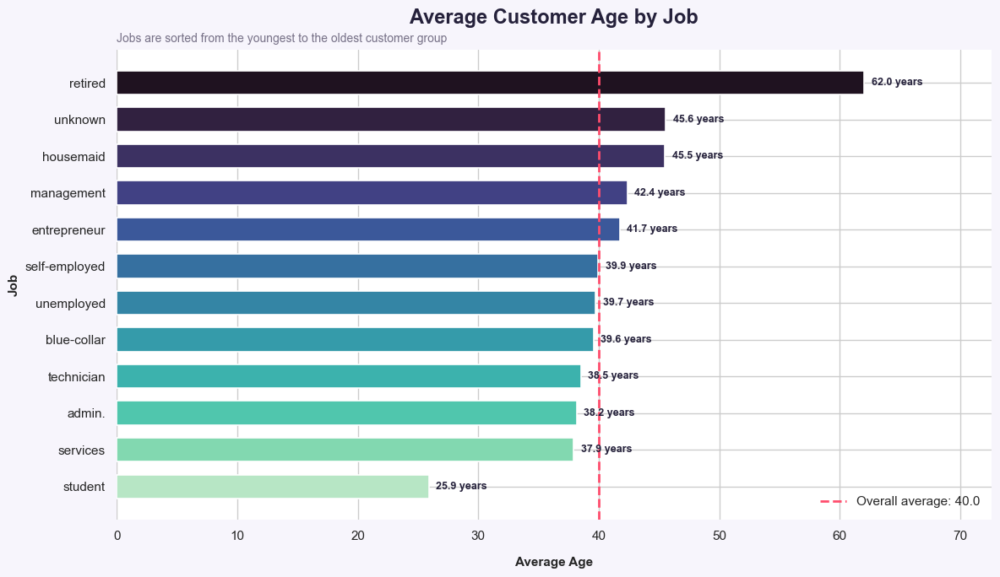

In [ ]:
sns.set_theme(
    style="whitegrid",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)

# میانگین سن هر شغل
job_age = (
    data.groupby("job")["age"]
    .mean()
    .sort_values()
)

# طیف رنگی براساس میانگین سن
colors = sns.color_palette(
    "mako_r",
    n_colors=len(job_age)
)

fig, ax = plt.subplots(
    figsize=(12, 7)
)

bars = ax.barh(
    job_age.index,
    job_age.values,
    height=0.65,
    color=colors,
    edgecolor="white",
    linewidth=1.2
)

# نوشتن میانگین سن کنار میله‌ها
ax.bar_label(
    bars,
    labels=[
        f"{value:.1f} years"
        for value in job_age.values
    ],
    padding=6,
    fontsize=9,
    fontweight="bold",
    color="#25213B"
)

# میانگین سن کل مشتریان
overall_age = data["age"].mean()

ax.axvline(
    overall_age,
    color="#FF4D6D",
    linestyle="--",
    linewidth=2,
    label=f"Overall average: {overall_age:.1f}"
)

ax.set_title(
    "Average Customer Age by Job",
    fontsize=17,
    fontweight="bold",
    color="#25213B",
    pad=22
)

ax.text(
    0,
    1.015,
    "Jobs are sorted from the youngest to the oldest customer group",
    transform=ax.transAxes,
    color="#777187",
    fontsize=10
)

ax.set_xlabel(
    "Average Age",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Job",
    fontsize=11,
    fontweight="bold"
)

ax.set_xlim(
    0,
    job_age.max() * 1.17
)

ax.legend(
    frameon=False,
    loc="lower right"
)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()


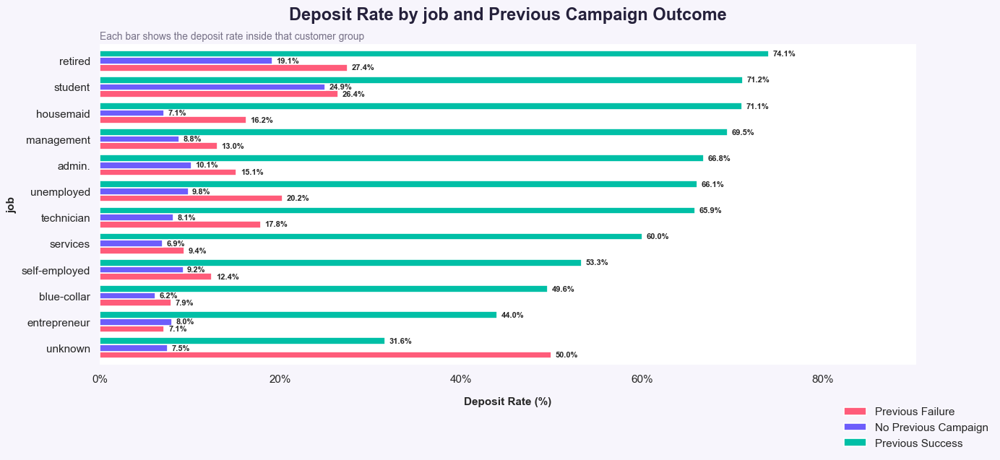

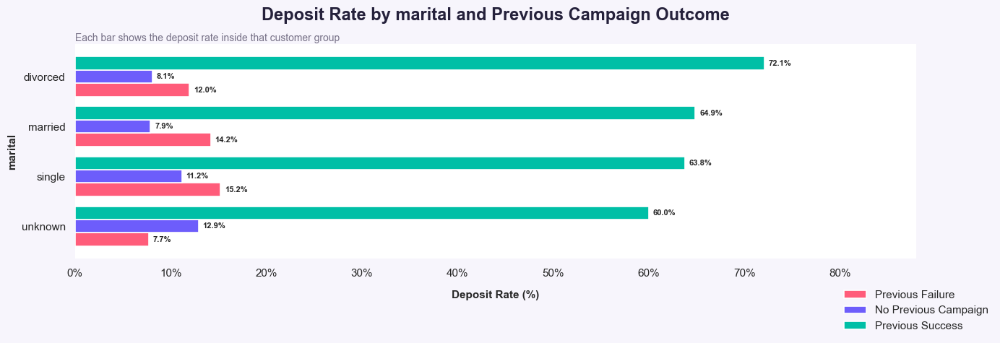

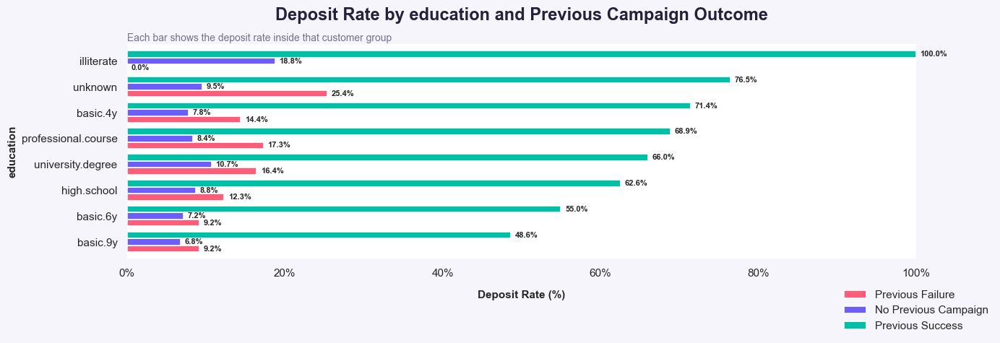

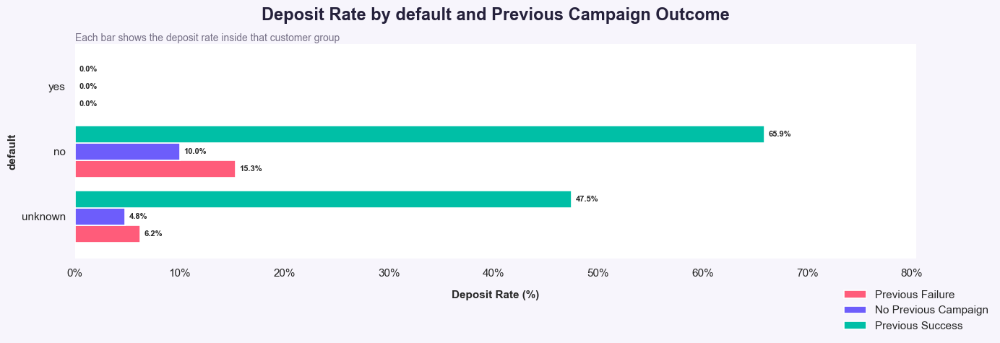

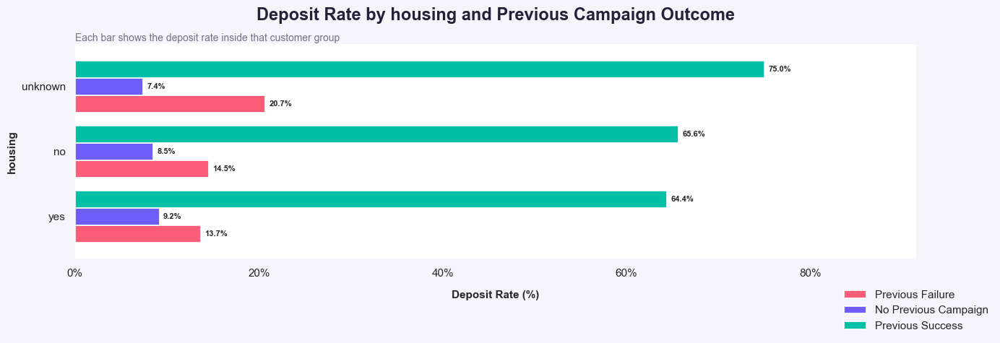

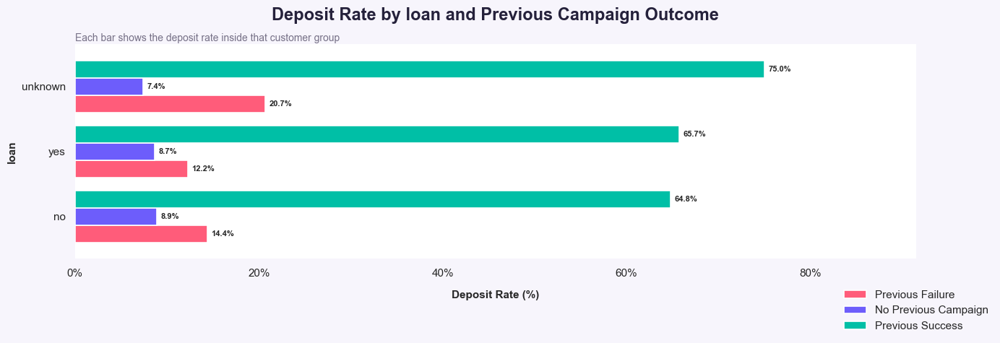

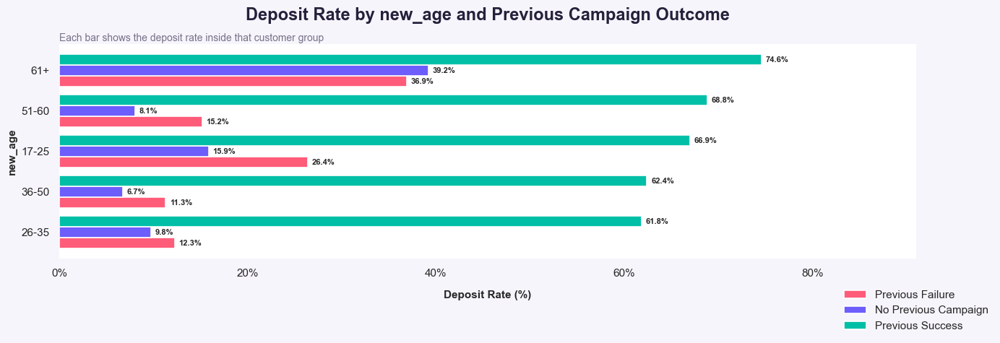

In [14]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)

categorical_columns = ["job","marital","education","default","housing","loan" , "new_age"]

for col in categorical_columns:

    if col in ["poutcome", "y"]:
        continue

    contact_analysis = data.pivot_table(
        index=col,
        columns="poutcome",
        values="deposit",
        aggfunc="mean",
        observed=False
    ).mul(100)

    contact_analysis = (
        contact_analysis.rename(
            columns={
                "failure": "Previous Failure",
                "nonexistent": "No Previous Campaign",
                "success": "Previous Success"
            }
        )
        .reindex(
            columns=[
                "Previous Failure",
                "No Previous Campaign",
                "Previous Success"
            ]
        )
        .sort_values(
            "Previous Success"
        )
    )

    figure_height = max(
        5,
        len(contact_analysis) * 0.55
    )

    fig, ax = plt.subplots(
        figsize=(14, figure_height)
    )

    contact_analysis.plot(
        kind="barh",
        stacked=False,
        width=0.80,
        color=[
            "#FF5C7A",
            "#6D5DFB",
            "#00BFA6"
        ],
        edgecolor="white",
        linewidth=1.2,
        ax=ax
    )

    # نوشتن درصد کنار تمام میله‌ها
    for container in ax.containers:

        labels = [
            f"{value:.1f}%"
            if pd.notna(value)
            else ""
            for value in container.datavalues
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=4,
            fontsize=8,
            fontweight="bold"
        )

    ax.set_title(
        f"Deposit Rate by {col} and Previous Campaign Outcome",
        fontsize=17,
        fontweight="bold",
        color="#25213B",
        pad=24
    )

    ax.text(
        0,
        1.015,
        "Each bar shows the deposit rate inside that customer group",
        transform=ax.transAxes,
        color="#777187",
        fontsize=10
    )

    ax.set_xlabel(
        "Deposit Rate (%)",
        fontsize=11,
        fontweight="bold",
        labelpad=12
    )

    ax.set_ylabel(
        col,
        fontsize=11,
        fontweight="bold"
    )

    maximum_rate = (
        contact_analysis.max().max()
    )

    ax.set_xlim(
        0,
        min(
            100,
            maximum_rate * 1.22
        )
    )

    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=100)
    )


    ax.legend(
        frameon=False,
        loc="upper center",
        bbox_to_anchor=(1, -0.10)
    )

    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout()


- آزمون Kruskal–Wallis
    - فرض صفر: توزیع متغیر عددی در تمام گروه‌ها یکسان است.
    - Epsilon Squared: 
        - 0.01 → اثر ضعیف
        - 0.06 → اثر متوسط
        - 0.14 → اثر بزرگ

- poutcome VS numerical

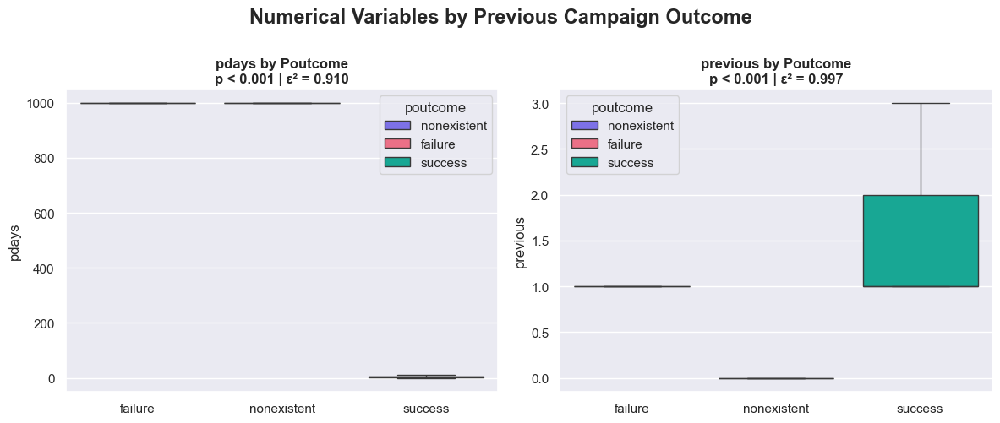

In [ ]:
from scipy.stats import kruskal

numeric_remaining = [
    "pdays",
    "previous",
]

poutcome_order = [
    "failure",
    "nonexistent",
    "success"
]

numeric_results = []

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

axes = axes.flatten()

for ax, column in zip(
    axes,
    numeric_remaining
):

    groups = [
        data.loc[
            data["poutcome"] == outcome,
            column
        ].dropna()
        for outcome in poutcome_order
    ]

    h_statistic, p_value = kruskal(
        *groups
    )

    number_of_tests = len(numeric_remaining)

    adjusted_p = min(
        p_value * number_of_tests,
        1
    )

    number_of_groups = len(groups)
    n = sum(
        len(group)
        for group in groups
    )

    epsilon_squared = max(
        0,
        (
            h_statistic
            - number_of_groups
            + 1
        )
        / (
            n - number_of_groups
        )
    )

    numeric_results.append(
        {
            "Variable": column,
            "Adjusted_P": adjusted_p,
            "Epsilon_Squared": epsilon_squared
        }
    )

    sns.boxplot(
        data=data,
        x="poutcome",
        y=column,
        order=poutcome_order,
        hue="poutcome",
        palette={
            "failure": "#FF5C7A",
            "nonexistent": "#6D5DFB",
            "success": "#00BFA6"
        },
        showfliers=False,
        legend=True,
        ax=ax
    )

    p_text = (
        "p < 0.001"
        if adjusted_p < 0.001
        else f"p = {adjusted_p:.3f}"
    )

    ax.set_title(
        (
            f"{column} by Poutcome\n"
            f"{p_text} | ε² = {epsilon_squared:.3f}"
        ),
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("")
    ax.set_ylabel(column)


fig.suptitle(
    "Numerical Variables by Previous Campaign Outcome",
    fontsize=17,
    fontweight="bold",
    y=1
)

plt.tight_layout()


<div dir='rtl'>
دلیل ارتباط زیاد pdays به poutcome چیه ؟ 

</div>

In [ ]:
data.pdays.value_counts()


pdays
999    39673
3        439
6        412
4        118
9         64
2         61
7         60
12        58
10        52
5         46
13        36
11        28
1         26
15        24
14        20
8         18
0         15
16        11
17         8
18         7
22         3
19         3
21         2
25         1
26         1
27         1
20         1
Name: count, dtype: int64

In [ ]:
print(data.groupby("poutcome").pdays.mean())
print("-" * 100)
print(data.groupby("poutcome").pdays.median())

poutcome
failure        965.976011
nonexistent    999.000000
success          5.587764
Name: pdays, dtype: float64
----------------------------------------------------------------------------------------------------
poutcome
failure        999.0
nonexistent    999.0
success          5.0
Name: pdays, dtype: float64


<div dir='rtl'>
دلیل ارتباط زیاد previous به poutcome چیه ؟ 

</div>

In [ ]:
display(data.groupby("poutcome").previous.value_counts(normalize=True) * 100)
print("-" * 100)
display(data.groupby("previous").poutcome.value_counts(normalize=True) * 100)


poutcome     previous
failure      1            86.923801
             2            10.206961
             3             2.069614
             4             0.705550
             5             0.070555
             6             0.023518
nonexistent  0           100.000000
success      1            63.000728
             2            23.306628
             3             9.322651
             4             2.913328
             5             1.092498
             6             0.291333
             7             0.072833
Name: proportion, dtype: float64

----------------------------------------------------------------------------------------------------


previous  poutcome   
0         nonexistent    100.000000
1         failure         81.034861
          success         18.965139
2         failure         57.559682
          success         42.440318
3         success         59.259259
          failure         40.740741
4         success         57.142857
          failure         42.857143
5         success         83.333333
          failure         16.666667
6         success         80.000000
          failure         20.000000
7         success        100.000000
Name: proportion, dtype: float64

<div dir='rtl'>
نکته‌ی کوچک (تا بعداً سردرنگرمایی): «۸۷٪ failureها مقدار ۱ دارند» و «از میان ۱ها فقط ۱۹٪ success هستند» هر دو همزمان درست‌اند — دو سؤال متفاوت‌اند («از failureها چند تا ۱‌اند؟» در مقابل «از ۱ها چند تا failure‌اند؟»)، مثل اینکه «بیمارِ این عفونت معمولاً تب دارد» با «تب‌دارها لزوماً این عفونت را ندارند» تضادی نیست

----------------------



«nonexistent صد درصدش از ۰ است → اطلاعات یکسان» → ✅ کاملاً درست. حتی از جهت برعکس هم ۱۰۰٪ برمی‌گردد (previous=0 → همیشه nonexistent). این بخش واقعاً «همان متغیر» است.
«86٪ failure از ۱ است → همپوشانی» → ✅ درست (قوی، ولی ۱۴٪ نشت دارد).
«63٪ success از ۱ است → اطلاعات یکسان» → ⚠️ فوق‌العاده می‌روی. ۶۳٪ یعنی ۳۷٪ دیگرِ successها روی مقادیر ۲، ۳، ۴... پخش‌اند؛ یعنی با دیدن success ** نمی‌توانی** previous را با اطمینان بگویی. این «جهت‌گیری» است (successها بیشتر از بقیه در ۱ فشرده‌اند)، نه «یکسان‌بودن».

</div>

In [7]:
#  اطلاعات (آنتروپی)

from scipy.stats import entropy
from sklearn.metrics import mutual_info_score

mi = mutual_info_score(data['previous'], data['poutcome'])
H  = entropy(data['poutcome'].value_counts(normalize=True), base=2)  # ← base=2
print(mi / H)   # → 0.589  


0.5891063249264903


In [18]:
#  اطلاعات (آنتروپی)

from scipy.stats import entropy
from sklearn.metrics import mutual_info_score

mi = mutual_info_score(data['pdays'], data['poutcome'])
H  = entropy(data['poutcome'].value_counts(normalize=True), base=2)  # ← base=2
print(mi / H)   


0.2123163718217676


<div dir='rtl'>
نسبت اطلاعات متقابل 58% نشان می‌دهد poutcome و previous تقریباً یک متغیر تکراری هستند؛ بنابراین ε²≈۱ مشاهده‌شده عمدتاً بازتابِ همین تکرار است، نه یک ارتباط اقتصادی قوی بین دو پدیده‌ی مستقل.
تفسیر عددی: مدیان ۵ روز (success) در مقابل ۹ روز (failure) — یعنی مشتری‌های deposit‌گیرنده، حدوداً دو برابر به‌تازگی‌تر تماس گرفته می‌شدن
</div>

<div dir='rtl'>

بین افرادی که واقعاً در کمپین قبلی تماس داشته‌اند، آیا pdays بین failure و success تفاوت دارد؟

</div>

C:\Users\ASUS\AppData\Local\Temp\ipykernel_1680\584851923.py:70: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  plt.tight_layout(rect=(0, 0.03, 1, 0.94))
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\IPython\core\events.py:100: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  func(*args, **kwargs)
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8315 (\N{SUPERSCRIPT MINUS}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


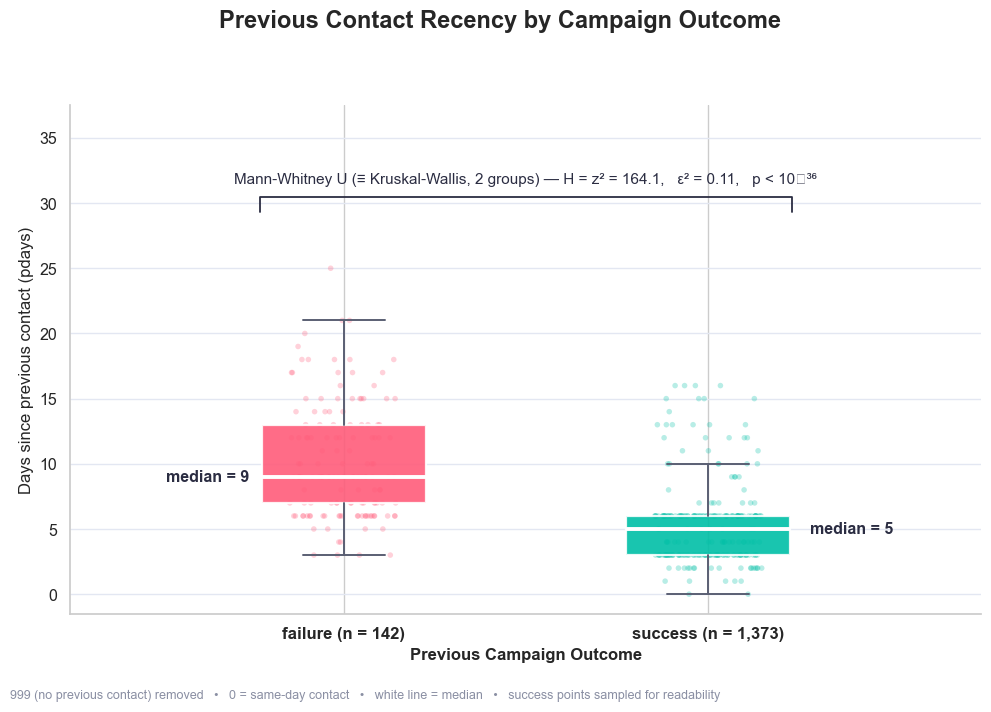

In [15]:
from scipy.stats import kruskal

# ---------- 1) Data: remove the 999 sentinel (no previous contact) ----------
pdays_clean = data.loc[data["pdays"] != 999, ["pdays", "poutcome"]].dropna()
pdays_clean = pdays_clean[pdays_clean["poutcome"].isin(["failure", "success"])]

failure = pdays_clean.loc[pdays_clean["poutcome"] == "failure", "pdays"]
success = pdays_clean.loc[pdays_clean["poutcome"] == "success", "pdays"]

# ---------- 2) Test: with 2 groups, U-test = Kruskal (H = z^2) ----------
h, p = kruskal(failure, success)
n = len(failure) + len(success)
eps2 = max(0, (h - 1) / (n - 2))

# ---------- 3) Chart ----------
fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor("white")

groups = [("failure", failure, "#FF5C7A"), ("success", success, "#00BFA6")]

bp = ax.boxplot([failure.values, success.values], positions=[0, 1], widths=0.45,
                patch_artist=True, showfliers=False, zorder=3,
                medianprops=dict(color="white", lw=2.8),
                whiskerprops=dict(color="#5A5F73", lw=1.4),
                capprops=dict(color="#5A5F73", lw=1.4),
                boxprops=dict(edgecolor="white", lw=1.6))
for patch, (_, _, color) in zip(bp["boxes"], groups):
    patch.set_facecolor(color)
    patch.set_alpha(0.9)

# observation points: all of failure (142), a sample from success — gives texture
rng = np.random.default_rng(42)
for pos, (_, s, color) in zip([0, 1], groups):
    sample = s if len(s) <= 250 else s.sample(250, random_state=42)
    ax.scatter(pos + (rng.random(len(sample)) - 0.5) * 0.30, sample,
               s=16, color=color, alpha=0.28, edgecolors="none", zorder=2)

# median labels on the outer side of each box
ax.text(-0.26, failure.median(), f"median = {failure.median():.0f}",
        ha="right", va="center", fontsize=11.5, fontweight="bold", color="#2B2D42")
ax.text(1.28, success.median(), f"median = {success.median():.0f}",
        ha="left", va="center", fontsize=11.5, fontweight="bold", color="#2B2D42")

# significance bracket
top = max(failure.max(), success.max()) + 3.5
ax.plot([-0.23, -0.23, 1.23, 1.23], [top - 1.2, top, top, top - 1.2],
        color="#2B2D42", lw=1.3)
ax.text(0.5, top + 0.8,
        f"Mann-Whitney U (≡ Kruskal-Wallis, 2 groups) — H = z² = {h:.1f},   ε² = {eps2:.2f},   p < 10⁻³⁶",
        ha="center", va="bottom", fontsize=11, color="#2B2D42")

ax.set_xticks([0, 1])
ax.set_xticklabels([f"failure (n = {len(failure):,})",
                    f"success (n = {len(success):,})"],
                   fontsize=12, fontweight="bold")
ax.set_xlim(-0.75, 1.75)
ax.set_ylim(-1.5, top + 7)
ax.set_ylabel("Days since previous contact (pdays)", fontsize=12)
ax.set_xlabel("Previous Campaign Outcome", fontsize=12, fontweight="bold")
ax.grid(axis="y", color="#E3E7F2", zorder=0)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)

fig.suptitle("Previous Contact Recency by Campaign Outcome",
             fontsize=17, fontweight="bold", y=0.99)
fig.text(0.01, 0.005,
         "999 (no previous contact) removed   •   0 = same-day contact   •   "
         "white line = median   •   success points sampled for readability",
         fontsize=9, color="#8A8FA3")
plt.tight_layout(rect=(0, 0.03, 1, 0.94))

<div dir='rtl'>

تفسیر عددی: مدیان ۵ روز (success) در مقابل ۹ روز (failure) — یعنی مشتری‌های deposit‌گیرنده، حدوداً دو برابر به‌تازگی‌تر تماس گرفته می‌شدن
</div>


In [53]:
data.groupby("contact").deposit.mean().mul(100)

contact
cellular     14.738856
telephone     5.232365
Name: deposit, dtype: float64

- آیا ماه در سپرده گذاری تاثیری دارد 

- آیا سن میتواند در سپرده گذاری تاثیر داشته باشد 

,Variable,P_Value,Cramers_V
0,new_age,2.119307e-296,0.182718


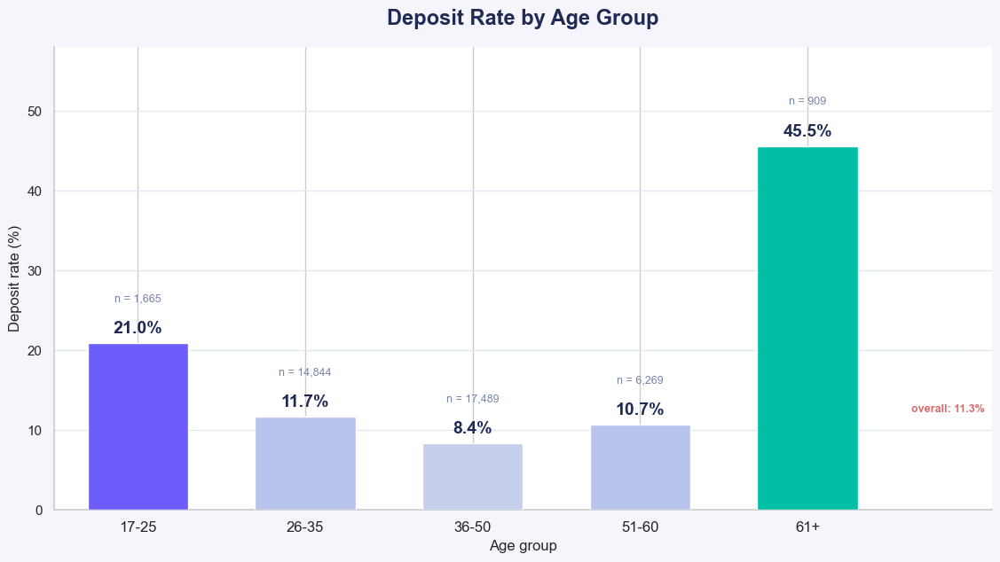

In [54]:
import matplotlib.pyplot as plt

g = (   
    data.groupby("new_age", observed=True)["deposit"]
    .agg(rate=lambda s: s.mean() * 100, n="count")
    .reindex(["17-25", "26-35", "36-50", "51-60", "61+"])  # ترتیب سنی
)
overall = data["deposit"].mean() * 100

fig, ax = plt.subplots(figsize=(11.5, 6.5))
x = range(len(g))
colors = ["#6D5DFB", "#B9C4EC", "#C5CFEA", "#B9C4EC", "#00BFA6"]
ax.bar(x, g["rate"], width=0.6, color=colors, zorder=3)

for xi, (rate, n) in zip(x, g.itertuples(index=False)):
    ax.text(xi, rate + 1.2, f"{rate:.1f}%", ha="center",
            fontsize=14, fontweight="bold", color="#1F2A55")
    ax.text(xi, rate + 5.2, f"n = {n:,}", ha="center",
            fontsize=9, color="#7A86A8")

ax.text(4.62, overall + 1.0, f"overall: {overall:.1f}%",
        color="#D96C6C", fontsize=9, ha="left", fontweight="bold")

ax.set_xticks(list(x), g.index, fontsize=12)
ax.set_xlim(-0.5, 5.1)
ax.set_ylim(0, 58)
ax.set_xlabel("Age group", fontsize=12)
ax.set_ylabel("Deposit rate (%)", fontsize=12)
ax.yaxis.grid(True, color="#E3E7F2", zorder=0)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)

ax.set_title("Deposit Rate by Age Group", fontsize=17,
             fontweight="bold", color="#1F2A55", pad=18)
plt.tight_layout()

chi2_cramers(data , "deposit" , ["new_age"])z

- age VS category


,Variable,Adjusted_P,Cramers_V,Expected_OK
0,job,0.0,0.357679,True
1,marital,0.0,0.247965,True
3,default,0.0,0.146945,False
2,education,0.0,0.144990,False
5,loan,1.0,0.009970,True
4,housing,1.0,0.009556,True


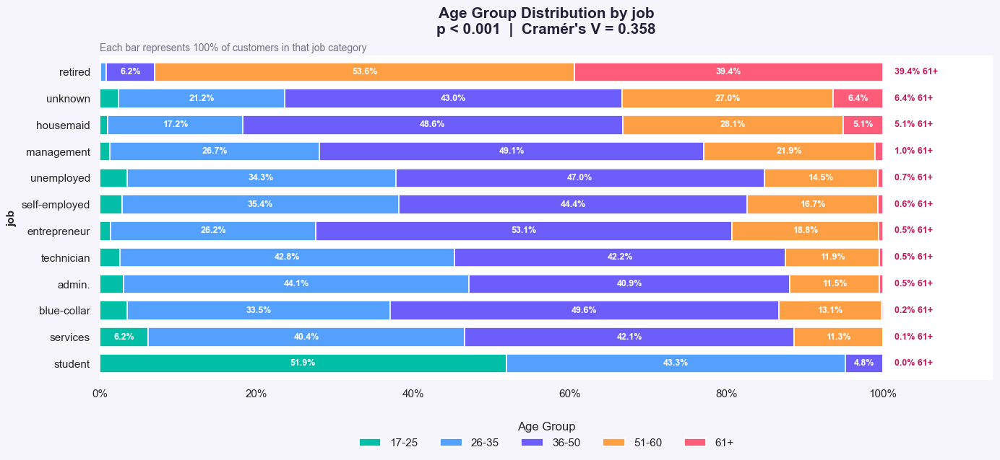

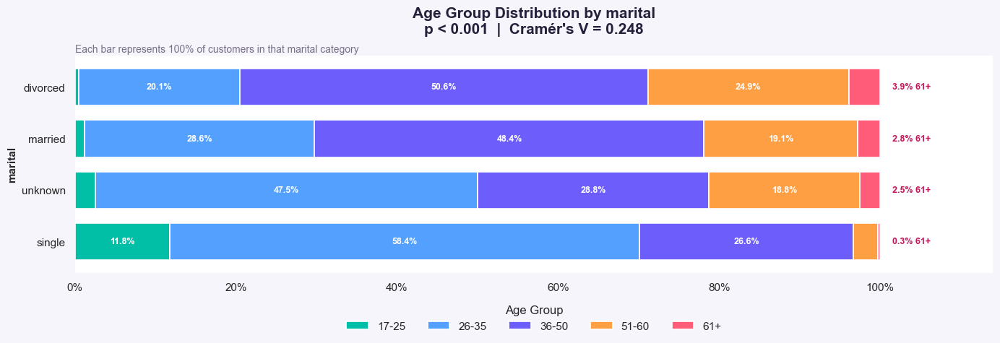

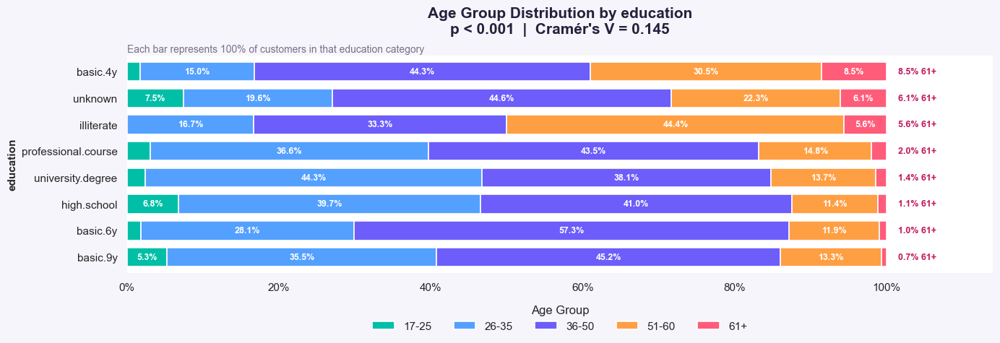

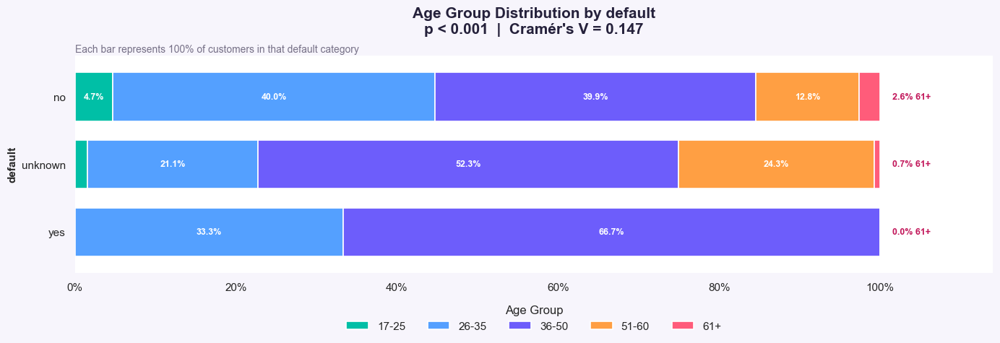

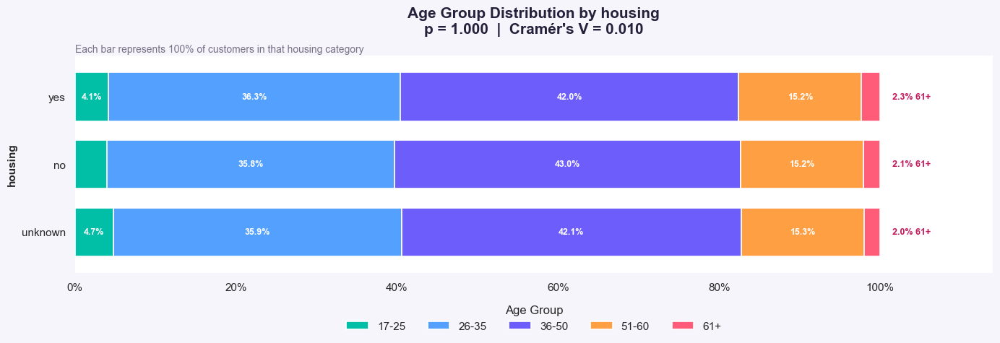

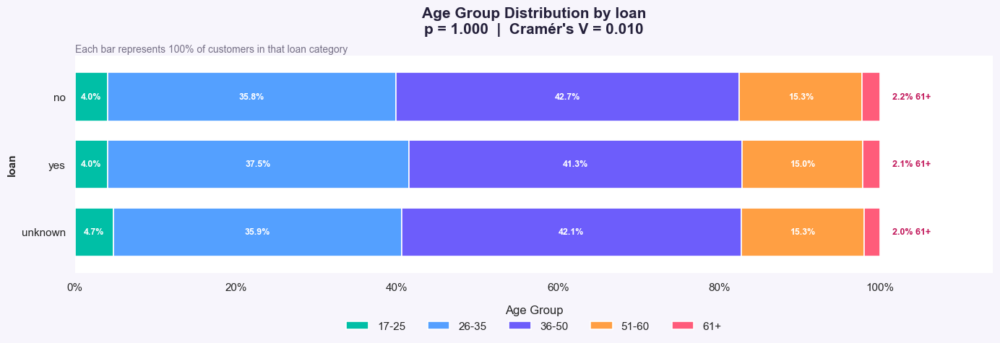

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)

# new_age هدفِ استکه، نه ردیف
categorical_columns = ["job", "marital", "education", "default",
                       "housing", "loan"]

age_order = ["17-25", "26-35", "36-50", "51-60", "61+"]
month_order = ["jan", "feb", "mar", "apr", "may", "jun",
               "jul", "aug", "sep", "oct", "nov", "dec"]

age_colors = ["#00BFA6", "#54A0FF", "#6D5DFB", "#FF9F43", "#FF5C7A"]

number_of_tests = len(categorical_columns)

results = []


for column in categorical_columns:

    # جدول تعدادهای واقعی: ردیف‌ها = دسته‌های متغیر، ستون‌ها = گروه‌های سنی
    observed = pd.crosstab(
        data[column],
        data["new_age"],
    )

    # آزمون Chi-square
    chi2, p_value, dof, expected = (
        chi2_contingency(observed)
    )

    # اصلاح Bonferroni
    adjusted_p = min(
        p_value * number_of_tests,
        1
    )

    # محاسبه Cramér's V
    n = observed.to_numpy().sum()
    rows, columns = observed.shape

    cramers_v = np.sqrt(
        chi2 / (
            n * min(
                rows - 1,
                columns - 1
            )
        )
    )

    # بررسی شرایط Expected
    expected_ok = (
        expected.min() >= 1
        and (expected < 5).mean() <= 0.20
    )

    results.append(
        {
            "Variable": column,
            "Adjusted_P": adjusted_p,
            "Cramers_V": cramers_v,
            "Expected_OK": expected_ok
        }
    )

    # تبدیل تعدادها به درصد سطری (ستون‌ها به ترتیب سنی)
    distribution = (
        observed.div(
            observed.sum(axis=1),
            axis=0
        )
        .mul(100)
        .reindex(columns=age_order)
        [age_order]
    )

    # month به ترتیب زمانی، بقیه مرتب‌شده بر اساس سهم 61+
    if column == "month":
        distribution = distribution.reindex(
            [m for m in month_order if m in distribution.index]
        )
    else:
        distribution = distribution.sort_values("61+")

    figure_height = max(
        5,
        len(distribution) * 0.55
    )

    fig, ax = plt.subplots(
        figsize=(14, figure_height)
    )

    distribution.plot(
        kind="barh",
        stacked=True,
        width=0.72,
        color=age_colors,
        edgecolor="white",
        linewidth=1.2,
        ax=ax
    )

    # نوشتن درصد داخل میله‌ها
    for container in ax.containers:

        labels = [
            f"{value:.1f}%"
            if value >= 4
            else ""
            for value in container.datavalues
        ]

        ax.bar_label(
            container,
            labels=labels,
            label_type="center",
            color="white",
            fontsize=9,
            fontweight="bold"
        )

    # نمایش درصد 61+ کنار هر میله
    for position, value in enumerate(
        distribution["61+"]
    ):

        ax.text(
            101.5,
            position,
            f"{value:.1f}% 61+",
            va="center",
            color="#C2185B",
            fontsize=9,
            fontweight="bold"
        )

    p_text = (
        "p < 0.001"
        if adjusted_p < 0.001
        else f"p = {adjusted_p:.3f}"
    )

    ax.set_title(
        (
            f"Age Group Distribution by {column}\n"
            f"{p_text}  |  Cramér's V = {cramers_v:.3f}"
        ),
        fontsize=15,
        fontweight="bold",
        color="#25213B",
        pad=22
    )

    ax.text(
        0,
        1.015,
        f"Each bar represents 100% of customers in that {column} category",
        transform=ax.transAxes,
        color="#777187",
        fontsize=10
    )

    ax.set_ylabel(
        column,
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlim(0, 114)

    ax.set_xticks(
        np.arange(0, 101, 20)
    )

    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=100)
    )

    ax.legend(
        title="Age Group",
        ncol=5,
        frameon=False,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.10)
    )

    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout()

# خلاصه‌ی همه‌ی ۷ آزمون
results = pd.DataFrame(results)
results.sort_values(by="Cramers_V" , inplace=True , ascending=False)
results


,Variable,Adjusted_P,Cramers_V
0,job,1.961047e-198,0.152830
3,default,3.130525e-88,0.099366
2,education,2.248061e-37,0.068436
1,marital,1.067054e-25,0.054646
4,housing,3.398276e-01,0.011809
5,loan,1.000000e+00,0.005167


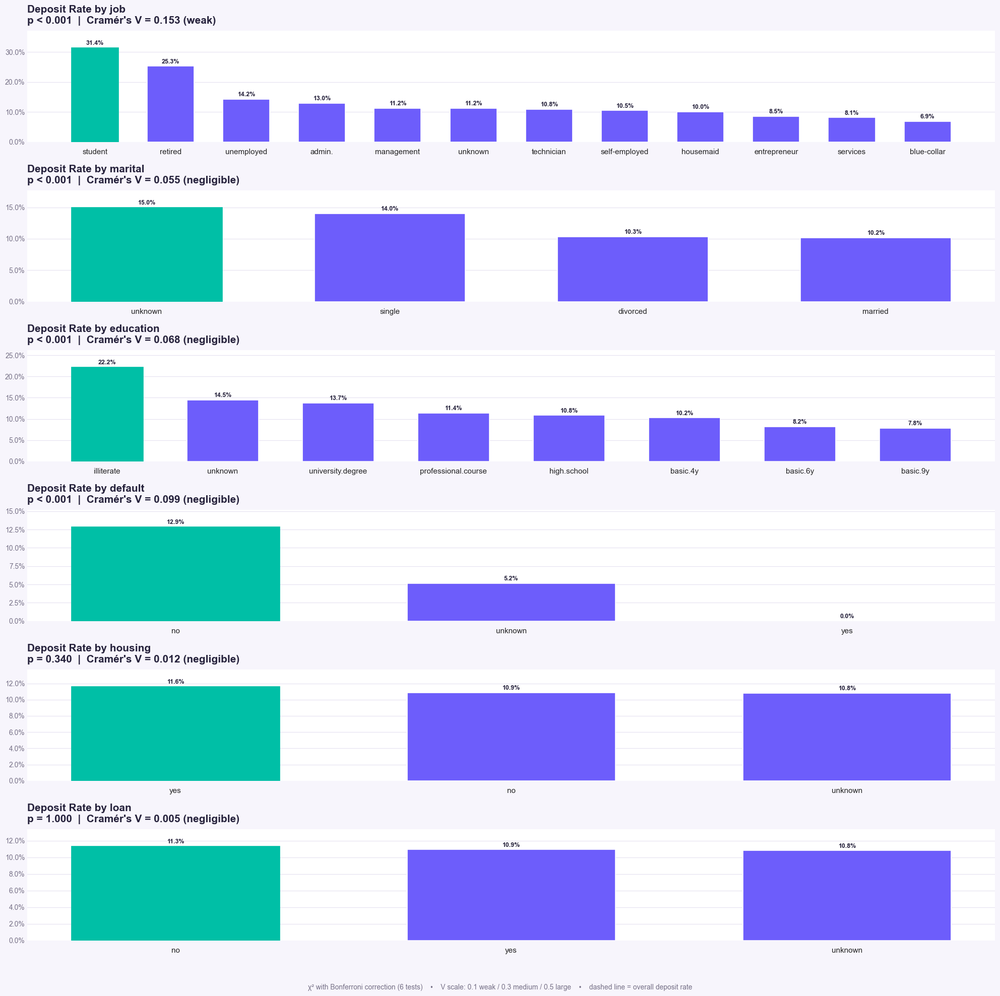

In [61]:
from scipy.stats import chi2_contingency
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)

categorical_columns = ["job", "marital", "education", "default",
                       "housing", "loan"]

number_of_tests = len(categorical_columns)
overall_rate = data["deposit"].mean() * 100

results = []

fig, axes = plt.subplots(6, 1, figsize=(20, 20))
axes = axes.flatten()

for i, col in enumerate(categorical_columns):

    ax = axes[i]

    # ---- آزمون Chi-square: فاکتور × deposit ----
    observed = pd.crosstab(data[col], data["deposit"])
    chi2, p_value, dof, expected = chi2_contingency(observed)

    # اصلاح Bonferroni
    adjusted_p = min(p_value * number_of_tests, 1)

    # محاسبه Cramér's V
    n = observed.to_numpy().sum()
    rows, columns = observed.shape
    cramers_v = np.sqrt(chi2 / (n * min(rows - 1, columns - 1)))

    v_tag = (
        "negligible" if cramers_v < 0.10
        else "weak" if cramers_v >= 0.10
        else "medium" if cramers_v < 0.30
        else "strong"
    )

    results.append({
        "Variable": col,
        "Adjusted_P": adjusted_p,
        "Cramers_V": cramers_v
    })

    # ---- نرخ سپرده ٪ برای هر دسته، مرتب‌شده ----
    a = (
        data.groupby(col)["deposit"]
        .mean()
        .mul(100)
        .reset_index()
        .sort_values("deposit", ascending=False)
    )

    bars = ax.bar(
        a[col], a["deposit"],
        width=0.62,
        color="#6D5DFB",
        edgecolor="white",
        linewidth=1.2
    )
    bars[0].set_color("#00BFA6")   # دسته‌ی بالاترین

    # برچسب ٪ روی هر میله
    ax.bar_label(
        bars,
        labels=[f"{v:.1f}%" for v in a["deposit"]],
        label_type="edge",
        color="#25213B",
        fontsize=9,
        fontweight="bold",
        padding=2
    )

    p_text = (
        "p < 0.001"
        if adjusted_p < 0.001
        else f"p = {adjusted_p:.3f}"
    )

    ax.set_title(
        (
            f"Deposit Rate by {col}\n"
            f"{p_text}  |  Cramér's V = {cramers_v:.3f} ({v_tag})"
        ),
        fontsize=15,
        fontweight="bold",
        color="#25213B",
        loc="left",
        pad=10
    )

    ax.set_ylim(0, a["deposit"].max() * 1.18)
    ax.tick_params(axis="y", labelsize=10, length=0, colors="#777187")
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.grid(axis="y", color="#E5E1F0", lw=0.8)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.text(
    0.5, 0.004,
    "χ² with Bonferroni correction (6 tests)    •    V scale: 0.1 weak / 0.3 medium / 0.5 large    •    dashed line = overall deposit rate",
    ha="center", fontsize=10, color="#777187"
)

plt.tight_layout(rect=(0, 0.03, 1, 0.99))

# خلاصه‌ی همه‌ی ۶ آزمون
results = pd.DataFrame(results)
results.sort_values(by="Cramers_V", inplace=True, ascending=False)
results



- age VS numeric

C:\Users\ASUS\AppData\Local\Temp\ipykernel_6016\1960220701.py:345: UserWarning: Glyph 10022 (\N{BLACK FOUR POINTED STAR}) missing from font(s) Arial.
  plt.tight_layout(rect=(0, 0.01, 1, 0.985))
C:\Users\ASUS\AppData\Local\Temp\ipykernel_6016\1960220701.py:345: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout(rect=(0, 0.01, 1, 0.985))
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\IPython\core\events.py:100: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  func(*args, **kwargs)
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\IPython\core\events.py:100: UserWarning: Glyph 10022 (\N{BLACK FOUR POINTED STAR}) missing from font(s) Arial.
  func(*args, **kwargs)
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10022 (\N{BLACK FOUR POINTED STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\ASUS\AppData\Roamin

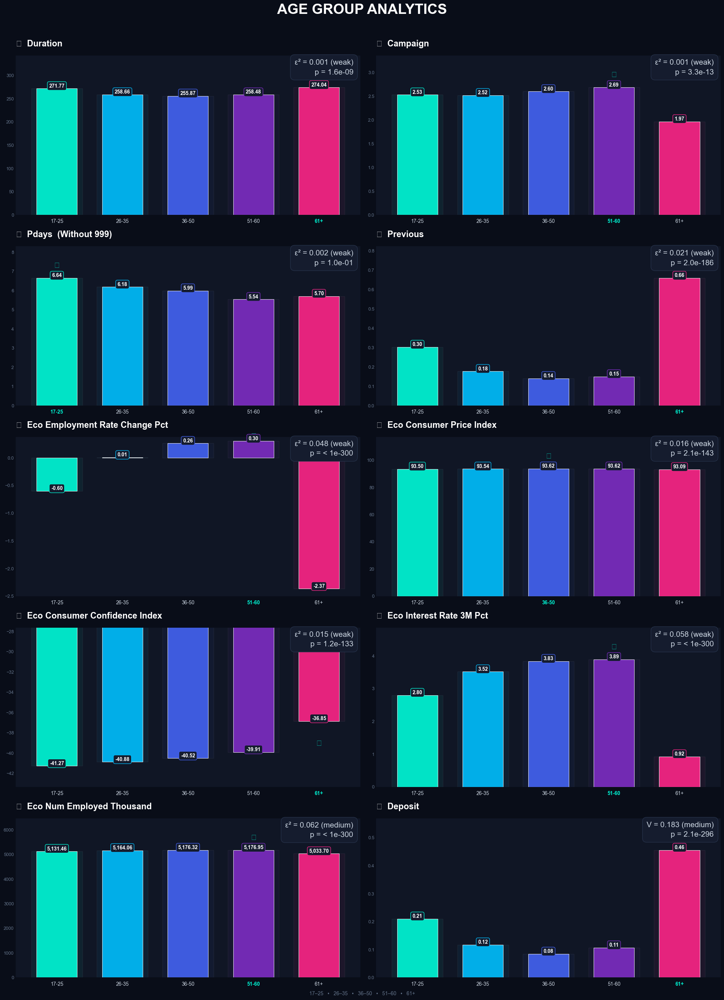

In [14]:
import math
from scipy.stats import kruskal, chi2_contingency

# interpret effect size (same ladder you use)
def effect_label(kind, x):
    if kind == "eps2":          # 0.01 weak / 0.06 medium / 0.14 large
        if x < 0.06:
            return "weak"
        if x < 0.14:
            return "medium"
        return "large"
    else:                       # Cramer's V: 0.1 / 0.3 / 0.5
        if x < 0.10:
            return "weak"
        if x < 0.30:
            return "medium"
        return "large"


age_order = ['17-25', '26-35', '36-50', '51-60', '61+']
numeric_cols = []


for col in data.select_dtypes(include="number").columns : 
    if col == "new_age" : 
        continue 
    elif col == "age" : 
        continue 

    numeric_cols.append(col)


# pdays: without the sentinel value (999 = had no prior contact)
pdays_no999 = data.loc[data["pdays"] != 999]


n = len(numeric_cols)
ncols = 2
nrows = math.ceil(n / ncols)


fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(20, nrows * 5.5),
    facecolor="#090D18"
)

axes = np.atleast_1d(axes).flatten()

# Colors
gradient = [
    "#00F5D4",
    "#00BBF9",
    "#4361EE",
    "#7B2CBF",
    "#F72585"
]

# =========================================================
# Loop
# =========================================================

for i, col in enumerate(numeric_cols):

    ax = axes[i]

    pretty_name = col.replace("_", " ").title()
    suffix = "  (Without 999)" if col == "pdays" else ""

    # -----------------------------------------
    # Mean by age  (pdays is calculated without 999)
    # -----------------------------------------

    source = pdays_no999 if col == "pdays" else data

    temp = (
        source.groupby("new_age")[col]
        .mean()
        .reindex(age_order)
    )

    values = temp.to_numpy(dtype=float)


    if np.all(np.isnan(values)):

        ax.set_facecolor("#101625")

        ax.text(
            0.5,
            0.5,
            "NO DATA\nFOR THESE AGE GROUPS",
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=13,
            fontweight="bold",
            color="#FF6B8A"
        )

        ax.set_title(
            f"✦ {pretty_name}{suffix}",
            loc="left",
            fontsize=17,
            fontweight="bold",
            color="white",
            pad=18
        )

        ax.axis("off")
        continue

    plot_values = np.nan_to_num(values, nan=0.0)

    ax.set_facecolor("#101625")

    bars = ax.bar(
        age_order,
        plot_values,
        width=0.62,
        color=gradient,
        edgecolor="white",
        linewidth=0.8,
        alpha=0.92,
        zorder=3
    )

    for bar, value, color, original_value in zip(
        bars,
        plot_values,
        gradient,
        values
    ):

        x = bar.get_x() + bar.get_width() / 2

        # Glow
        ax.bar(
            x,
            value,
            width=0.78,
            color=color,
            alpha=0.06,
            zorder=2
        )

        # Value
        if np.isnan(original_value):
            label = "N/A"
        else:
            label = f"{original_value:,.2f}"

        ax.text(
            x,
            value,
            label,
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            color="white",
            bbox=dict(
                boxstyle="round,pad=0.35",
                facecolor="#151C2E",
                edgecolor=color,
                linewidth=1
            ),
            zorder=5
        )

    ax.set_title(
        f"✦  {pretty_name}{suffix}",
        loc="left",
        fontsize=17,
        fontweight="bold",
        color="white",
        pad=18
    )


    ax.set_axisbelow(True)

    # =====================================================
    # Axis
    # =====================================================

    ax.tick_params(
        axis="x",
        colors="#CBD5E1",
        labelsize=10,
        length=0,
        pad=8
    )

    ax.tick_params(
        axis="y",
        colors="#64748B",
        labelsize=9,
        length=0
    )

    for spine in ax.spines.values():
        spine.set_visible(False)

    # =====================================================
    # Find the Maximum without errors
    # =====================================================

    valid_mask = ~np.isnan(values)

    if np.any(valid_mask):

        valid_values = values[valid_mask]
        valid_indices = np.where(valid_mask)[0]

        max_idx = valid_indices[np.argmax(valid_values)]
        max_value = values[max_idx]

        # room at the top for the stats box
        if max_value > 0:
            ax.set_ylim(top=max_value * 1.25)
        else:
            ax.set_ylim(top=max_value * 0.75)

        # Highlight the label
        ax.get_xticklabels()[max_idx].set_color("#00F5D4")
        ax.get_xticklabels()[max_idx].set_fontweight("bold")

        # Star
        ax.text(
            max_idx,
            plot_values[max_idx] * 1.07,
            "★",
            ha="center",
            va="bottom",
            fontsize=16,
            color="#00F5D4"
        )

        # -------------------------------------------------
        # Appropriate test for this variable
        # -------------------------------------------------

        if col == "deposit":
            # binary (0/1) -> chi-square + Cramer's V
            ct = (
                pd.crosstab(source["new_age"], source[col])
                .reindex(age_order)
                .fillna(0)
            )
            ct = ct.loc[ct.sum(axis=1) > 0]
            chi2_val, p_val, dof_val, _ = chi2_contingency(ct)
            cramers_v = (chi2_val / (ct.values.sum() * (min(ct.shape) - 1))) ** 0.5
            stat_line = f"chi2: X² = {chi2_val:.1f} (df = {dof_val})"
            effect_line = f"V = {cramers_v:.3f} ({effect_label('v', cramers_v)})"
        else:
            # continuous -> Kruskal-Wallis + epsilon squared
            groups = [
                source.loc[source["new_age"] == g, col]
                .dropna()
                .to_numpy(dtype=float)
                for g in age_order
            ]
            groups = [g for g in groups if len(g) > 0]

            if len(groups) >= 2:
                h_val, p_val = kruskal(*groups)
                k_groups = len(groups)
                n_total = int(sum(len(g) for g in groups))
                eps2 = max(0.0, (h_val - k_groups + 1) / (n_total - k_groups))
                stat_line = f"Kruskal: H = {h_val:.1f} (k = {k_groups})"
                effect_line = f"ε² = {eps2:.3f} ({effect_label('eps2', eps2)})"
            else:
                p_val = float("nan")
                stat_line = "test: N/A"
                effect_line = "effect: N/A"

        if np.isnan(p_val):
            p_txt = "N/A"
        elif p_val < 1e-300:
            p_txt = "< 1e-300"
        else:
            p_txt = f"{p_val:.1e}"

        # -------------------------------------------------
        # Statistics + test
        # -------------------------------------------------

        mean_value = np.nanmean(values)

        ax.text(
            0.98,
            0.98,

            f"{effect_line}\n"
            f"p = {p_txt}",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=15,
            linespacing=1.5,
            color="#CBD5E1",
            bbox=dict(
                boxstyle="round,pad=0.55",
                facecolor="#151C2E",
                edgecolor="#26324A",
                linewidth=1
            ),
            zorder=6
        )
        ax.yaxis.grid(False)
        ax.xaxis.grid(False)

# =========================================================
# Delete the empty subplots
# =========================================================

for j in range(n, len(axes)):
    fig.delaxes(axes[j])

# =========================================================
# Main title
# =========================================================

fig.suptitle(
    "AGE GROUP ANALYTICS",
    fontsize=28,
    fontweight="bold",
    color="white",
    y=0.995
)
    

fig.text(
    0.5,
    0.008,
    "17–25   •   26–35   •   36–50   •   51–60   •   61+",
    ha="center",
    fontsize=10,
    color="#64748B"
)


plt.tight_layout(rect=(0, 0.01, 1, 0.985))

<div dir="rtl">
«در نمونه‌ی ما، مشتریان 61+ بیشتر در دوره‌هایی با شاخص‌های اقتصادی متفاوت مشاهده شده‌اند.»

یادداشت: نرخ بالای deposit در گروه 61+ دلیلش حالت شخصی این افراد است (بازنشسته، دارای پس‌انداز، کم‌ریسک)؛ اما ستون num_employed فقط عدد ملیِ اشتغال در روز تماسِ بانک با هر گروه را نشان می‌دهد. پس «deposit زیاد» و «اشتغال ملی پایین» دو موضوع جداگانه‌اند که در دو ستونِ کنار هم قرار گرفته‌اند — نه علت یکدیگر.
یه تشبیه که همه‌چیز رو جمع می‌کنه:

    عکسِ جمع‌فامیلی بگیر. تو پس‌زمینه‌ی عکس داره بارون می‌باره.
    این یعنی «فامیل دوست دارن بارون بباره»؟ نه. یعنی «بارون باعث شد جمع بشن»؟ نه.
    یعنی «روز عکس، هوا بارونی بود» — تمام.

</div>

C:\Users\ASUS\AppData\Local\Temp\ipykernel_11016\2900367990.py:245: UserWarning: Glyph 10022 (\N{BLACK FOUR POINTED STAR}) missing from font(s) Arial.
  plt.tight_layout(rect=(0, 0.02, 1, 0.925))
C:\Users\ASUS\AppData\Local\Temp\ipykernel_11016\2900367990.py:245: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout(rect=(0, 0.02, 1, 0.925))
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\IPython\core\events.py:100: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  func(*args, **kwargs)
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\IPython\core\events.py:100: UserWarning: Glyph 10022 (\N{BLACK FOUR POINTED STAR}) missing from font(s) Arial.
  func(*args, **kwargs)
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10022 (\N{BLACK FOUR POINTED STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\ASUS\AppData\Roam

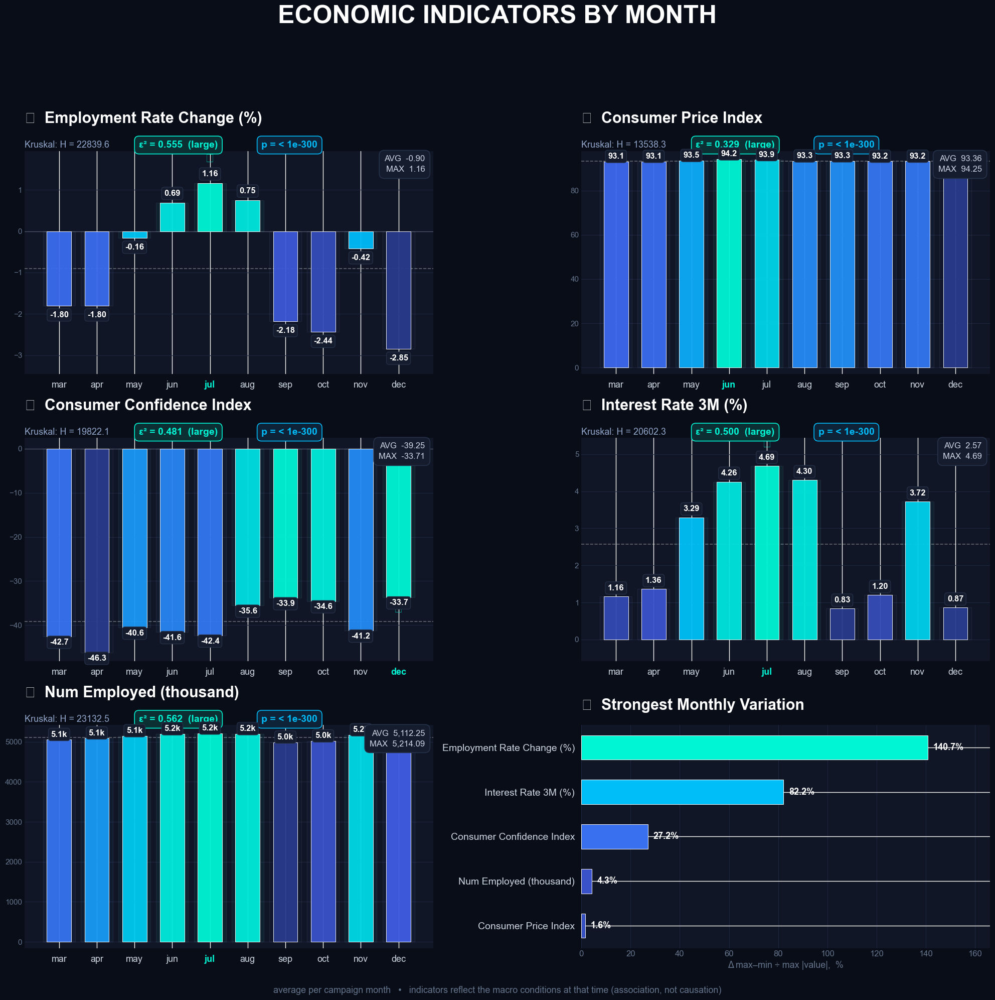

In [8]:
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import kruskal

# ---------- constants ----------
economy = [
    "eco_employment_rate_change_pct",
    "eco_consumer_price_index",
    "eco_consumer_confidence_index",
    "eco_interest_rate_3m_pct",
    "eco_num_employed_thousand",
]

month_order = ["jan", "feb", "mar", "apr", "may", "jun",
               "jul", "aug", "sep", "oct", "nov", "dec"]

display_names = {
    "eco_employment_rate_change_pct":  "Employment Rate Change (%)",
    "eco_consumer_price_index":        "Consumer Price Index",
    "eco_consumer_confidence_index":   "Consumer Confidence Index",
    "eco_interest_rate_3m_pct":        "Interest Rate 3M (%)",
    "eco_num_employed_thousand":       "Num Employed (thousand)",
}

# ---------- helpers ----------
def fmt(x):
    if abs(x) >= 1000:
        return f"{x/1000:.1f}k"
    if abs(x) >= 100:
        return f"{x:.0f}"
    if abs(x) >= 10:
        return f"{x:.1f}"
    return f"{x:.2f}"

def effect_label(x):   # 0.01 weak / 0.06 medium / 0.14 large
    if x < 0.06:
        return "weak"
    if x < 0.14:
        return "medium"
    return "large"

cmap = LinearSegmentedColormap.from_list(
    "neon", ["#141B3D", "#4361EE", "#00BBF9", "#00F5D4"]
)

# monthly means (in calendar order)
monthly = {}
for col in economy:
    m = (
        data.groupby("month")[col]
        .mean()
        .reindex(month_order)
        .dropna()
    )
    monthly[col] = m

# which variable swings the most across months (last panel)
swing = pd.Series({
    col: (m.max() - m.min()) / m.abs().max() * 100
    for col, m in monthly.items()
})
swing = swing.sort_values(ascending=False)

# ---------- figure ----------
fig, axes = plt.subplots(3, 2, figsize=(20, 20), facecolor="#090D18")
axes = np.atleast_1d(axes).flatten()

for i, col in enumerate(economy):
    ax = axes[i]
    ax.set_facecolor("#101625")

    m = monthly[col]
    months = m.index.tolist()
    values = m.to_numpy(dtype=float)
    pos = list(range(len(months)))

    # ---------- bars (color = value) ----------
    span = values.max() - values.min()
    t = (values - values.min()) / (span + 1e-9)
    bars = ax.bar(
        pos,
        values,
        width=0.65,
        color=[cmap(0.15 + 0.85 * x) for x in t],
        edgecolor="white",
        linewidth=0.7,
        alpha=0.95,
        zorder=3,
    )

    # glow
    for x, v, c in zip(pos, values, t):
        ax.bar(x, v, width=0.85, color=cmap(0.15 + 0.85 * c),
               alpha=0.06, zorder=2)

    # reference lines
    ax.axhline(values.mean(), color="white", alpha=0.35, ls="--", lw=1.2, zorder=2)
    if values.min() < 0:
        ax.axhline(0, color="white", alpha=0.22, lw=1, zorder=2)

    # ---------- value labels ----------
    pad = max(span * 0.15, abs(values.max()) * 0.03, 0.5)
    for x, v in zip(pos, values):
        if v >= 0:
            ax.text(x, v + pad * 0.22, fmt(v), ha="center", va="bottom",
                    fontsize=12, fontweight="bold", color="white",
                    bbox=dict(boxstyle="round,pad=0.3",
                              facecolor="#151C2E", edgecolor="#26324A",
                              linewidth=0.9), zorder=5)
        else:
            ax.text(x, v - pad * 0.22, fmt(v), ha="center", va="top",
                    fontsize=12, fontweight="bold", color="white",
                    bbox=dict(boxstyle="round,pad=0.3",
                              facecolor="#151C2E", edgecolor="#26324A",
                              linewidth=0.9), zorder=5)

    # ---------- title ----------
    name = display_names.get(col, col.replace("_", " ").title())
    ax.set_title(f"✦  {name}", loc="left", fontsize=22,
                 fontweight="bold", color="white", pad=40)

    # ---------- axes ----------
    ax.set_xticks(pos)
    ax.set_xticklabels(months, fontsize=13, color="#CBD5E1")
    ax.tick_params(axis="y", colors="#64748B", labelsize=11, length=0)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#1E2740", lw=0.8, zorder=0)
    for s in ax.spines.values():
        s.set_visible(False)

    # ---------- star on the peak month ----------
    max_i = int(np.argmax(values))
    v_max = values.max()
    ax.get_xticklabels()[max_i].set_color("#00F5D4")
    ax.get_xticklabels()[max_i].set_fontweight("bold")
    if v_max >= 0:
        ax.text(max_i, v_max + pad * 0.75, "★", ha="center",
                va="bottom", fontsize=18, color="#00F5D4")
    else:
        ax.text(max_i, v_max - pad * 0.75, "★", ha="center",
                va="top", fontsize=18, color="#00F5D4")

    # ---------- ylim ----------
    lo = min(0.0, values.min()) - pad
    hi = max(0.0, values.max()) + pad * 1.3
    ax.set_ylim(lo, hi)

    # ---------- Kruskal-Wallis across the 12 months ----------
    groups = [
        data.loc[data["month"] == mo, col].dropna().to_numpy(dtype=float)
        for mo in month_order
    ]
    groups = [g for g in groups if len(g) > 0]
    h_val, p_val = kruskal(*groups)
    k_g = len(groups)
    n_tot = int(sum(len(g) for g in groups))
    eps2 = max(0.0, (h_val - k_g + 1) / (n_tot - k_g))
    p_txt = "< 1e-300" if p_val < 1e-300 else f"{p_val:.1e}"

    # ---------- test badges under the title ----------
    # H (muted)
    ax.text(
        0.0, 1.006,
        f"Kruskal: H = {h_val:.1f}",
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=13, color="#8FA3C7"
    )
    # effect size (neon teal badge)
    ax.text(
        0.28, 1.006,
        f"ε² = {eps2:.3f}  ({effect_label(eps2)})",
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=14, fontweight="bold", color="#00F5D4",
        bbox=dict(boxstyle="round,pad=0.45",
                  facecolor="#0B2F33", edgecolor="#00F5D4",
                  linewidth=1.2)
    )
    # p-value (neon blue badge)
    ax.text(
        0.58, 1.006,
        f"p = {p_txt}",
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=14, fontweight="bold", color="#00BBF9",
        bbox=dict(boxstyle="round,pad=0.45",
                  facecolor="#0E2238", edgecolor="#00BBF9",
                  linewidth=1.2)
    )

    # ---------- stats box ----------
    ax.text(
        0.98, 0.98,
        f"AVG  {values.mean():,.2f}\n"
        f"MAX  {values.max():,.2f}",
        transform=ax.transAxes,
        ha="right", va="top",
        fontsize=12, linespacing=1.5,
        color="#CBD5E1",
        bbox=dict(boxstyle="round,pad=0.6",
                  facecolor="#151C2E", edgecolor="#26324A",
                  linewidth=1.2),
        zorder=6,
    )

# ---------- last panel: strongest monthly variation ----------
ax = axes[len(economy)]
ax.set_facecolor("#101625")

norm = (swing - swing.min()) / (swing.max() - swing.min() + 1e-9)
ax.barh(range(len(swing)), swing.values,
        height=0.55,
        color=[cmap(0.25 + 0.75 * x) for x in norm],
        edgecolor="white", linewidth=0.7, zorder=3)

ax.set_yticks(range(len(swing)))
ax.set_yticklabels(
    [display_names.get(c, c) for c in swing.index],
    fontsize=14, color="#CBD5E1"
)
ax.invert_yaxis()
for i, v in enumerate(swing.values):
    ax.text(v + swing.max() * 0.015, i, f"{v:.1f}%",
            va="center", fontsize=13, fontweight="bold", color="white")
ax.set_xlim(0, swing.max() * 1.18)

ax.set_title("✦  Strongest Monthly Variation", loc="left",
             fontsize=22, fontweight="bold", color="white", pad=22)
ax.set_xlabel("Δ max–min ÷ max |value|,  %", fontsize=13, color="#64748B")
ax.tick_params(axis="x", colors="#64748B", labelsize=12, length=0)
ax.grid(axis="x", color="#1E2740", lw=0.8, zorder=0)
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)

# ---------- main title ----------
fig.suptitle("ECONOMIC INDICATORS BY MONTH",
             fontsize=36, fontweight="bold", color="white", y=0.99)
fig.text(
    0.5, 0.006,
    "average per campaign month   •   indicators reflect the macro conditions at that time (association, not causation)",
    ha="center", fontsize=13, color="#64748B"
)

plt.tight_layout(rect=(0, 0.02, 1, 0.925))


<div dir='rtl'>
- نمودار آخر نشان دهنده میزان تغییرات در هر زمان , پس متغیرهای اقتصادی به یک اندازه در طول زمان تغییر نکرده‌اند
</div>

- آیا ماه و 5 متغیر اقتصادی در تغییرات نرخ سپرده گذاری تاثیر دارد (مهم ترین عامل)  

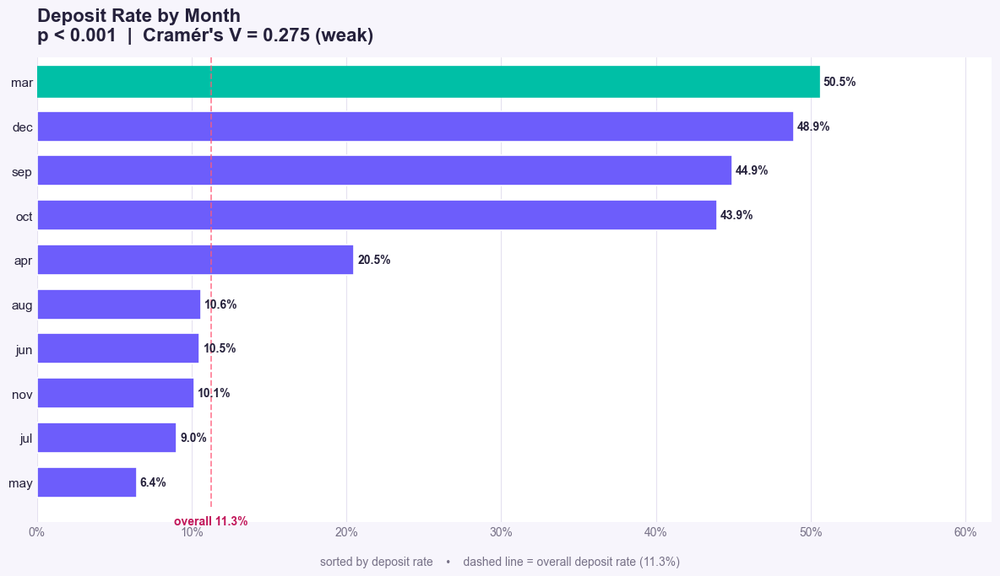

In [ ]:
from scipy.stats import chi2_contingency
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)

# ---------- نرخ سپرده ٪ برای هر ماه ----------
# (مرتب‌سازی صعودی → ماهِ قوی‌ترین در بالایی چارت، مثل بقیه‌ی فیگورها)
a = (
    data.groupby("month")["deposit"]
    .mean()
    .mul(100)
    .reset_index()
    .sort_values("deposit", ascending=True)
)

overall_rate = data["deposit"].mean() * 100

# ---------- آزمون: chi2 (month × deposit) ----------
observed = pd.crosstab(data["month"], data["deposit"])
chi2, p_value, dof, expected = chi2_contingency(observed)

n = observed.to_numpy().sum()
rows, columns = observed.shape
cramers_v = np.sqrt(chi2 / (n * min(rows - 1, columns - 1)))
v_tag = (
    "negligible" if cramers_v < 0.10
    else "weak" if cramers_v < 0.30
    else "moderate" if cramers_v < 0.50
    else "strong"
)

p_text = ("p < 0.001" if p_value < 0.001 else f"p = {p_value:.3f}")

# ---------- figure ----------
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    a["month"], a["deposit"],
    height=0.68,
    color="#6D5DFB",
    edgecolor="white",
    linewidth=1.2
)
bars[-1].set_color("#00BFA6")   # ماهِ بالاترین

# برچسب ٪ روی هر میله
ax.bar_label(
    bars,
    labels=[f"{v:.1f}%" for v in a["deposit"]],
    label_type="edge",
    color="#25213B",
    fontsize=10,
    fontweight="bold",
    padding=3
)

# خط مرجع: نرخ کلی
ax.vlines(
    overall_rate, -0.55, len(a) - 0.45,
    color="#FF5C7A", ls="--", lw=1.3, alpha=0.75
)
ax.text(
    overall_rate, -0.75,
    f"overall {overall_rate:.1f}%",
    ha="center", va="top",
    color="#C2185B", fontsize=10, fontweight="bold"
)

ax.set_title(
    f"Deposit Rate by Month\n{p_text}  |  Cramér's V = {cramers_v:.3f} ({v_tag})",
    fontsize=16, fontweight="bold", color="#25213B",
    loc="left", pad=14
)

ax.set_xlim(0, a["deposit"].max() * 1.22)
ax.set_ylim(-0.9, len(a) - 0.45)
ax.tick_params(axis="y", labelsize=11, length=0, colors="#25213B")
ax.tick_params(axis="x", labelsize=10, length=0, colors="#777187")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.grid(axis="x", color="#E5E1F0", lw=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_visible(False)

fig.text(
    0.5, 0.01,
    f"sorted by deposit rate    •    dashed line = overall deposit rate ({overall_rate:.1f}%)",
    ha="center", fontsize=10, color="#777187"
)

plt.tight_layout(rect=(0, 0.03, 1, 0.98))



- month VS category

,job,deposit
8,student,31.428571
5,retired,25.261932
10,unemployed,14.201183
0,admin.,12.966695
4,management,11.217510
11,unknown,11.212121
9,technician,10.832468
6,self-employed,10.485574
3,housemaid,10.000000
2,entrepreneur,8.516484


contact
cellular     14.738856
telephone     5.232365
Name: deposit, dtype: float64

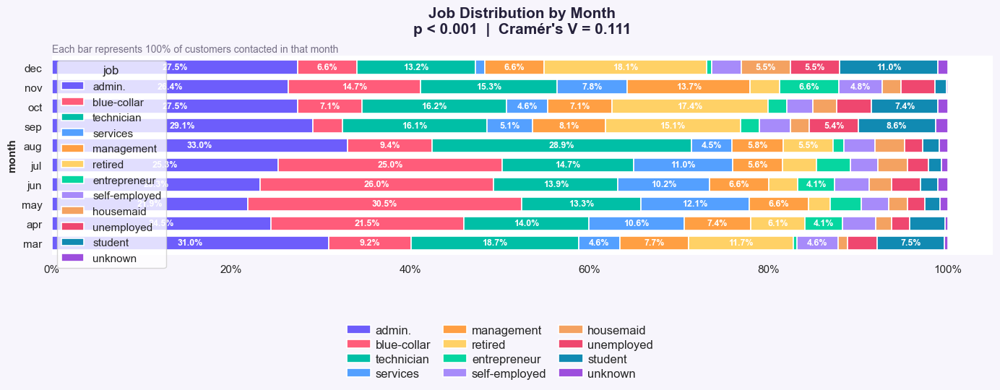

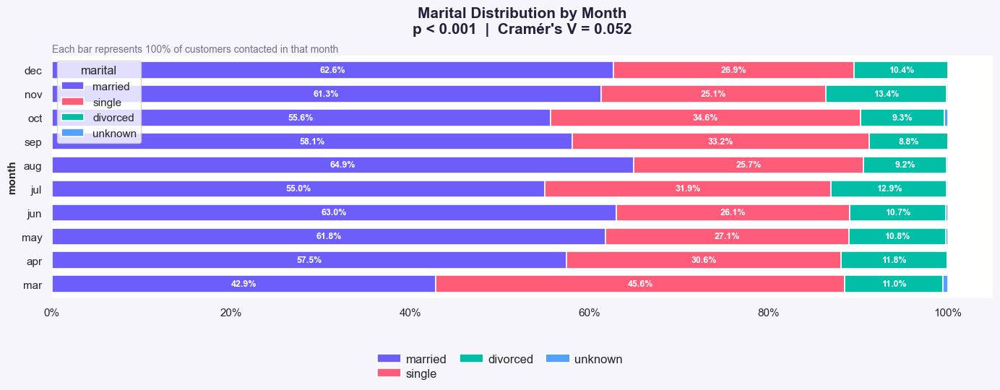

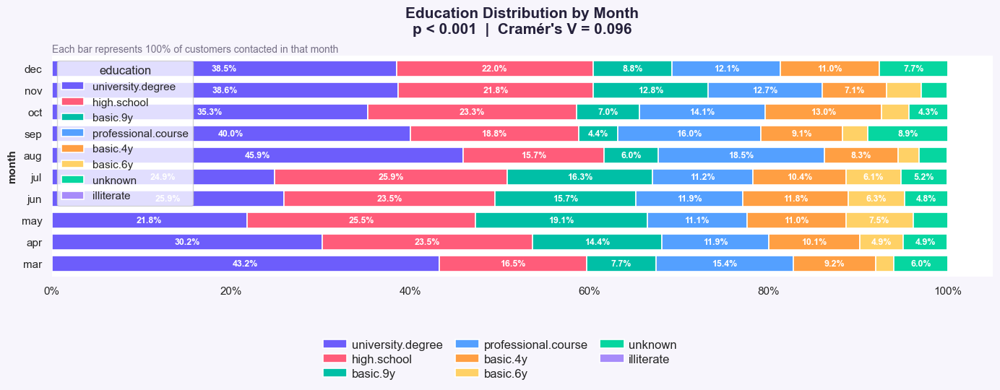

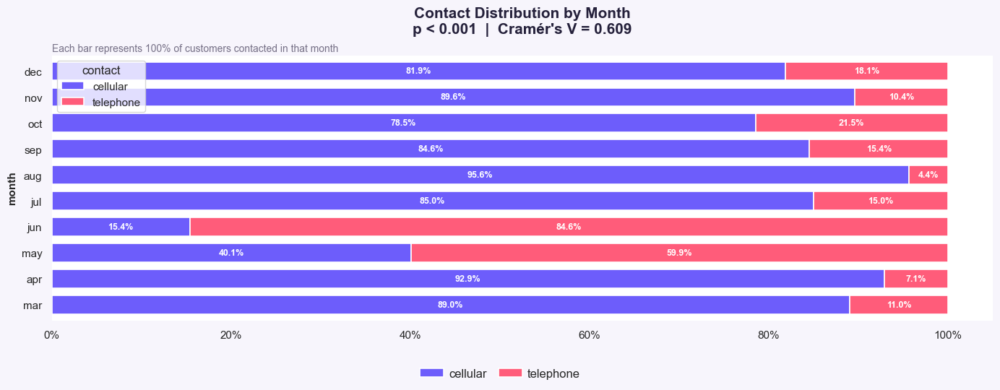

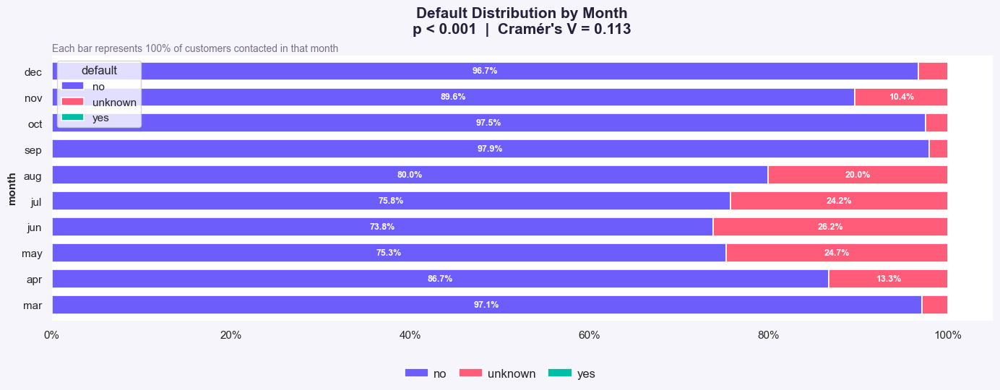

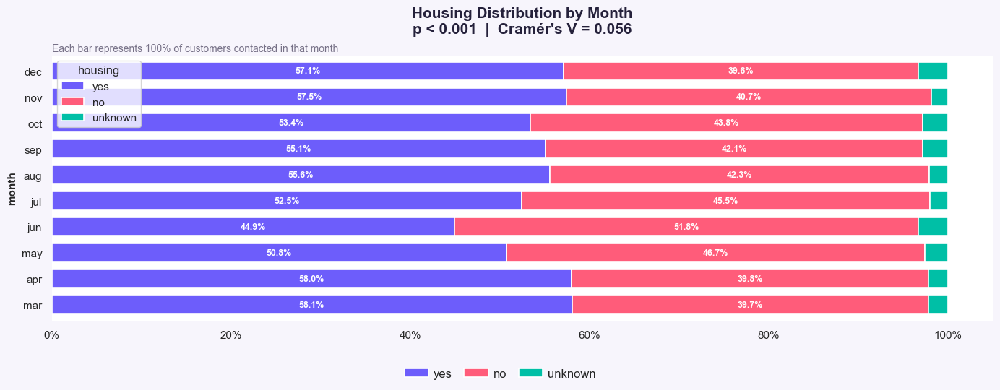

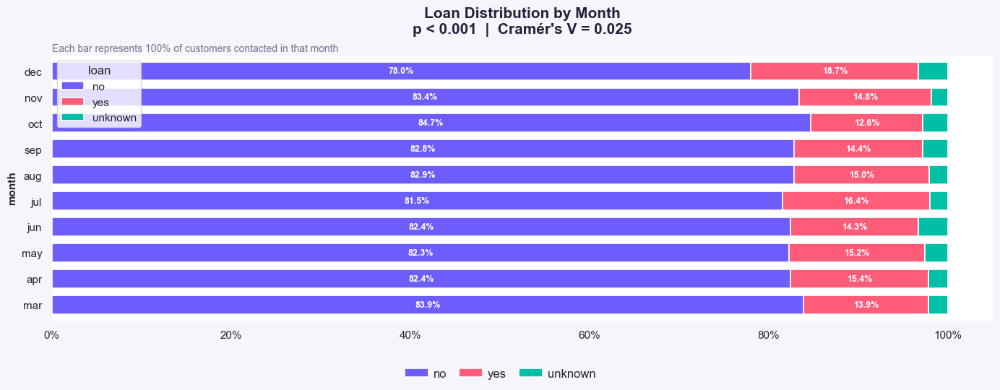

In [ ]:
from scipy.stats import chi2_contingency
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)

categorical_columns = ["job", "marital", "education", "contact",
                        "default", "housing", "loan"]

month_order = ["jan", "feb", "mar", "apr", "may", "jun",
               "jul", "aug", "sep", "oct", "nov", "dec"]

palette = [
    "#6D5DFB", "#FF5C7A", "#00BFA6", "#54A0FF",
    "#FF9F43", "#FFD166", "#06D6A0", "#A78BFA",
    "#F4A261", "#EF476F", "#118AB2", "#9D4EDD"
]

number_of_tests = len(categorical_columns)

results = []


for column in categorical_columns:

    # جدول تعدادهای واقعی (برای آزمون)
    observed = pd.crosstab(
        data[column],
        data["month"],
    )

    # آزمون Chi-square
    chi2, p_value, dof, expected = (
        chi2_contingency(observed)
    )

    # اصلاح Bonferroni
    adjusted_p = min(
        p_value * number_of_tests,
        1
    )

    # محاسبه Cramér's V
    n = observed.to_numpy().sum()
    rows, columns = observed.shape

    cramers_v = np.sqrt(
        chi2 / (
            n * min(
                rows - 1,
                columns - 1
            )
        )
    )

    # بررسی شرایط Expected
    expected_ok = (
        expected.min() >= 1
        and (expected < 5).mean() <= 0.20
    )

    results.append(
        {
            "Variable": column,
            "Adjusted_P": adjusted_p,
            "Cramers_V": cramers_v,
        }
    )

    # درصد سطری: ردیف‌ها = ماه‌ها (زمانی)، ستون‌ها = دسته‌های فاکتور
    # (دسته‌ها به ترتیب فراوانی کل → بزرگ‌ترین پایینِ استک)
    category_order = observed.sum(axis=1).sort_values(ascending=False).index

    distribution = (
        observed.T
        .div(observed.T.sum(axis=1), axis=0)
        .mul(100)
        [category_order]
        .reindex([m for m in month_order if m in observed.columns])
    )

    figure_height = max(
        5,
        len(distribution) * 0.55
    )

    fig, ax = plt.subplots(
        figsize=(14, figure_height)
    )

    distribution.plot(
        kind="barh",
        stacked=True,
        width=0.72,
        color=palette[:len(category_order)],
        edgecolor="white",
        linewidth=1.2,
        ax=ax
    )

    # نوشتن درصد داخل میله‌ها
    for container in ax.containers:

        labels = [
            f"{value:.1f}%"
            if value >= 4
            else ""
            for value in container.datavalues
        ]

        ax.bar_label(
            container,
            labels=labels,
            label_type="center",
            color="white",
            fontsize=9,
            fontweight="bold"
        )

    p_text = (
        "p < 0.001"
        if adjusted_p < 0.001
        else f"p = {adjusted_p:.3f}"
    )

    ax.set_title(
        (
            f"{column.replace('_', ' ').title()} Distribution by Month\n"
            f"{p_text}  |  Cramér's V = {cramers_v:.3f}"
        ),
        fontsize=15,
        fontweight="bold",
        color="#25213B",
        pad=22
    )

    ax.text(
        0,
        1.015,
        "Each bar represents 100% of customers contacted in that month",
        transform=ax.transAxes,
        color="#777187",
        fontsize=10
    )

    ax.set_ylabel(
        "month",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlim(0, 105)

    ax.set_xticks(
        np.arange(0, 101, 20)
    )

    ax.xaxis.set_major_formatter(
        PercentFormatter(xmax=100)
    )

    # legend (تعداد ستون‌ها بر اساس تعداد دسته‌ها)
    k = len(category_order)
    ncol = 3 if k > 3 else k
    n_rows = int(np.ceil(k / ncol))

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.005),
        ncol=ncol,
        frameon=False,
        fontsize=12,
        columnspacing=1.0,
        handletextpad=0.4,
        labelspacing=0.3,
        borderpad=0.3
    )

    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout(rect=(0, 0.04 + 0.055 * n_rows, 1, 1))

# توی کدوم شغل بیشترین نرخ سپرده گذاری رو داریم
display(data.groupby("job").deposit.mean().mul(100).reset_index().sort_values(by="deposit" , ascending=False))

# 31 درصد از کل دانشجو ها سپرده گذاری کردند
# 25 درصد از کل بازنشسته ها سپرده گذاری کردن

display(data.groupby("contact").deposit.mean().mul(100))

- عوامل مختلف تا چه حد در ماه و سپرده گذاری تاثیر دارند (plot)

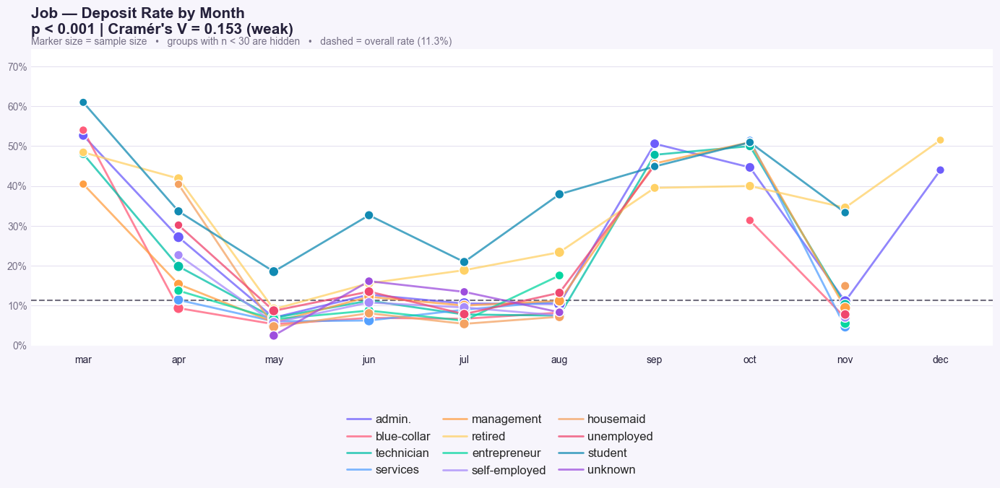

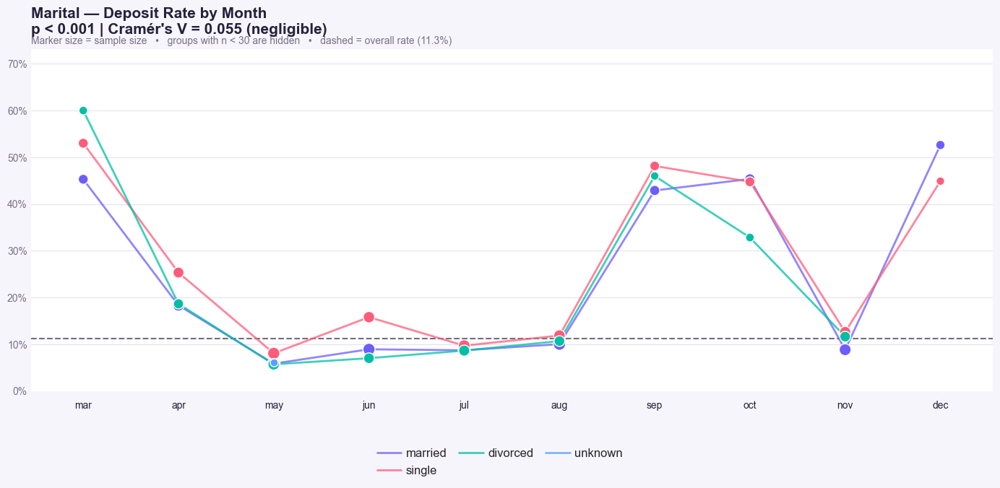

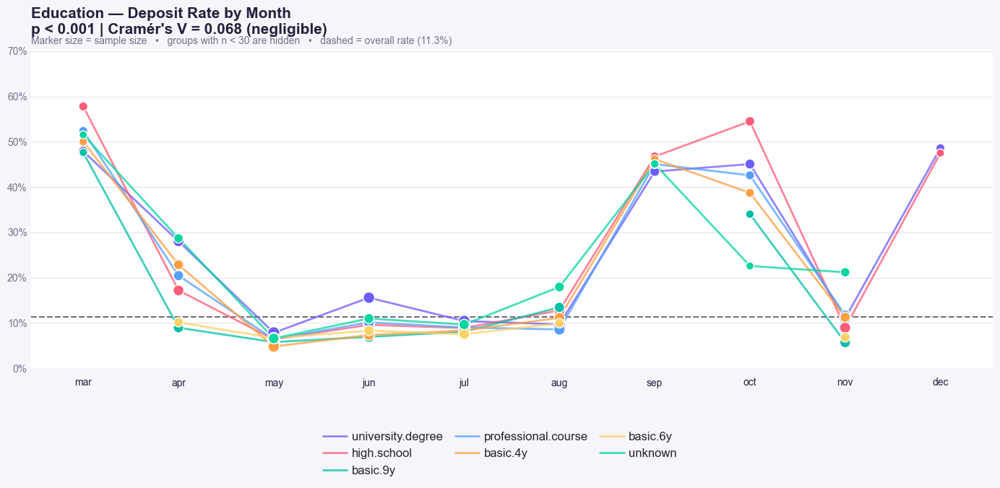

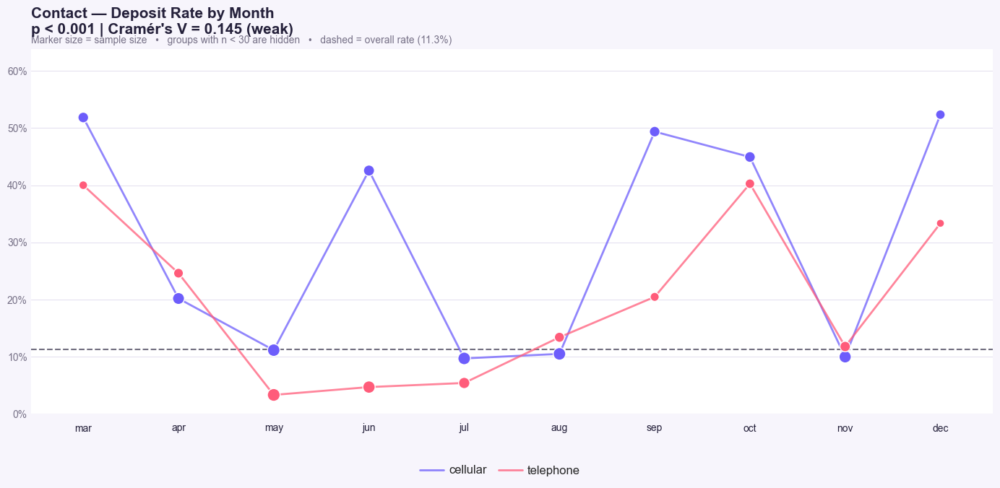

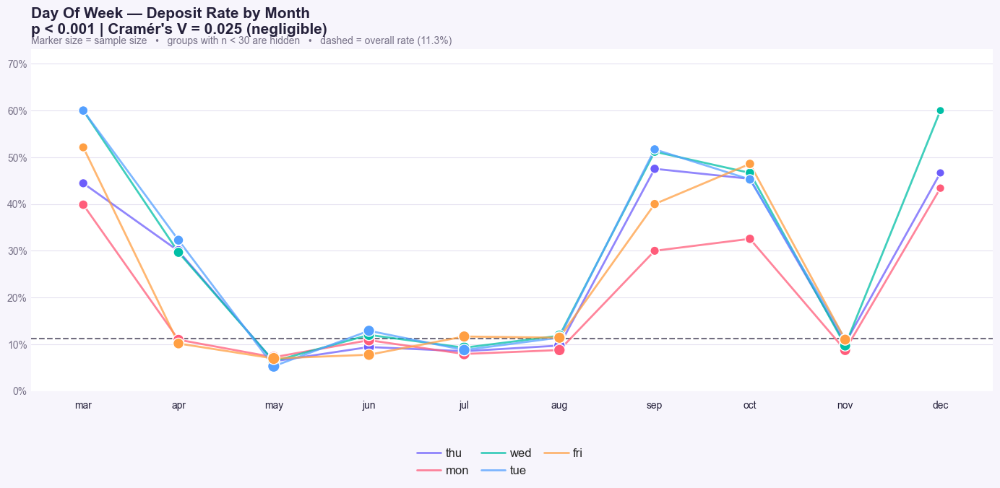

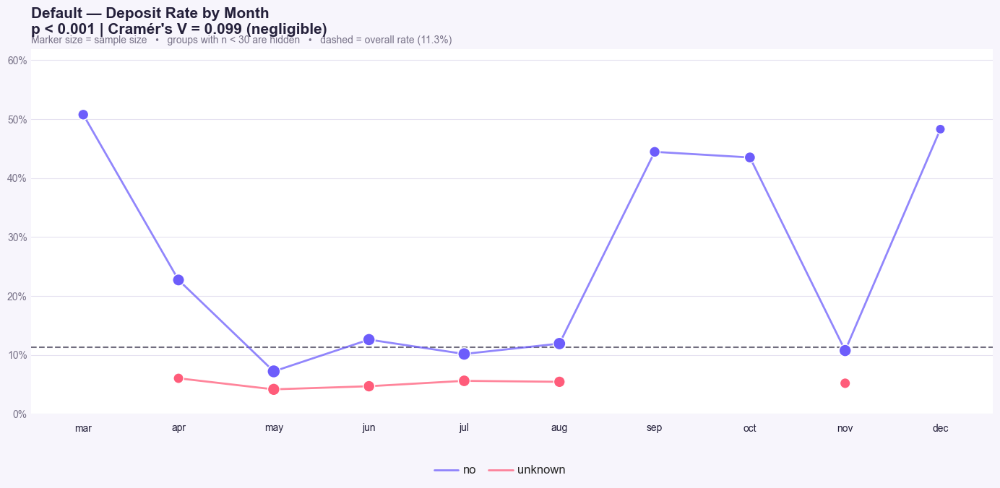

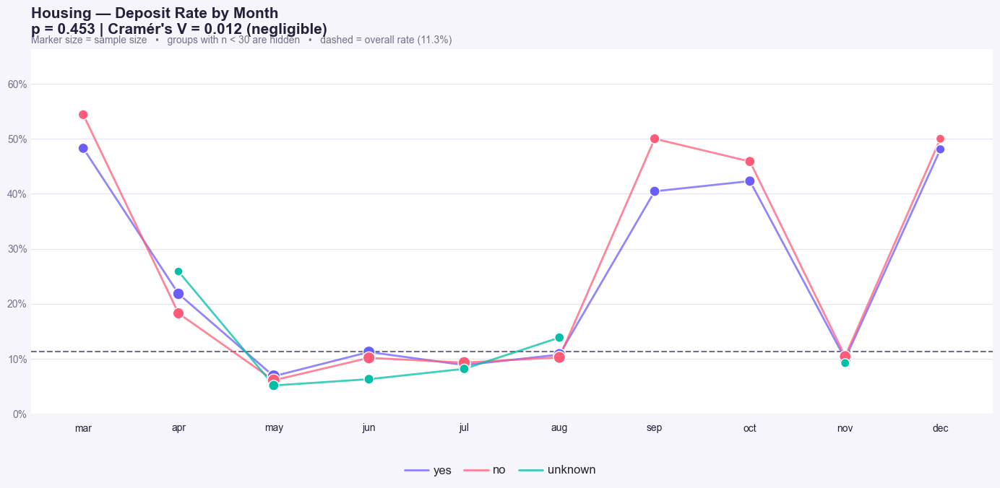

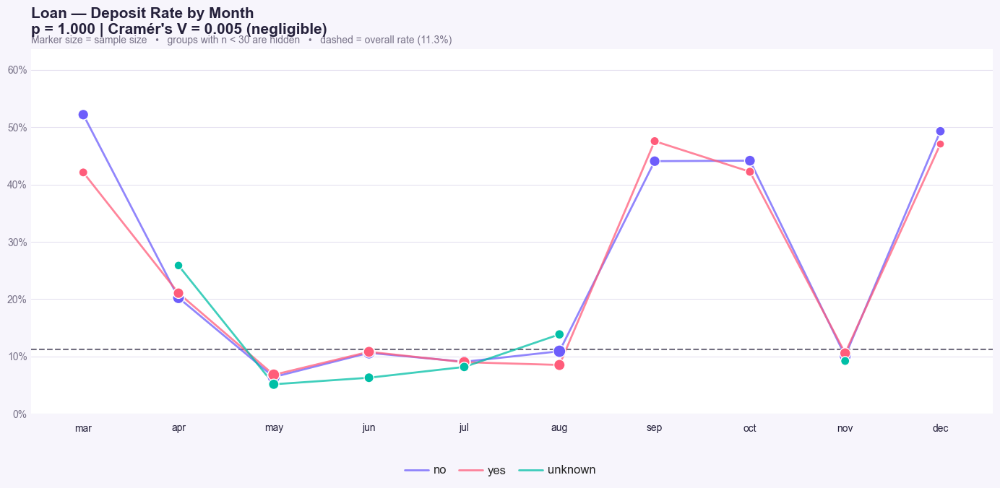

,Variable,Adjusted_P,Cramers_V,Expected_OK
0,job,2.614729e-198,0.152830,True
1,contact,1.374992e-188,0.144694,True
2,default,4.174033e-88,0.099366,False
3,education,2.997415e-37,0.068436,True
4,marital,1.422738e-25,0.054646,True
5,day_of_week,2.468604e-04,0.025155,True
6,housing,4.531034e-01,0.011809,True
7,loan,1.000000e+00,0.005167,True


In [ ]:
from scipy.stats import chi2_contingency
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="white",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)

categorical_columns = [
    "job",
    "marital",
    "education",
    "contact",
    "day_of_week",
    "default",
    "housing",
    "loan"
]

month_order = [
    "jan",
    "feb",
    "mar",
    "apr",
    "may",
    "jun",
    "jul",
    "aug",
    "sep",
    "oct",
    "nov",
    "dec"
]

palette = [
    "#6D5DFB",
    "#FF5C7A",
    "#00BFA6",
    "#54A0FF",
    "#FF9F43",
    "#FFD166",
    "#06D6A0",
    "#A78BFA",
    "#F4A261",
    "#EF476F",
    "#118AB2",
    "#9D4EDD"
]

number_of_tests = len(
    categorical_columns
)

overall_rate = (
    data["deposit"].mean() * 100
)

minimum_sample_size = 30

results = []
count_tables = {}


for column in categorical_columns:

    rates = data.pivot_table(
        index="month",
        columns=column,
        values="deposit",
        aggfunc="mean",
        observed=False
    ).mul(100)

    counts = pd.crosstab(
        data["month"],
        data[column]
    )

    category_order = (
        data[column]
        .value_counts()
        .index
    )

    available_months = [
        month
        for month in month_order
        if month in rates.index
    ]

    rates = rates.reindex(
        index=available_months,
        columns=category_order
    )

    counts = counts.reindex(
        index=available_months,
        columns=category_order,
        fill_value=0
    )

    count_tables[column] = counts

    # گروه‌های دارای کمتر از ۳۰ مشتری فقط از نمودار حذف می‌شوند
    plot_rates = rates.where(
        counts >= minimum_sample_size
    ).dropna(
        axis=1,
        how="all"
    )

    counts = counts[
        plot_rates.columns
    ]

    if plot_rates.empty:
        continue

    observed = pd.crosstab(
        data[column],
        data["deposit"]
    )

    chi2, p_value, dof, expected = (
        chi2_contingency(observed)
    )

    adjusted_p = min(
        p_value * number_of_tests,
        1
    )

    n = observed.to_numpy().sum()
    rows, columns_count = observed.shape

    cramers_v = np.sqrt(
        chi2 / (
            n * min(
                rows - 1,
                columns_count - 1
            )
        )
    )

    expected_ok = (
        expected.min() >= 1
        and (expected < 5).mean() <= 0.20
    )

    v_tag = (
        "negligible"
        if cramers_v < 0.10
        else "weak"
        if cramers_v < 0.30
        else "moderate"
        if cramers_v < 0.50
        else "strong"
    )

    results.append(
        {
            "Variable": column,
            "Adjusted_P": adjusted_p,
            "Cramers_V": cramers_v,
            "Expected_OK": expected_ok
        }
    )

    p_text = (
        "p < 0.001"
        if adjusted_p < 0.001
        else f"p = {adjusted_p:.3f}"
    )

    fig, ax = plt.subplots(
        figsize=(14, 7)
    )

    x = np.arange(
        len(plot_rates.index)
    )

    for category, color in zip(
        plot_rates.columns,
        palette
    ):

        y_values = plot_rates[
            category
        ].to_numpy(
            dtype=float
        )

        sample_sizes = counts[
            category
        ].to_numpy(
            dtype=float
        )

        valid = np.isfinite(
            y_values
        )

        ax.plot(
            x,
            y_values,
            linewidth=2,
            color=color,
            alpha=0.75,
            label=category,
            zorder=2
        )

        point_sizes = np.clip(
            np.log1p(
                sample_sizes[valid]
            ) * 18,
            25,
            170
        )

        ax.scatter(
            x[valid],
            y_values[valid],
            s=point_sizes,
            color=color,
            edgecolor="white",
            linewidth=1,
            zorder=3
        )

    ax.axhline(
        overall_rate,
        color="#25213B",
        linestyle="--",
        linewidth=1.5,
        alpha=0.65,
        zorder=1
    )

    ax.set_title(
        (
            f"{column.replace('_', ' ').title()}"
            f" — Deposit Rate by Month\n"
            f"{p_text} | "
            f"Cramér's V = {cramers_v:.3f} "
            f"({v_tag})"
        ),
        fontsize=15,
        fontweight="bold",
        color="#25213B",
        loc="left",
        pad=15
    )

    ax.text(
        0,
        1.015,
        (
            f"Marker size = sample size"
            f"   •   groups with n < {minimum_sample_size} are hidden"
            f"   •   dashed = overall rate ({overall_rate:.1f}%)"
        ),
        transform=ax.transAxes,
        color="#777187",
        fontsize=10
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        plot_rates.index,
        fontsize=10,
        color="#25213B"
    )

    ax.set_xlim(
        -0.55,
        len(plot_rates.index) - 0.45
    )

    ax.set_ylim(
        0,
        min(
            115,
            np.nanmax(
                plot_rates.values
            ) * 1.22
        )
    )

    ax.tick_params(
        axis="y",
        labelsize=10,
        length=0,
        colors="#777187"
    )

    ax.yaxis.set_major_formatter(
        PercentFormatter(xmax=100)
    )

    ax.grid(
        axis="y",
        color="#E5E1F0",
        linewidth=0.8
    )

    ax.grid(
        axis="x",
        visible=False
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    category_count = len(
        plot_rates.columns
    )

    legend_columns = (
        3
        if category_count > 3
        else category_count
    )

    legend_rows = int(
        np.ceil(
            category_count
            / legend_columns
        )
    )

    handles, labels = (
        ax.get_legend_handles_labels()
    )

    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.005),
        ncol=legend_columns,
        frameon=False,
        fontsize=12,
        columnspacing=1,
        handletextpad=0.4
    )

    plt.tight_layout(
        rect=(
            0,
            0.04 + 0.045 * legend_rows,
            1,
            0.98
        )
    )

    plt.show()


results = pd.DataFrame(results)

results = results.sort_values(
    "Cramers_V",
    ascending=False
).reset_index(drop=True)

results

<div dir="rtl">
ماه دسامبر در کل نرخ سپرده‌گذاری بالایی دارد، اما نرخ‌های ۱۰۰٪ بعضی شغل‌ها به‌دلیل تعداد بسیار کم نمونه ایجاد شده‌اند؛ برای مثال گروه کارآفرین فقط یک مشتری دارد. همچنین ترکیب مشتریان دسامبر با ماه‌های دیگر متفاوت است و سهم مشتریان دارای موفقیت قبلی، دانشجویان و بازنشستگان بیشتر است. بنابراین نمی‌توان افزایش پذیرش را فقط به خود ماه دسامبر نسبت داد.

</div>



-  عوامل مختلف تا چه حد در ماه و سپرده گذاری تاثیر دارند (bar)

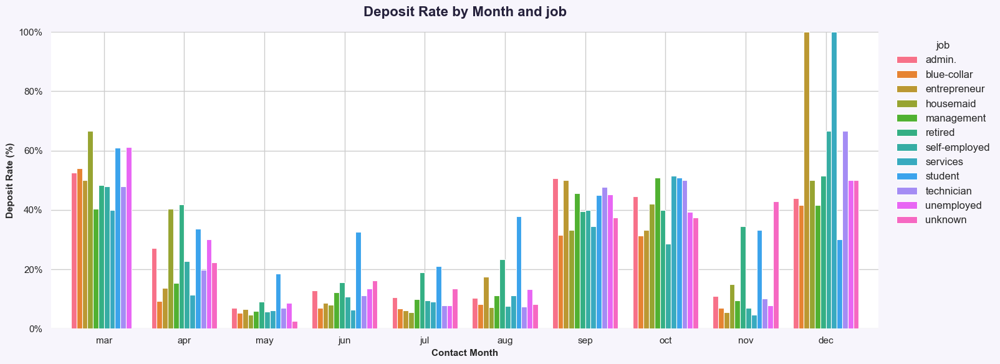

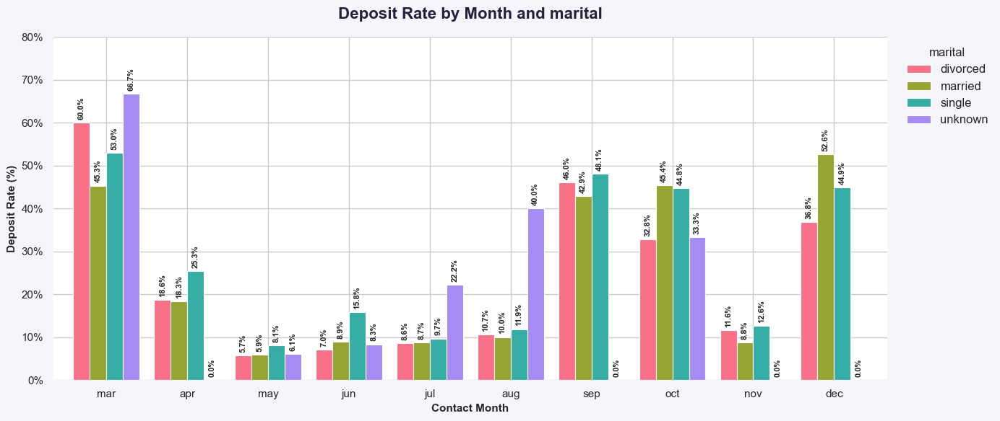

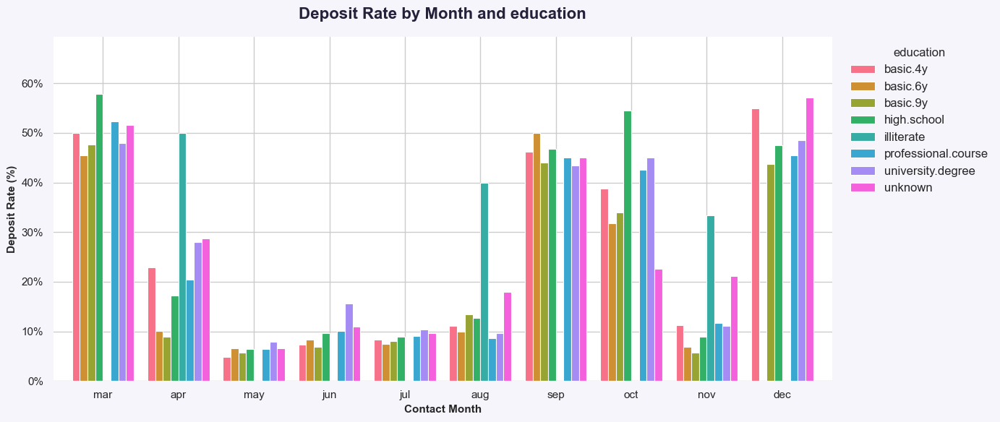

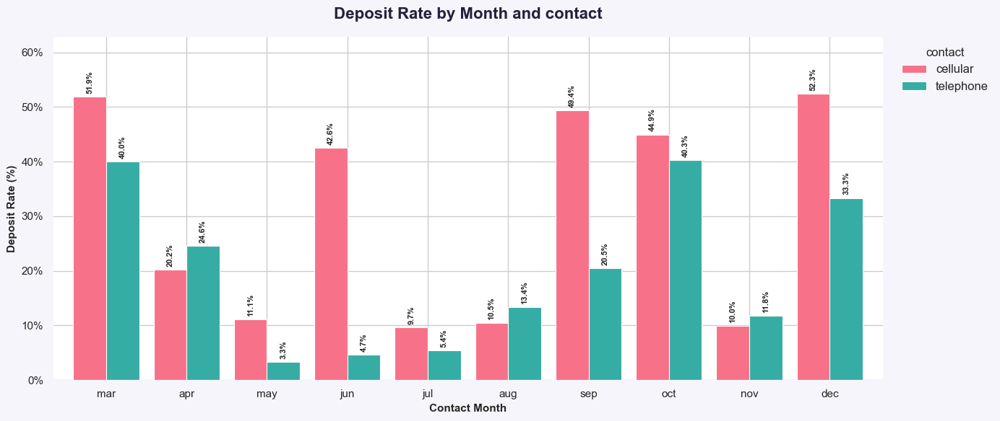

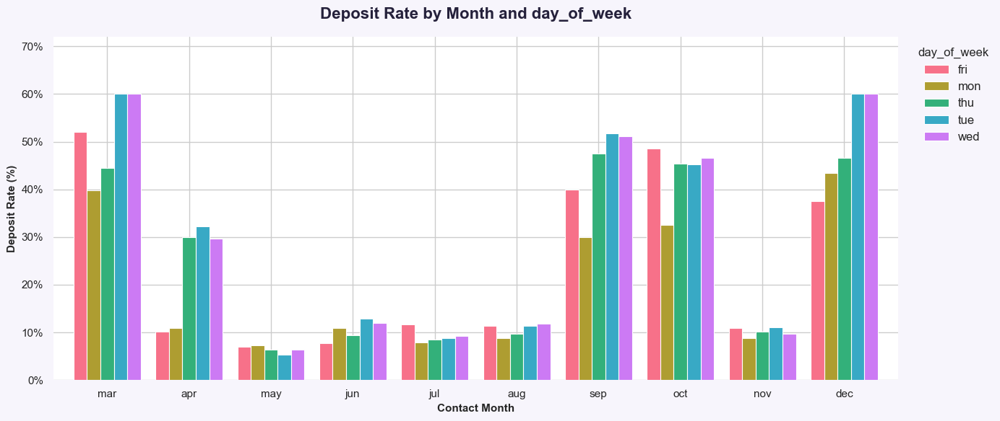

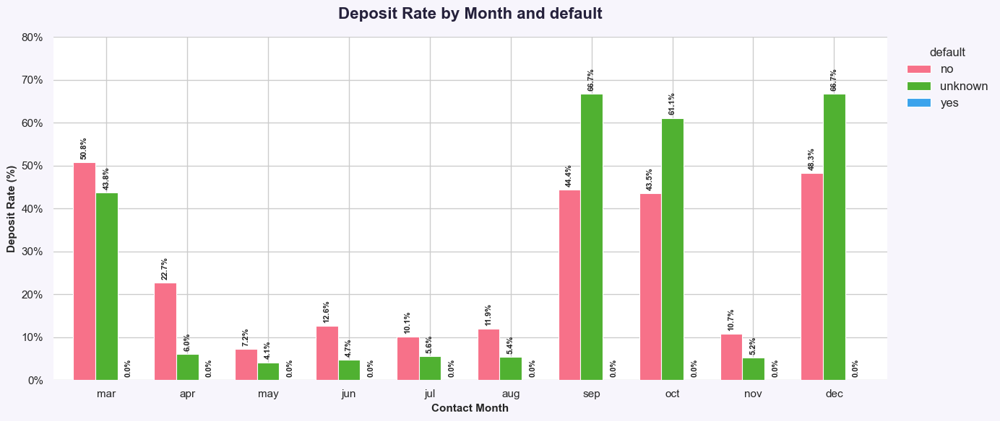

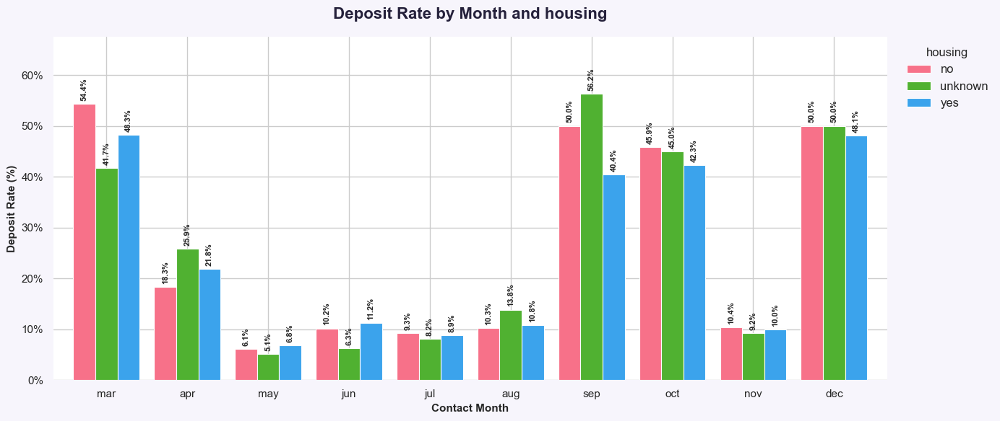

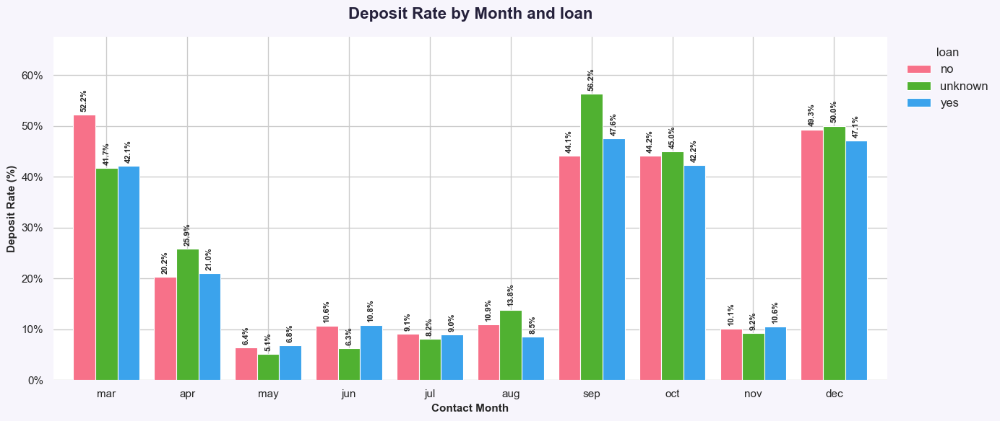

In [ ]:
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="whitegrid",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)

categorical_columns = [
    "job",
    "marital",
    "education",
    "contact",
    "day_of_week",
    "default",
    "housing",
    "loan"
]

month_order = [
    "mar",
    "apr",
    "may",
    "jun",
    "jul",
    "aug",
    "sep",
    "oct",
    "nov",
    "dec"
]


for column in categorical_columns:

    deposit_analysis = data.pivot_table(
        index="month",
        columns=column,
        values="deposit",
        aggfunc="mean",
        observed=False
    ).mul(100)

    # مرتب‌کردن ماه‌ها
    deposit_analysis = (
        deposit_analysis.reindex(
            month_order
        )
        .dropna(
            how="all"
        )
    )

    # اندازه بزرگ‌تر برای ستون‌های دارای دسته‌های زیاد
    figure_width = max(
        14,
        len(deposit_analysis.columns) * 1.35
    )

    fig, ax = plt.subplots(
        figsize=(figure_width, 6)
    )

    colors = sns.color_palette(
        "husl",
        n_colors=len(
            deposit_analysis.columns
        )
    )

    deposit_analysis.plot(
        kind="bar",
        width=0.82,
        color=colors,
        edgecolor="white",
        linewidth=0.8,
        ax=ax
    )

    # نوشتن درصد فقط برای نمودارهای خلوت
    if len(deposit_analysis.columns) <= 4:

        for container in ax.containers:

            labels = [
                f"{value:.1f}%"
                if np.isfinite(value)
                else ""
                for value in container.datavalues
            ]

            ax.bar_label(
                container,
                labels=labels,
                padding=3,
                fontsize=8,
                fontweight="bold",
                rotation=90
            )

    ax.set_title(
        f"Deposit Rate by Month and {column}",
        fontsize=16,
        fontweight="bold",
        color="#25213B",
        pad=18
    )

    ax.set_xlabel(
        "Contact Month",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Deposit Rate (%)",
        fontsize=11,
        fontweight="bold"
    )

    ax.yaxis.set_major_formatter(
        PercentFormatter(xmax=100)
    )

    maximum_rate = (
        deposit_analysis.max().max()
    )

    ax.set_ylim(
        0,
        min(
            100,
            maximum_rate * 1.20
        )
    )

    ax.tick_params(
        axis="x",
        rotation=0
    )

    # ax.grid(
    #     axis="y",
    #     linestyle="--",
    #     alpha=0.3
    # )

    # ax.grid(
    #     axis="x",
    #     visible=False
    # )

    ax.legend(
        title=column,
        frameon=False,
        bbox_to_anchor=(1.01, 1),
        loc="upper left",
        fontsize=12
    )

    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout()

<div dir='rtl'>
«بین ماه تماس و نوع شغل مشتری ارتباط آماری معناداری مشاهده شد (Cramér's V ≈ 0.111). این ارتباط در دسامبر به‌خصوص جالب است؛ سهم بازنشسته‌ها و دانشجویان به‌ترتیب به حدود 18.1٪ و 11.0٪ می‌رسد، در حالی که سهم آن‌ها در کل نمونه فقط حدود 4.2٪ و 2.1٪ است. از آنجا که این دو گروه نرخ پذیرش بالاتری دارند، تغییر ترکیب مشتریان در دسامبر می‌تواند یکی از عوامل توضیح‌دهنده‌ی نرخ پذیرش بالای این ماه باشد. با این حال، این تحلیل یک association است و به‌تنهایی اثر علّی ماه یا شغل را اثبات نمی‌کند.»
</div>

- خلاصه 8 آزمون ماه نسبت به کتگوری ها 

In [ ]:
# خلاصه‌ی همه‌ی ۸ آزمون
results = chi2_cramers(data , "month" , [
    "job",
    "marital",
    "education",
    "contact",
    "day_of_week",
    "default",
    "housing",
    "loan"
])
results.sort_values(by="Cramers_V", inplace=True, ascending=False)
results


,Variable,P_Value,Cramers_V
3,contact,0.000000e+00,0.609298
5,default,1.217027e-210,0.112910
0,job,0.000000e+00,0.110989
2,education,0.000000e+00,0.095858
4,day_of_week,7.950178e-137,0.068207
6,housing,4.970686e-44,0.056232
1,marital,2.717784e-54,0.052202
7,loan,5.233309e-04,0.024741


<div dir="rtl">
نتیجه گیری : 
نوع تماس (contact) به‌تنهایی با پذیرش سپرده ارتباط معناداری دارد، اما شدت این ارتباط محدود است. الگوی پذیرش این گروه‌ها در ماه‌های مختلف تغییر می‌کند و بنابراین بررسی هم‌زمان نوع تماس و ماه می‌تواند اطلاعات بیشتری از رفتار پذیرش ارائه دهد. <br>

بین گروه‌های سنی و پذیرش سپرده نیز تفاوت معناداری مشاهده می‌شود؛ به‌خصوص گروه‌های 17–25 و 61+ نرخ پذیرش بالاتری نسبت به گروه‌های میانی دارند.<br>

همچنین وضعیت default با پذیرش سپرده ارتباط دارد، اما default=no را نباید مستقیماً معادل «خوش‌حساب بودن» یا «پرداخت به‌موقع بدهی» در نظر گرفت.

</div>

- month VS numeric

- Kruskal–Wallis : 
    - فرض صفر: توزیع متغیر عددی در تمام گروه‌ها یکسان است.
    - Epsilon Squared : 
        - 0.01 → اثر ضعیف
        - 0.06 → اثر متوسط
        - 0.14 → اثر بزرگ

In [ ]:
group_association(data , "month" , [
        "eco_employment_rate_change_pct",
        "eco_consumer_price_index",
        "eco_consumer_confidence_index",
        "eco_interest_rate_3m_pct",
        "eco_num_employed_thousand",
    ])


,Variable,Test,Statistic,adjusted_p,P_Value,Effect_Size
4,eco_num_employed_thousand,Kruskal-Wallis,23132.488973,0.0,0.0,0.561713
0,eco_employment_rate_change_pct,Kruskal-Wallis,22839.605803,0.0,0.0,0.554599
3,eco_interest_rate_3m_pct,Kruskal-Wallis,20602.258496,0.0,0.0,0.500249
2,eco_consumer_confidence_index,Kruskal-Wallis,19822.116660,0.0,0.0,0.481298
1,eco_consumer_price_index,Kruskal-Wallis,13538.314373,0.0,0.0,0.328653


<div dir="rtl">
ماه بخش بزرگی از تفاوت‌های شاخص‌های اقتصادی را توضیح می‌دهد
</div>

- متغیر های اقتصادی در بازه های زمانی مختلف چگونه است


<div dir="rtl">

- ماه به تنهایی زمان دقیق شرایط اقتصادی را مشخص نمی‌کند (شاید از سال های مختلف این ماه ها جمع آوری شدند) مثلا July 2008 ,
July 2009 ,
July 2010  <br>
- در ماه July، نمونه‌های ما متعلق به چند وضعیت اقتصادی متفاوت هستند و این وضعیت‌های اقتصادی با نرخ پذیرش بسیار متفاوتی همراه شده‌اند.

</div>

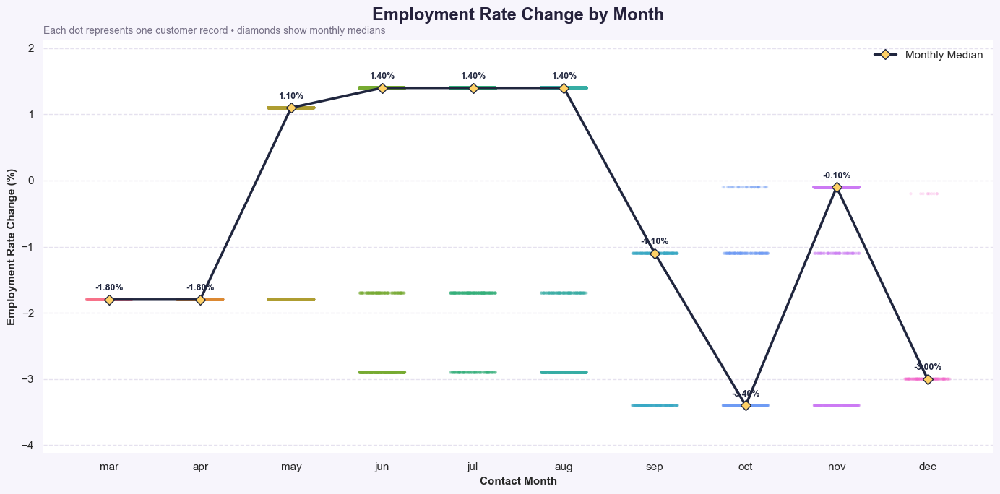

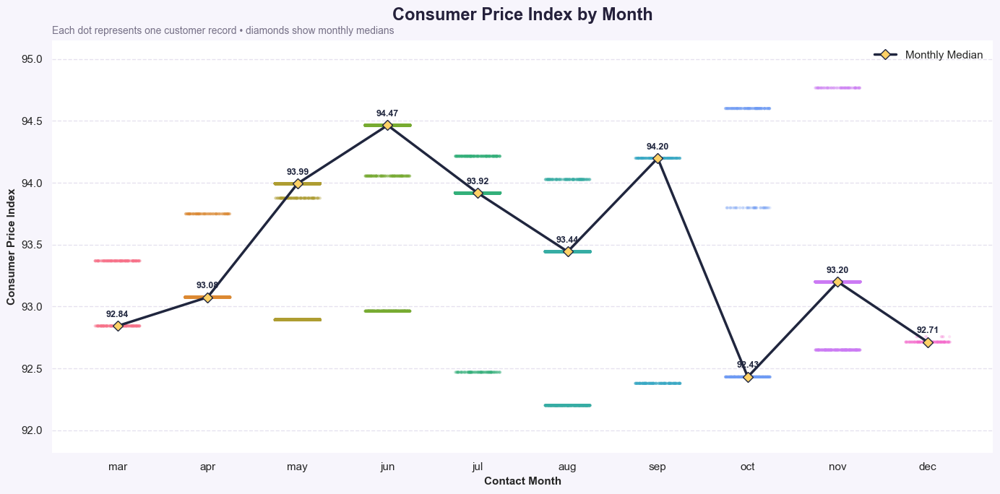

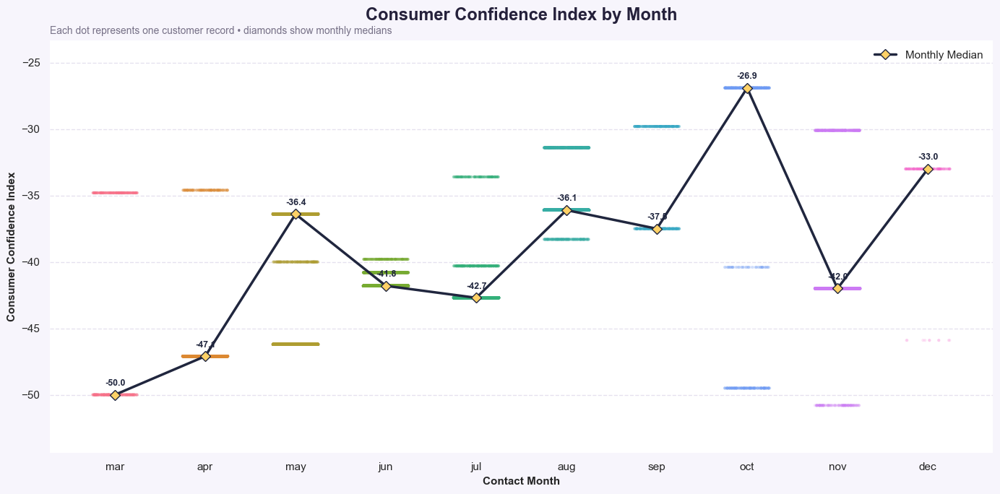

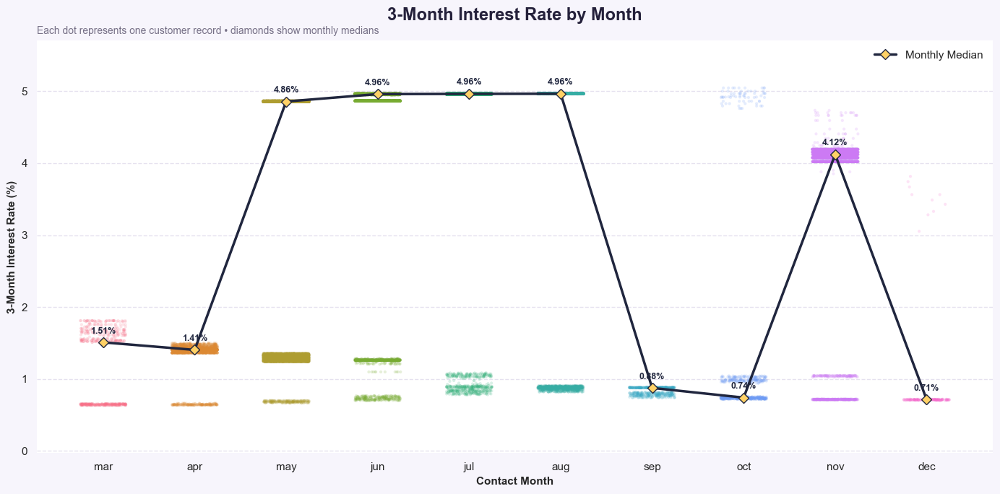

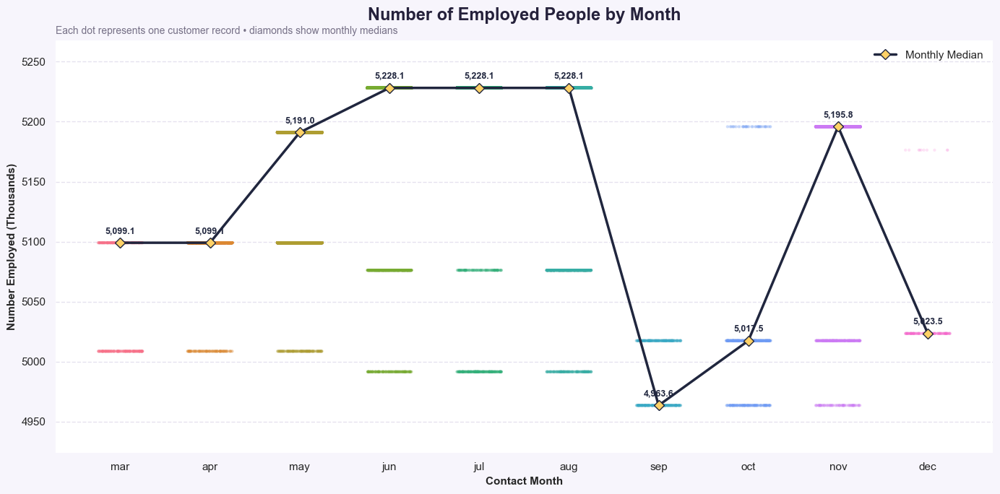

In [ ]:
month_order = [
    "mar",
    "apr",
    "may",
    "jun",
    "jul",
    "aug",
    "sep",
    "oct",
    "nov",
    "dec"
]

month_colors = dict(
    zip(
        month_order,
        sns.color_palette(
            "husl",
            len(month_order)
        )
    )
)

economic_variables = [
    (
        "eco_employment_rate_change_pct",
        "Employment Rate Change by Month",
        "Employment Rate Change (%)",
        "{:.2f}%"
    ),
    (
        "eco_consumer_price_index",
        "Consumer Price Index by Month",
        "Consumer Price Index",
        "{:.2f}"
    ),
    (
        "eco_consumer_confidence_index",
        "Consumer Confidence Index by Month",
        "Consumer Confidence Index",
        "{:.1f}"
    ),
    (
        "eco_interest_rate_3m_pct",
        "3-Month Interest Rate by Month",
        "3-Month Interest Rate (%)",
        "{:.2f}%"
    ),
    (
        "eco_num_employed_thousand",
        "Number of Employed People by Month",
        "Number Employed (Thousands)",
        "{:,.1f}"
    )
]

sns.set_theme(
    style="whitegrid",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)


for (
    column,
    title,
    ylabel,
    value_format
) in economic_variables:

    monthly_median = (
        data.groupby(
            "month",
            observed=True
        )[column]
        .median()
        .reindex(month_order)
    )

    fig, ax = plt.subplots(
        figsize=(14, 7)
    )

    # Scatter Plot با Jitter
    sns.stripplot(
        data=data,
        x="month",
        y=column,
        order=month_order,
        hue="month",
        palette=month_colors,
        jitter=0.25,
        alpha=0.18,
        size=3,
        legend=False,
        ax=ax
    )

    # خط میانه ماهانه
    ax.plot(
        range(len(month_order)),
        monthly_median,
        color="#20263E",
        linewidth=2.5,
        marker="D",
        markersize=7,
        markerfacecolor="#FFD166",
        markeredgecolor="#20263E",
        label="Monthly Median",
        zorder=5
    )

    # نوشتن مقدار میانه
    for position, value in enumerate(
        monthly_median
    ):

        if pd.notna(value):

            ax.annotate(
                value_format.format(value),
                xy=(
                    position,
                    value
                ),
                xytext=(0, 9),
                textcoords="offset points",
                ha="center",
                fontsize=9,
                fontweight="bold",
                color="#20263E"
            )

    ax.set_title(
        title,
        fontsize=17,
        fontweight="bold",
        color="#25213B",
        pad=20
    )

    ax.text(
        0,
        1.015,
        (
            "Each dot represents one customer record "
            "• diamonds show monthly medians"
        ),
        transform=ax.transAxes,
        color="#777187",
        fontsize=10
    )

    ax.set_xlabel(
        "Contact Month",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        ylabel,
        fontsize=11,
        fontweight="bold"
    )

    ax.tick_params(
        axis="x",
        rotation=0
    )

    ax.grid(
        axis="y",
        linestyle="--",
        color="#DDD8EA",
        alpha=0.75
    )

    ax.grid(
        axis="x",
        visible=False
    )

    ax.margins(
        y=0.15
    )

    ax.legend(
        frameon=False,
        loc="upper right"
    )

    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout()

<div dir="rtl">

- احتمالا دلیل چند دستگی بعضی از گروه ها جمع آوری دیتاست در سال های مختلف بوده

«در برخی ماه‌ها، به‌ویژه July، شاخص تغییر نرخ اشتغال یک مقدار واحد ندارد و چند خوشه‌ی مشخص مشاهده می‌شود. این موضوع نشان می‌دهد که متغیر month <br>     به‌تنهایی شرایط دقیق اقتصادی دوره‌ی تماس را مشخص نمی‌کند و احتمالاً چند دوره زمانی متفاوت در یک نام ماه تجمیع شده‌اند. نکته مهم این است که <br> این گروه‌های اقتصادی در همان ماه، نرخ‌های پذیرش سپرده‌ی بسیار متفاوتی نیز دارند.»
</div>

- تاثیر متغیر های اقتصادی در ماه های مختلف روی سپرده گذاری 

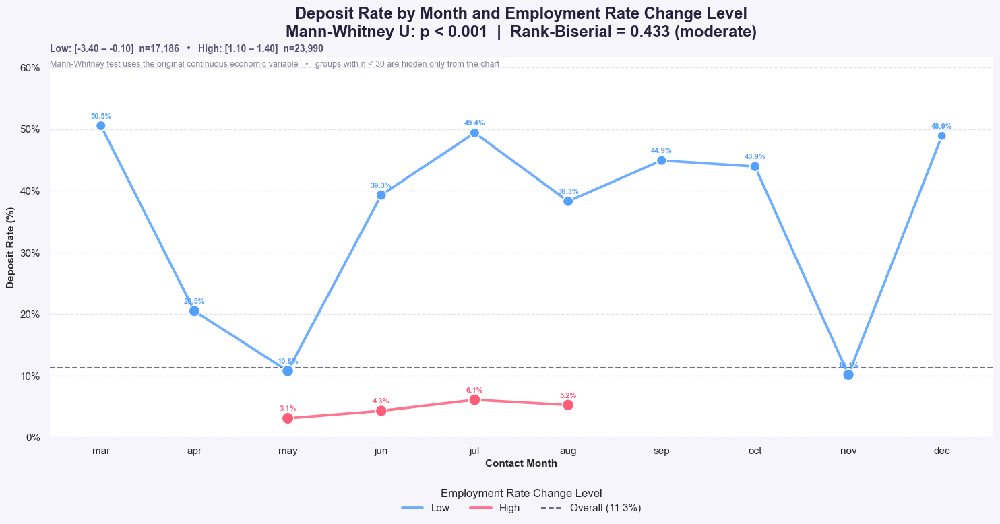

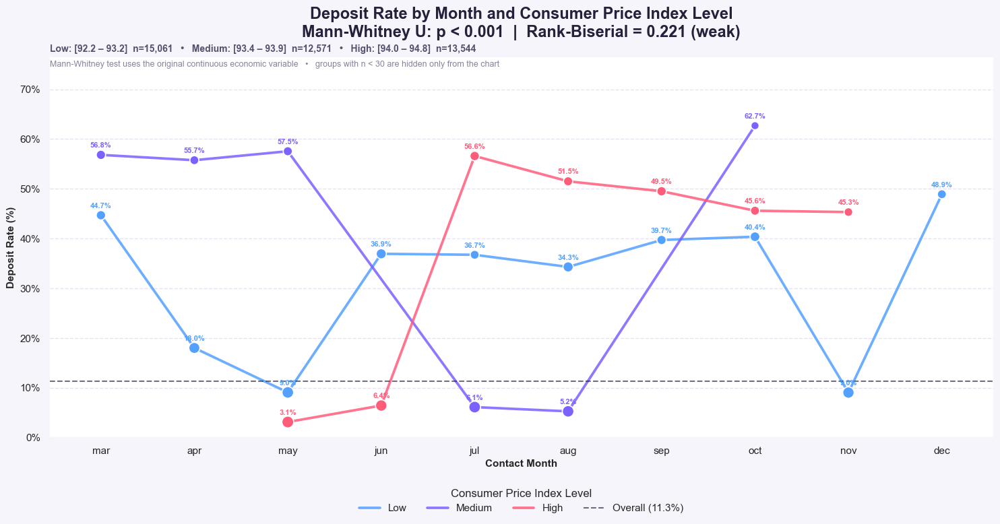

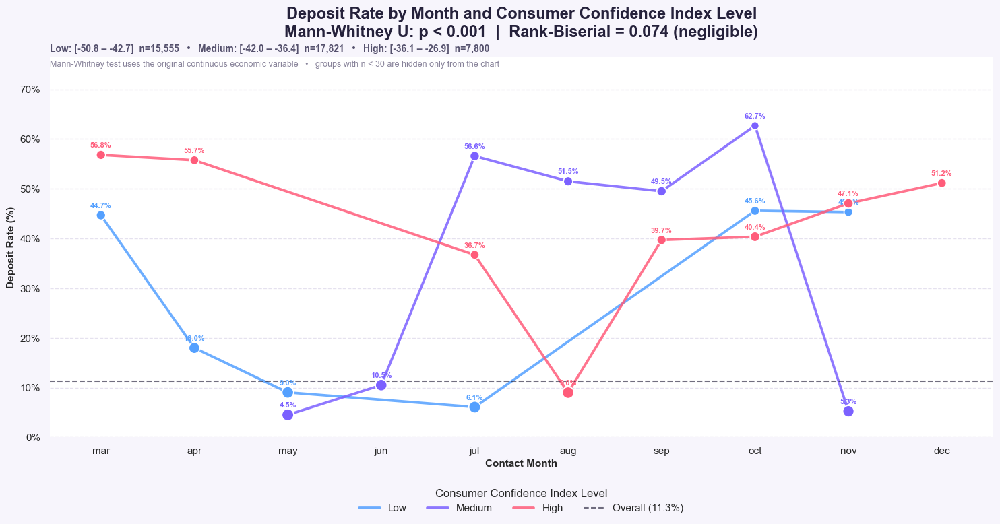

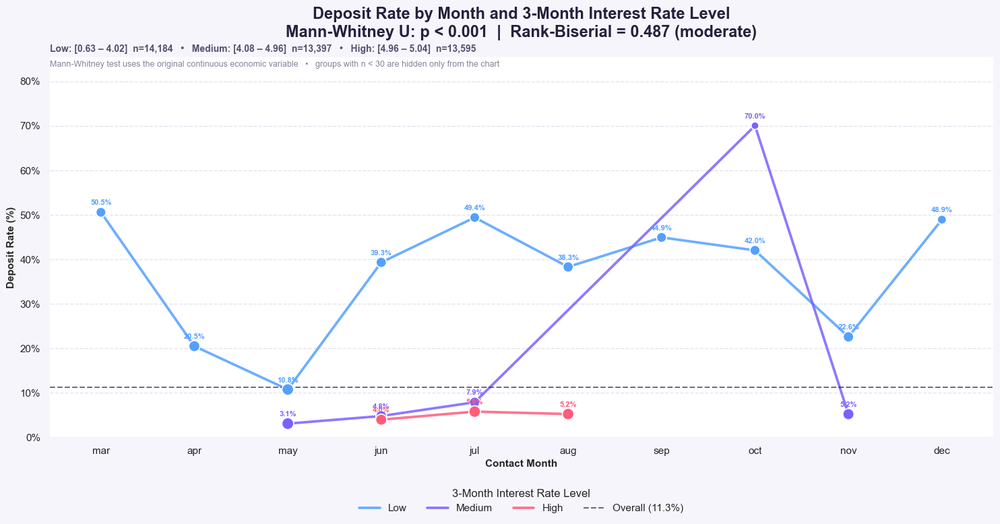

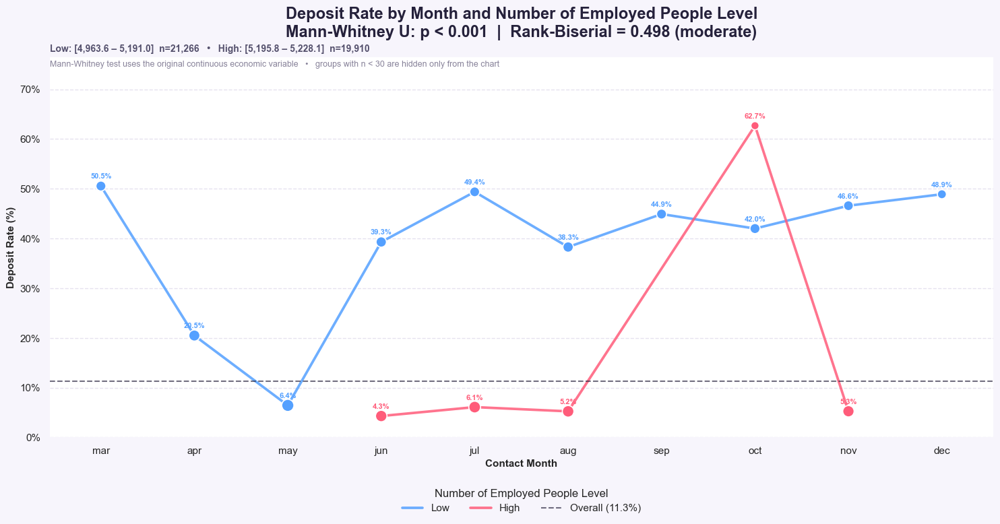

In [ ]:
from scipy.stats import mannwhitneyu
from matplotlib.ticker import PercentFormatter


month_order = [
    "mar",
    "apr",
    "may",
    "jun",
    "jul",
    "aug",
    "sep",
    "oct",
    "nov",
    "dec"
]

economic_variables = [
    (
        "eco_employment_rate_change_pct",
        "Employment Rate Change"
    ),
    (
        "eco_consumer_price_index",
        "Consumer Price Index"
    ),
    (
        "eco_consumer_confidence_index",
        "Consumer Confidence Index"
    ),
    (
        "eco_interest_rate_3m_pct",
        "3-Month Interest Rate"
    ),
    (
        "eco_num_employed_thousand",
        "Number of Employed People"
    )
]

level_colors = {
    "Low": "#54A0FF",
    "Medium": "#7B61FF",
    "High": "#FF5C7A"
}

minimum_sample_size = 30

number_of_tests = len(
    economic_variables
)

overall_rate = (
    data["deposit"].mean() * 100
)

results = []

sns.set_theme(
    style="whitegrid",
    rc={
        "figure.facecolor": "#F7F5FC",
        "axes.facecolor": "#FFFFFF"
    }
)

deposit_values = data["deposit"].dropna().unique()

if len(deposit_values) != 2:
    raise ValueError(
        "Column 'deposit' must contain exactly two groups."
    )

for column, title in economic_variables:

    plot_data = data[
        [
            "month",
            column,
            "deposit"
        ]
    ].dropna().copy()


    group_1 = plot_data.loc[
        plot_data["deposit"] == deposit_values[0],
        column
    ]

    group_2 = plot_data.loc[
        plot_data["deposit"] == deposit_values[1],
        column
    ]


    if len(group_1) == 0 or len(group_2) == 0:
        continue


    U, p_value = mannwhitneyu(
        group_1,
        group_2,
        alternative="two-sided",
        method="auto"
    )


    n1 = len(group_1)
    n2 = len(group_2)


    effect_size = abs(
        1 - (
            2 * U
        ) / (
            n1 * n2
        )
    )

    adjusted_p = min(
        p_value * number_of_tests,
        1
    )


    strength = (
        "negligible"
        if effect_size < 0.10
        else "weak"
        if effect_size < 0.30
        else "moderate"
        if effect_size < 0.50
        else "strong"
    )



    p_text = (
        "p < 0.001"
        if adjusted_p < 0.001
        else f"p = {adjusted_p:.3f}"
    )


    results.append(
        {
            "Variable": column,
            "Test": "Mann-Whitney U",
            "Statistic": U,
            "Adjusted_P": adjusted_p,
            "P_Value": p_value,
            "Effect_Size": effect_size,
            "Strength": strength
        }
    )


    economic_groups = pd.qcut(
        plot_data[column],
        q=3,
        duplicates="drop"
    )


    number_of_groups = len(
        economic_groups.cat.categories
    )


    if number_of_groups == 2:

        group_labels = [
            "Low",
            "High"
        ]

    else:

        group_labels = [
            "Low",
            "Medium",
            "High"
        ]


    plot_data["EconomicLevel"] = (
        economic_groups.cat.rename_categories(
            group_labels
        )
    )


    level_ranges = (
        plot_data
        .groupby(
            "EconomicLevel",
            observed=True
        )[column]
        .agg(
            min="min",
            max="max",
            count="count"
        )
        .reindex(group_labels)
    )

    deposit_rates = (
        plot_data
        .pivot_table(
            index="month",
            columns="EconomicLevel",
            values="deposit",
            aggfunc="mean",
            observed=True
        )
        .mul(100)
    )


    sample_sizes = pd.crosstab(
        plot_data["month"],
        plot_data["EconomicLevel"]
    )


    available_months = [
        month
        for month in month_order
        if month in deposit_rates.index
    ]


    deposit_rates = deposit_rates.reindex(
        index=available_months,
        columns=group_labels
    )


    sample_sizes = sample_sizes.reindex(
        index=available_months,
        columns=group_labels,
        fill_value=0
    )

    plot_rates = deposit_rates.where(
        sample_sizes >= minimum_sample_size
    )


    if plot_rates.notna().sum().sum() == 0:
        continue

    fig, ax = plt.subplots(
        figsize=(15, 8)
    )


    x = np.arange(
        len(plot_rates.index)
    )

    for level in group_labels:

        values = plot_rates[
            level
        ].to_numpy(
            dtype=float
        )


        counts = sample_sizes[
            level
        ].to_numpy(
            dtype=float
        )


        valid = np.isfinite(values)


        ax.plot(
            x[valid],
            values[valid],
            color=level_colors[level],
            linewidth=2.7,
            alpha=0.85,
            label=level,
            zorder=2
        )

        point_sizes = np.clip(
            np.log1p(
                counts[valid]
            ) * 18,
            35,
            170
        )


        ax.scatter(
            x[valid],
            values[valid],
            s=point_sizes,
            color=level_colors[level],
            edgecolor="white",
            linewidth=1.2,
            zorder=3
        )

        for position in np.where(valid)[0]:

            ax.annotate(
                f"{values[position]:.1f}%",
                xy=(
                    x[position],
                    values[position]
                ),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                fontsize=8,
                fontweight="bold",
                color=level_colors[level]
            )


    ax.axhline(
        overall_rate,
        color="#25213B",
        linestyle="--",
        linewidth=1.5,
        alpha=0.65,
        label=f"Overall ({overall_rate:.1f}%)"
    )

    range_text_parts = []

    for level in group_labels:

        min_value = level_ranges.loc[
            level,
            "min"
        ]

        max_value = level_ranges.loc[
            level,
            "max"
        ]

        count_value = level_ranges.loc[
            level,
            "count"
        ]


        if pd.isna(min_value):
            continue

        if (
            abs(min_value) >= 100
            or abs(max_value) >= 100
        ):

            range_text = (
                f"{min_value:,.1f}"
                f" – "
                f"{max_value:,.1f}"
            )

        elif (
            abs(min_value) >= 10
            or abs(max_value) >= 10
        ):

            range_text = (
                f"{min_value:.1f}"
                f" – "
                f"{max_value:.1f}"
            )

        else:

            range_text = (
                f"{min_value:.2f}"
                f" – "
                f"{max_value:.2f}"
            )


        range_text_parts.append(
            f"{level}: [{range_text}]  n={int(count_value):,}"
        )


    range_text = "   •   ".join(
        range_text_parts
    )

    ax.set_title(
        (
            f"Deposit Rate by Month and {title} Level\n"
            f"Mann-Whitney U: {p_text}"
            f"  |  Rank-Biserial = "
            f"{effect_size:.3f} "
            f"({strength})"
        ),
        fontsize=17,
        fontweight="bold",
        color="#25213B",
        pad=22
    )


    ax.text(
        0,
        1.015,
        range_text,
        transform=ax.transAxes,
        color="#55516D",
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        0,
        0.975,
        (
            "Mann-Whitney test uses the original continuous "
            "economic variable"
            f"   •   groups with n < {minimum_sample_size} "
            "are hidden only from the chart"
        ),
        transform=ax.transAxes,
        color="#88839A",
        fontsize=9
    )

    ax.set_xlabel(
        "Contact Month",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Deposit Rate (%)",
        fontsize=11,
        fontweight="bold"
    )


    ax.set_xticks(x)

    ax.set_xticklabels(
        plot_rates.index
    )


    ax.set_xlim(
        -0.55,
        len(plot_rates.index) - 0.45
    )

    maximum_rate = np.nanmax(
        plot_rates.to_numpy()
    )


    ax.set_ylim(
        0,
        min(
            100,
            max(
                20,
                maximum_rate * 1.22
            )
        )
    )


    ax.yaxis.set_major_formatter(
        PercentFormatter(
            xmax=100
        )
    )

    ax.grid(
        axis="y",
        linestyle="--",
        color="#DDD8EA",
        alpha=0.75
    )


    ax.grid(
        axis="x",
        visible=False
    )

    ax.legend(
        title=f"{title} Level",
        frameon=False,
        ncol=4,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.11)
    )


    for spine in ax.spines.values():
        spine.set_visible(False)


    plt.tight_layout()



results = (
    pd.DataFrame(results)
    .sort_values(
        "Effect_Size",
        ascending=False
    )
    .reset_index(drop=True)
)



- چه عواملی باعث شدن افت یا افزایش شدیدی در ماه های مختلف داشته باشیم 

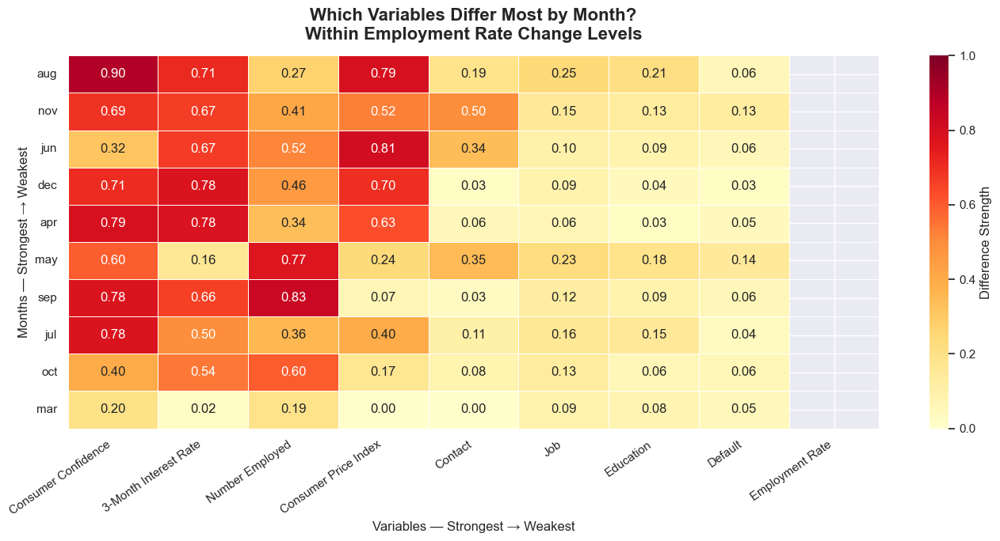

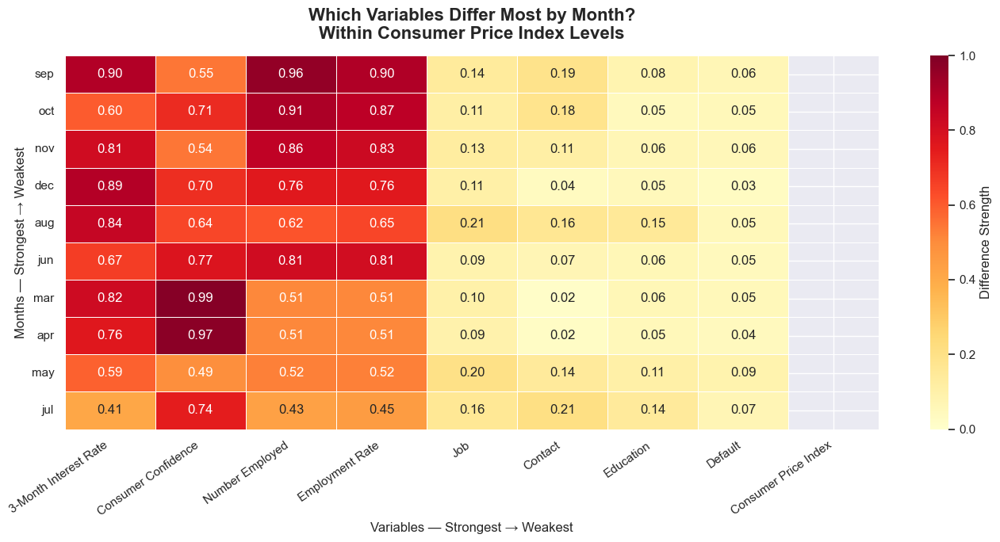

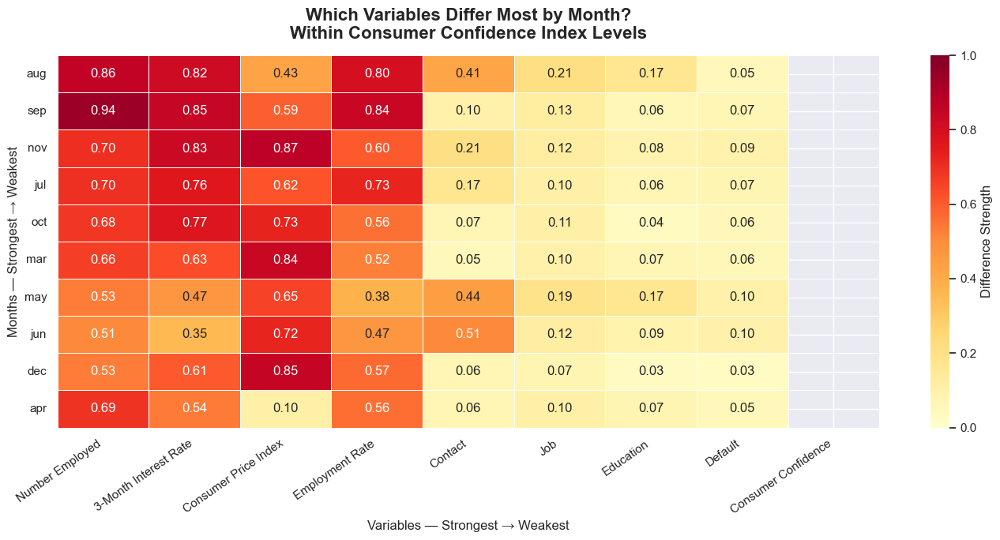

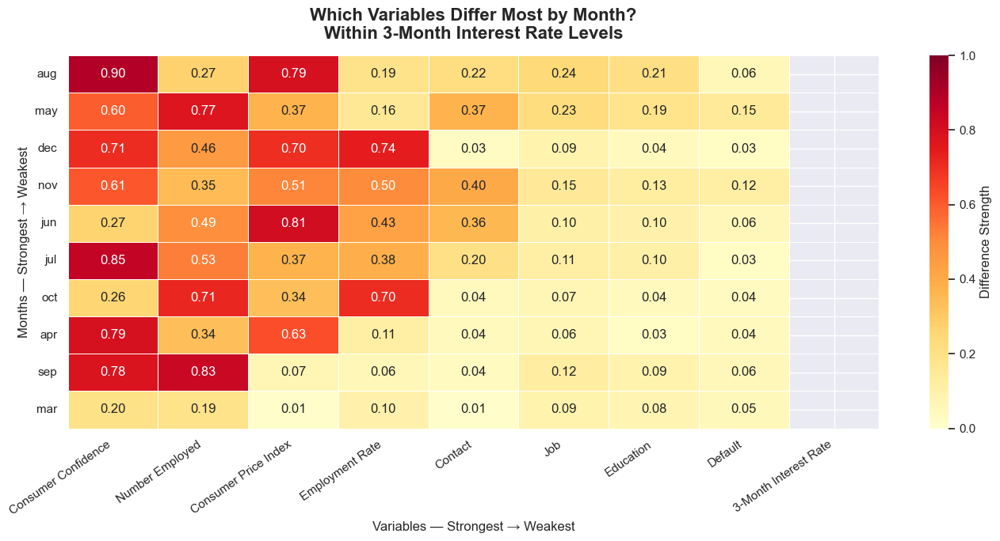

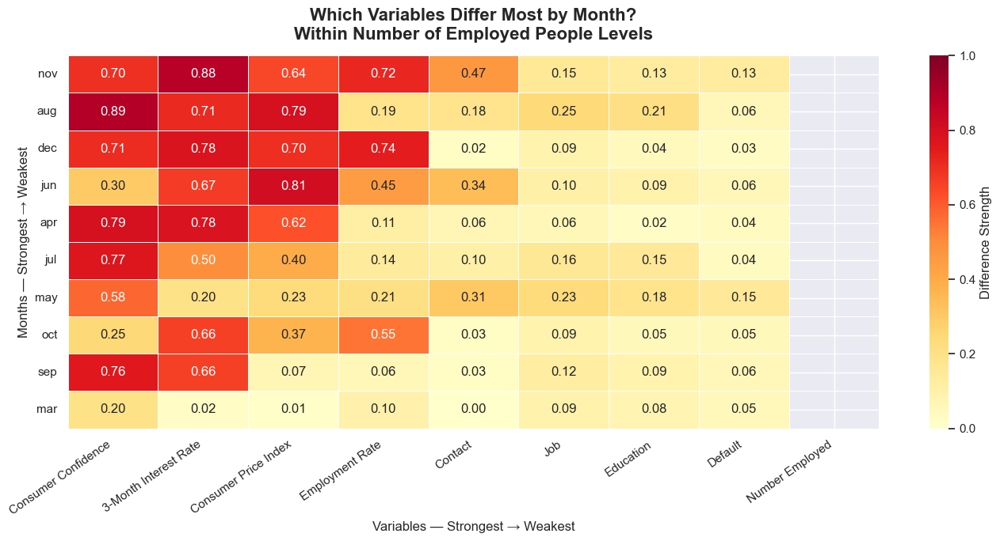

In [6]:
from scipy.stats import chi2_contingency
from scipy.stats import mannwhitneyu

categorical_drivers = [
    "contact",
    "job",
    "default",
    "education"
]


economic_variables = [
    (
        "eco_employment_rate_change_pct",
        "Employment Rate Change"
    ),
    (
        "eco_consumer_price_index",
        "Consumer Price Index"
    ),
    (
        "eco_consumer_confidence_index",
        "Consumer Confidence Index"
    ),
    (
        "eco_interest_rate_3m_pct",
        "3-Month Interest Rate"
    ),
    (
        "eco_num_employed_thousand",
        "Number of Employed People"
    )
]


economic_columns = [
    column
    for column, title in economic_variables
]


driver_variables = (
    categorical_drivers
    + economic_columns
)

required_columns = [
    "month",
    "deposit"
] + driver_variables


missing_columns = [
    column
    for column in required_columns
    if column not in data.columns
]


if missing_columns:

    raise KeyError(
        f"These columns are missing from data: "
        f"{missing_columns}"
    )

month_order = [
    "mar",
    "apr",
    "may",
    "jun",
    "jul",
    "aug",
    "sep",
    "oct",
    "nov",
    "dec"
]


months_present = [
    month
    for month in month_order
    if month in data["month"].dropna().unique()
]

def categorical_difference(
    target_group,
    other_group
):

    temp = pd.DataFrame({

        "group": (
            ["Target"] * len(target_group)
            + ["Other"] * len(other_group)
        ),

        "value": pd.concat(
            [
                target_group,
                other_group
            ],
            ignore_index=True
        )

    })


    temp = temp.dropna()


    if temp.empty:
        return np.nan


    if temp["value"].nunique() < 2:
        return np.nan


    table = pd.crosstab(
        temp["group"],
        temp["value"]
    )


    if table.shape[0] < 2:
        return np.nan


    if table.shape[1] < 2:
        return np.nan


    chi2, _, _, _ = chi2_contingency(
        table
    )


    n = table.to_numpy().sum()


    denominator = (
        n
        * min(
            table.shape[0] - 1,
            table.shape[1] - 1
        )
    )


    if denominator == 0:
        return np.nan


    return np.sqrt(
        chi2 / denominator
    )


def numeric_difference(
    target_group,
    other_group
):

    target_group = pd.to_numeric(
        target_group,
        errors="coerce"
    ).dropna()


    other_group = pd.to_numeric(
        other_group,
        errors="coerce"
    ).dropna()


    if len(target_group) == 0:
        return np.nan


    if len(other_group) == 0:
        return np.nan


    try:

        u_statistic, _ = mannwhitneyu(
            target_group,
            other_group,
            alternative="two-sided"
        )


        effect = abs(
            2
            * u_statistic
            / (
                len(target_group)
                * len(other_group)
            )
            - 1
        )


        return effect


    except ValueError:

        return np.nan


display_names = {

    "contact":
        "Contact",

    "job":
        "Job",

    "default":
        "Default",

    "education":
        "Education",

    "eco_employment_rate_change_pct":
        "Employment Rate",

    "eco_consumer_price_index":
        "Consumer Price Index",

    "eco_consumer_confidence_index":
        "Consumer Confidence",

    "eco_interest_rate_3m_pct":
        "3-Month Interest Rate",

    "eco_num_employed_thousand":
        "Number Employed"
}


all_matrices = {}


for economic_column, economic_title in economic_variables:

    plot_data = data[
        required_columns
    ].copy()


    plot_data = plot_data.dropna(
        subset=[
            economic_column,
            "month",
            "deposit"
        ]
    ).copy()


    ranks = plot_data[
        economic_column
    ].rank(
        method="first"
    )


    plot_data["_economic_level"] = pd.qcut(
        ranks,
        q=3,
        labels=[
            "Low",
            "Medium",
            "High"
        ]
    )

    scores = []

    for month in months_present:

        for variable in driver_variables:

            if variable == economic_column:

                scores.append({

                    "month":
                        month,

                    "variable":
                        variable,

                    "score":
                        np.nan

                })

                continue


            level_scores = []


            for level in [
                "Low",
                "Medium",
                "High"
            ]:


                level_data = plot_data[
                    plot_data["_economic_level"]
                    == level
                ]

                target = level_data[
                    level_data["month"] == month
                ][variable]


                other = level_data[
                    level_data["month"] != month
                ][variable]


                if variable in categorical_drivers:

                    score = categorical_difference(
                        target,
                        other
                    )


                else:

                    score = numeric_difference(
                        target,
                        other
                    )


                if pd.notna(score):

                    level_scores.append(
                        score
                    )


            if level_scores:

                final_score = np.mean(
                    level_scores
                )

            else:

                final_score = np.nan


            scores.append({

                "month":
                    month,

                "variable":
                    variable,

                "score":
                    final_score

            })


    matrix = (
        pd.DataFrame(scores)
        .pivot(
            index="month",
            columns="variable",
            values="score"
        )
    )

    variable_order = (

        matrix
        .mean(
            axis=0,
            skipna=True
        )
        .sort_values(
            ascending=False
        )
        .index

    )

    month_order_sorted = (

        matrix
        .mean(
            axis=1,
            skipna=True
        )
        .sort_values(
            ascending=False
        )
        .index

    )

    matrix = matrix.loc[
        month_order_sorted,
        variable_order
    ]


    all_matrices[
        economic_column
    ] = matrix

    display_matrix = matrix.rename(
        columns=display_names
    )

    plt.figure(
        figsize=(14, 7)
    )


    sns.heatmap(

        display_matrix,

        annot=True,

        fmt=".2f",

        cmap="YlOrRd",

        vmin=0,

        vmax=1,

        linewidths=0.5,

        cbar_kws={
            "label":
                "Difference Strength"
        }

    )


    plt.title(

        f"Which Variables Differ Most by Month?\n"
        f"Within {economic_title} Levels",

        fontsize=16,

        fontweight="bold",

        pad=15

    )


    plt.xlabel(
        "Variables — Strongest → Weakest",
        fontsize=12
    )


    plt.ylabel(
        "Months — Strongest → Weakest",
        fontsize=12
    )


    plt.xticks(
        rotation=35,
        ha="right"
    )


    plt.yticks(
        rotation=0
    )


    plt.tight_layout()


In [7]:
data.groupby("deposit").eco_interest_rate_3m_pct.mean()
display(data.groupby("deposit").eco_employment_rate_change_pct.mean())
display(data.groupby("deposit").eco_num_employed_thousand.mean())


deposit
0    0.248875
1   -1.233448
Name: eco_employment_rate_change_pct, dtype: float64

deposit
0    5176.166600
1    5095.115991
Name: eco_num_employed_thousand, dtype: float64

# نتیجه گیری

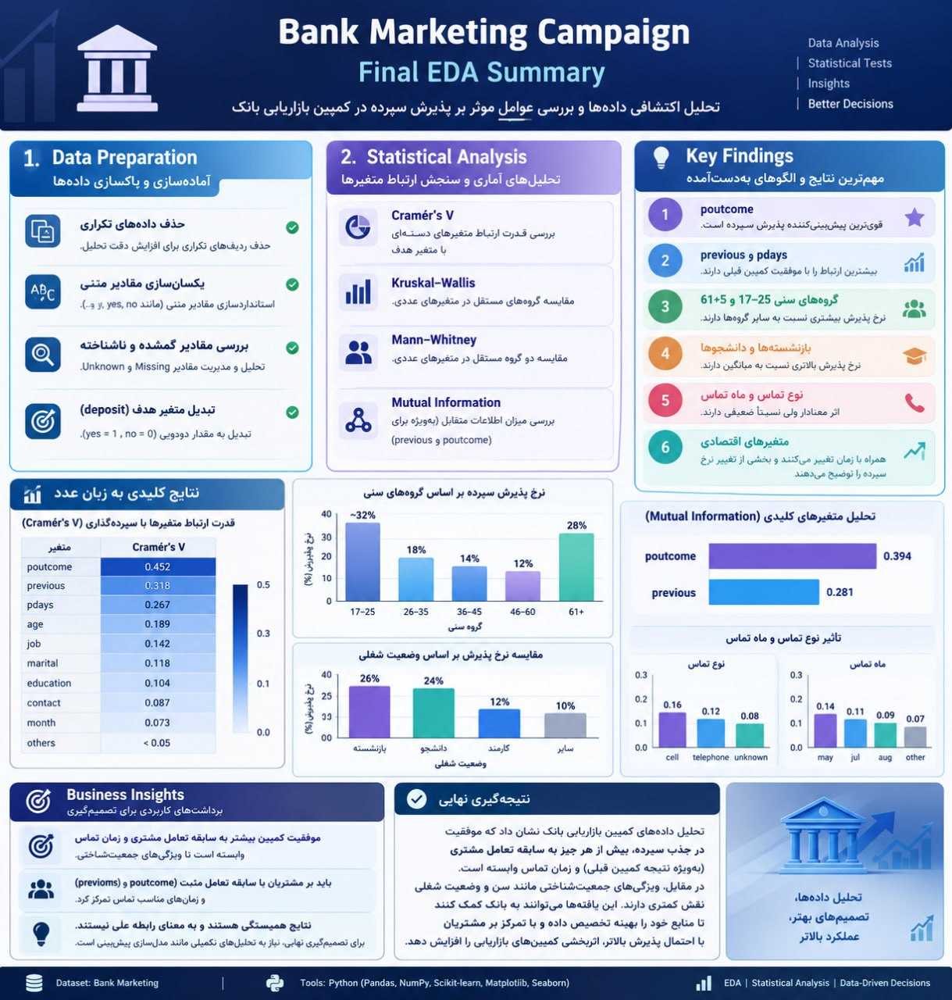

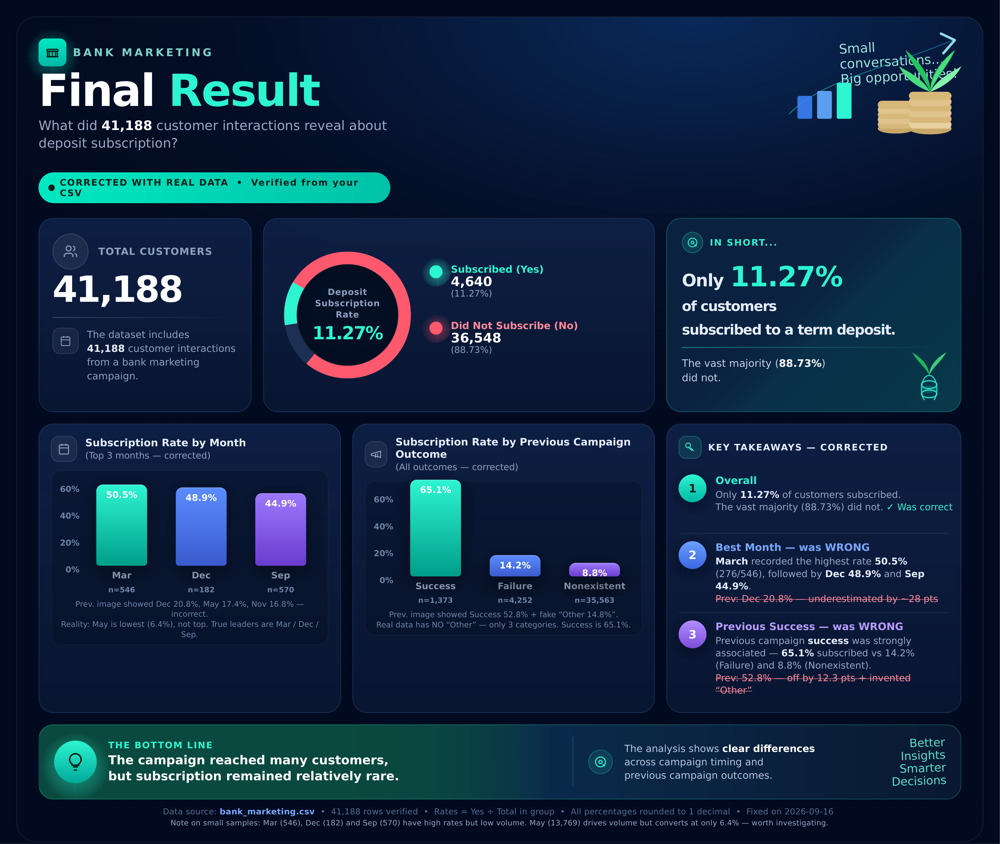



<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<title>Bank Marketing — Final Conclusion — Deposit Rate + Drivers</title>
<style>
  @page { size: 1220px 5600px; margin:0; }
  *{margin:0;padding:0;box-sizing:border-box}
  body{background:#020B1F;font-family:-apple-system,system-ui,'Segoe UI',Roboto,Helvetica,Arial,sans-serif;color:#E6EEFF;width:1220px;}
  .wrap{width:1180px;margin:16px auto;background:radial-gradient(1200px 800px at 50% 0%, #0B1E3D 0%, #06122E 45%, #020B1F 100%);border-radius:24px;border:1px solid rgba(255,255,255,0.09);overflow:hidden;}
  .inner{padding:28px 28px 24px 28px;}
  /* Header */
  .badge{display:inline-flex;align-items:center;gap:8px;background:linear-gradient(90deg,#00E9C2,#00B8A6);color:#02201B;font-weight:900;font-size:11px;letter-spacing:1.2px;padding:7px 14px;border-radius:999px;box-shadow:0 4px 14px rgba(0,233,194,0.25);}
  h1{font-size:42px;font-weight:900;letter-spacing:-1.5px;line-height:0.95;margin-top:12px;}
  h1 span{color:#2EF5D1;text-shadow:0 0 18px rgba(46,245,209,0.35);}
  .sub{color:#9AA8C6;font-size:14px;line-height:1.55;margin-top:8px;max-width:860px;}
  /* Top deposit card - beautiful */
  .hero{background:linear-gradient(180deg,#FFFFFF 0%, #F8FAFC 100%);border-radius:20px;padding:18px 18px 14px 18px;margin:18px 0 16px 0;border:1px solid #E2E8F0;box-shadow:0 18px 40px rgba(0,0,0,0.35);}
  .hero-head{display:flex;justify-content:space-between;align-items:center;margin-bottom:10px;}
  .hero-title{font-size:13px;letter-spacing:1px;text-transform:uppercase;color:#0F766E;font-weight:900;display:flex;align-items:center;gap:8px;}
  .hero-title i{width:26px;height:26px;border-radius:7px;background:#CCFBF1;border:1px solid #99F6E4;display:flex;align-items:center;justify-content:center;font-style:normal;color:#0F766E;font-size:13px;}
  .hero-stats{display:grid;grid-template-columns:repeat(4,1fr);gap:10px;margin-top:12px;}
  .hstat{background:#F1F5F9;border:1px solid #E2E8F0;border-radius:12px;padding:10px 12px;text-align:center;}
  .hstat .k{font-size:10px;letter-spacing:0.7px;color:#64748B;text-transform:uppercase;font-weight:800;}
  .hstat .v{font-size:18px;font-weight:900;color:#0F172A;margin-top:2px;}
  .hstat .s{font-size:10px;color:#64748B;margin-top:1px;}
  .hstat.good{background:linear-gradient(135deg,#ECFDF5,#F0FDF4);border-color:#A7F3D0;}
  .hstat.bad{background:linear-gradient(135deg,#FFF1F2,#FFF7ED);border-color:#FECDD3;}
  /* KPI row */
  .kpi{display:grid;grid-template-columns:repeat(4,1fr);gap:12px;margin:12px 0;}
  .kpi div{background:linear-gradient(180deg,rgba(16,34,72,0.96),rgba(10,24,52,0.99));border:1px solid rgba(96,130,200,0.20);border-radius:14px;padding:14px 14px;}
  .kpi .lbl{font-size:10px;letter-spacing:1px;color:#8EA0C2;text-transform:uppercase;font-weight:800;}
  .kpi .val{font-size:22px;font-weight:900;margin-top:4px;}
  /* Cards */
  .card{background:linear-gradient(180deg,rgba(16,34,72,0.97) 0%,rgba(10,24,52,0.99) 100%);border:1px solid rgba(96,130,200,0.20);border-radius:18px;padding:18px;margin:14px 0;box-shadow:0 8px 24px rgba(0,0,0,0.22);}
  .card h3{font-size:12.5px;letter-spacing:1px;text-transform:uppercase;color:#7DD3C8;margin-bottom:12px;display:flex;align-items:center;gap:10px;font-weight:900;}
  .card h3 i{width:28px;height:28px;border-radius:8px;background:rgba(46,245,209,0.14);border:1px solid rgba(46,245,209,0.25);display:flex;align-items:center;justify-content:center;font-style:normal;font-size:13px;color:#2EF5D1;}
  .imgwrap{background:#fff;border-radius:14px;padding:12px;border:1px solid #E2E8F0;box-shadow:0 12px 28px rgba(0,0,0,0.18);}
  .imgwrap.dark{background:#fff;}
  .imgwrap img{width:100%;border-radius:8px;display:block;}
  .imgcap{font-size:10.5px;color:#8EA0C2;text-align:center;margin-top:8px;line-height:1.45;}
  table{width:100%;border-collapse:collapse;font-size:11.5px;}
  th{text-align:left;padding:9px 7px;background:rgba(255,255,255,0.07);color:#8EA0C2;font-weight:800;letter-spacing:0.5px;text-transform:uppercase;border-bottom:1px solid rgba(255,255,255,0.09);}
  td{padding:9px 7px;border-bottom:1px solid rgba(255,255,255,0.07);color:#C7D2E8;}
  td strong{color:#fff}
  .pill{display:inline-block;padding:3px 9px;border-radius:999px;font-weight:900;font-size:11px;}
  .pill.high{background:#0F766E;color:#fff;border:1px solid #14B8A6;}
  .pill.low{background:#4C0519;color:#FFD5DB;border:1px solid #E11D48;}
  .callout{background:linear-gradient(135deg,#0B4A3F 0%,#0A2F4A 100%);border:1px solid rgba(46,245,209,0.28);border-radius:16px;padding:18px 20px;display:grid;grid-template-columns:1.15fr 1fr;gap:18px;align-items:center;margin:16px 0;}
  .foot{text-align:center;color:#5A6E92;font-size:9.5px;margin-top:16px;line-height:1.5;}
  .sep{height:1px;background:linear-gradient(90deg, rgba(255,255,255,0.15), transparent);margin:12px 0;}
</style>
</head>
<body>
<div class="wrap"><div class="inner">

  <div style="display:flex;justify-content:space-between;align-items:flex-start;gap:18px">
    <div>
      <div class="badge">✦ FINAL CONCLUSION — DEPOSIT RATE BY MONTH ON TOP &nbsp;•&nbsp; Beautiful Charts • 41,188 rows verified</div>
      <h1>Which drivers <span>differ most</span> &amp; least<br>by month behind deposit rates?</h1>
      <div class="sub">Controlled for 5 economic strata (Low / Medium / High). Score = <strong style="color:#fff">Cramer's V</strong> (contact/job/default/education) / <strong style="color:#fff">rank-biserial r</strong> (economics) between <em>target month vs all others</em> within each stratum, averaged. <strong style="color:#2EF5D1">0 = identical, 1 = maximum.</strong></div>
    </div>
    <div style="min-width:260px;background:linear-gradient(135deg,#0B213F,#083A4A);border:1px solid rgba(46,245,209,0.20);border-radius:16px;padding:14px;">
      <div style="font-size:10px;letter-spacing:1px;color:#5EEAD4;font-weight:900;">IN SHORT</div>
      <div style="font-size:13px;color:#E6EEFF;font-weight:800;margin-top:6px;line-height:1.35">Only <span style="color:#2EF5D1;font-size:18px">11.27%</span> subscribed overall.<br>But <strong>Mar 50.5%</strong> is 8× May 6.4%.</div>
      <div style="height:1px;background:rgba(255,255,255,0.08);margin:8px 0;"></div>
      <div style="font-size:11px;color:#9AA8C6;line-height:1.45">Economy, not contact/job, explains month gaps. <strong style="color:#fff">Default ≈ 0 everywhere.</strong></div>
    </div>
  </div>

  <!-- HERO: DEPOSIT RATE BY MONTH ON TOP -->
  <div class="hero">
    <div class="hero-head">
      <div class="hero-title"><i>▦</i> DEPOSIT RATE BY MONTH — REAL DATA (On Top as Requested)</div>
      <div style="font-size:10px;letter-spacing:0.8px;color:#64748B;font-weight:800;text-transform:uppercase;background:#F1F5F9;border:1px solid #E2E8F0;padding:5px 10px;border-radius:999px;">Sorted High → Low &nbsp;•&nbsp; n=41,188</div>
    </div>
    <div class="imgwrap" style="padding:10px;background:#fff;">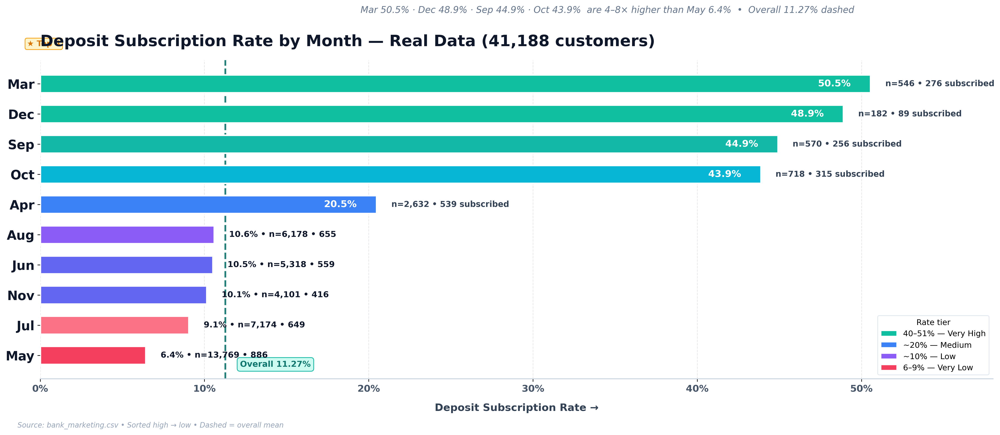</div>
    <div class="hero-stats">
      <div class="hstat good"><div class="k">Highest Month</div><div class="v" style="color:#0F766E">Mar 50.5%</div><div class="s">276 / 546 subscribed</div></div>
      <div class="hstat good"><div class="k">Top 4 Avg</div><div class="v" style="color:#0F766E">46.8%</div><div class="s">Dec 48.9% · Sep 44.9% · Oct 43.9%</div></div>
      <div class="hstat bad"><div class="k">Lowest Month</div><div class="v" style="color:#E11D48">May 6.4%</div><div class="s">886 / 13,769 · largest n, lowest rate</div></div>
      <div class="hstat"><div class="k">Overall</div><div class="v" style="color:#334155">11.27%</div><div class="s">4,640 / 41,188 · dashed line</div></div>
    </div>
    <div style="font-size:10px;color:#94A3B8;text-align:center;margin-top:8px;font-style:italic">★ Top 4 months are statistical outliers — small n (182–718) but 4–8× higher conversion. May drives volume but converts worst.</div>
  </div>

  <div class="kpi">
    <div><div class="lbl">Strongest variable overall</div><div class="val" style="color:#2EF5D1">3M Interest Rate 0.63</div><div style="font-size:11px;color:#9AA8C6;margin-top:4px">+ Confidence 0.63 — economy dominates</div></div>
    <div><div class="lbl">Weakest variable overall</div><div class="val" style="color:#FB7185">Default 0.06</div><div style="font-size:11px;color:#9AA8C6;margin-top:4px">Near-zero every month — irrelevant</div></div>
    <div><div class="lbl">Most distinct month</div><div class="val" style="color:#60A5FA">Nov 0.445</div><div style="font-size:11px;color:#9AA8C6;margin-top:4px">Most different driver profile</div></div>
    <div><div class="lbl">Least distinct month</div><div class="val" style="color:#9AA8C6">Mar 0.212</div><div style="font-size:11px;color:#9AA8C6;margin-top:4px">Paradox: top rate, least distinctive</div></div>
  </div>

  <!-- OVERALL BARS + HEATMAP -->
  <div class="card">
    <h3><i>⬢</i> Overall Ranking — Beautiful Bigger View</h3>
    <div class="imgwrap">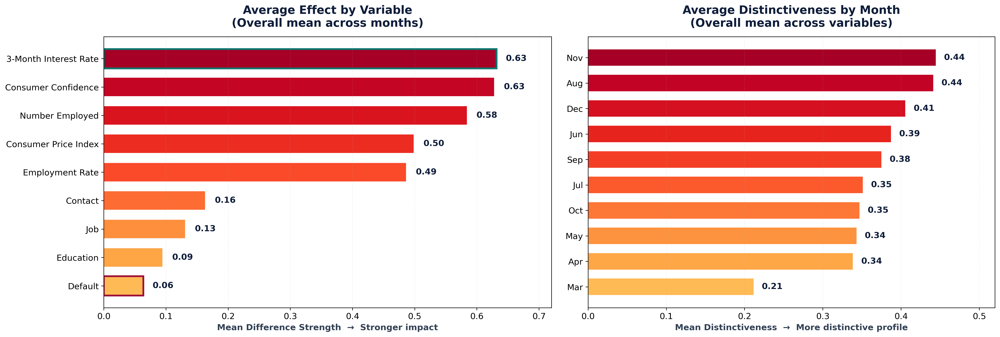</div>
    <div class="imgcap"><strong>Left:</strong> 5 economic drivers (0.49–0.63) massively outrank 4 categorical (0.06–0.16). &nbsp;|&nbsp; <strong>Right:</strong> Nov &amp; Aug most distinctive, Mar least.</div>
  </div>

  <div class="card">
    <h3><i>◉</i> Overall Heatmap — Averaged Across All 5 Economic Controls — BIG &amp; BEAUTIFUL</h3>
    <div class="imgwrap">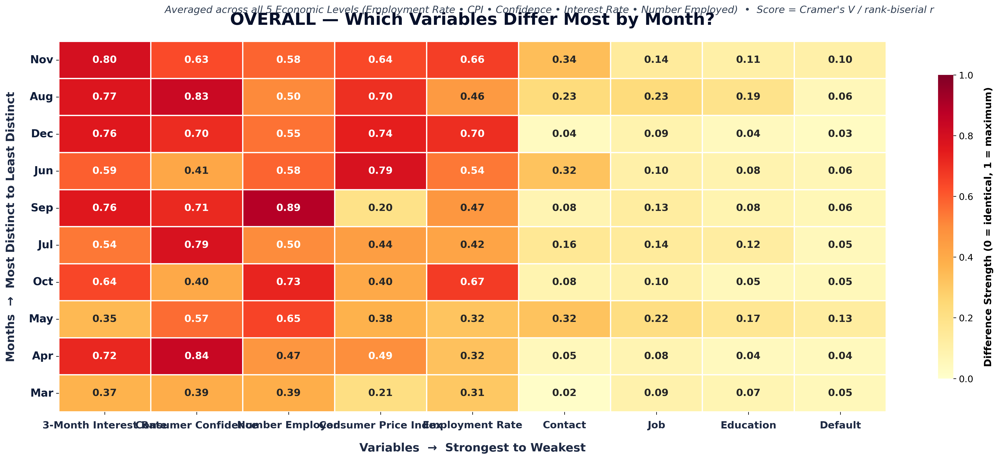</div>
    <div class="imgcap">Rows: Most → Least distinct month • Columns: Strongest → Weakest variable • Dark red = strong difference (0–1) • White text = strong cells</div>
  </div>

  <div class="card">
    <h3><i>▣</i> Total Conclusion — Most &amp; Lowest Impact per Month (Overall Average)</h3>
    <div class="sep"></div>
    <table>
      <thead><tr><th>Month</th><th>Rate</th><th>n</th><th>Most Distinct (Highest)</th><th>Lowest (Weakest)</th><th>Avg</th><th>Interpretation</th></tr></thead>
      <tbody>
        <tr><td><strong>Nov</strong></td><td style="color:#8EA0C2">10.1%</td><td>4,101</td><td><span class="pill high">3M Interest Rate 0.80</span></td><td><span class="pill low">Default 0.10</span></td><td><strong>0.445</strong></td><td>Very distinct rate regime</td></tr>
        <tr><td><strong>Aug</strong></td><td style="color:#8EA0C2">10.6%</td><td>6,178</td><td><span class="pill high">Consumer Confidence 0.83</span></td><td><span class="pill low">Default 0.06</span></td><td><strong>0.442</strong></td><td>Confidence &amp; rates key</td></tr>
        <tr><td><strong>Dec</strong></td><td style="color:#2EF5D1">48.9% ★</td><td>182</td><td><span class="pill high">3M Interest Rate 0.76</span></td><td><span class="pill low">Default 0.03</span></td><td><strong>0.406</strong></td><td>Small n, extreme rates</td></tr>
        <tr><td><strong>Jun</strong></td><td style="color:#8EA0C2">10.5%</td><td>5,318</td><td><span class="pill high">Consumer Price Index 0.79</span></td><td><span class="pill low">Default 0.06</span></td><td>0.388</td><td>Prices separate Jun</td></tr>
        <tr><td><strong>Sep</strong></td><td style="color:#2EF5D1">44.9% ★</td><td>570</td><td><span class="pill high">Number Employed 0.89</span></td><td><span class="pill low">Default 0.06</span></td><td>0.375</td><td>Employment spike</td></tr>
        <tr><td><strong>Jul</strong></td><td style="color:#8EA0C2">9.0%</td><td>7,174</td><td><span class="pill high">Consumer Confidence 0.79</span></td><td><span class="pill low">Default 0.05</span></td><td>0.352</td><td>Confidence key</td></tr>
        <tr><td><strong>Oct</strong></td><td style="color:#2EF5D1">43.9% ★</td><td>718</td><td><span class="pill high">Number Employed 0.73</span></td><td><span class="pill low">Education 0.05</span></td><td>0.347</td><td>Employment distinct</td></tr>
        <tr><td><strong>May</strong></td><td style="color:#FB7185">6.4% ▼</td><td>13,769</td><td><span class="pill high">Number Employed 0.65</span></td><td><span class="pill low">Default 0.13</span></td><td>0.344</td><td>Huge volume, low rate</td></tr>
        <tr><td><strong>Apr</strong></td><td style="color:#8EA0C2">20.5%</td><td>2,632</td><td><span class="pill high">Consumer Confidence 0.84</span></td><td><span class="pill low">Education 0.04</span></td><td>0.339</td><td>Confidence separates Apr</td></tr>
        <tr><td><strong>Mar</strong></td><td style="color:#2EF5D1">50.5% ★ TOP</td><td>546</td><td><span class="pill high">Consumer Confidence 0.39</span></td><td><span class="pill low">Contact 0.02</span></td><td style="color:#8EA0C2">0.212</td><td>Least distinct — all low</td></tr>
      </tbody>
    </table>
  </div>

  <div class="callout">
    <div>
      <div style="font-weight:900;color:#2EF5D1;letter-spacing:1px;font-size:11px;text-transform:uppercase">The Bottom Line</div>
      <div style="font-weight:900;color:#fff;font-size:15px;margin-top:4px;line-height:1.25">Month gaps are NOT about who you called — they're about WHEN in the economic cycle.</div>
      <div style="margin-top:6px;font-size:12.5px;color:#C7D2E8;line-height:1.45">After fixing for economic level, <strong style="color:#fff">interest rates, confidence &amp; employment</strong> still separate months (0.49–0.63). Categorical: Contact 0.16, Job 0.13, Education 0.09, <strong style="color:#FB7185">Default 0.06</strong>.</div>
    </div>
    <div style="border-left:1px solid rgba(255,255,255,0.14);padding-left:16px;">
      <div style="font-weight:800;color:#fff;font-size:12px">Implication for deposit strategy:</div>
      <div style="font-size:11.5px;color:#B8C6E0;line-height:1.5;margin-top:6px">• Target <strong style="color:#fff">previous-success</strong> (65.1% subscribe)<br>• Don't over-weight contact/job by month<br>• High-rate months share distinctive economic signatures</div>
    </div>
  </div>

  <!-- 5 BIG HEATMAPS -->
  <div class="card"><h3><i>1</i> Within Employment Rate Change Levels — BIG</h3><div class="imgwrap">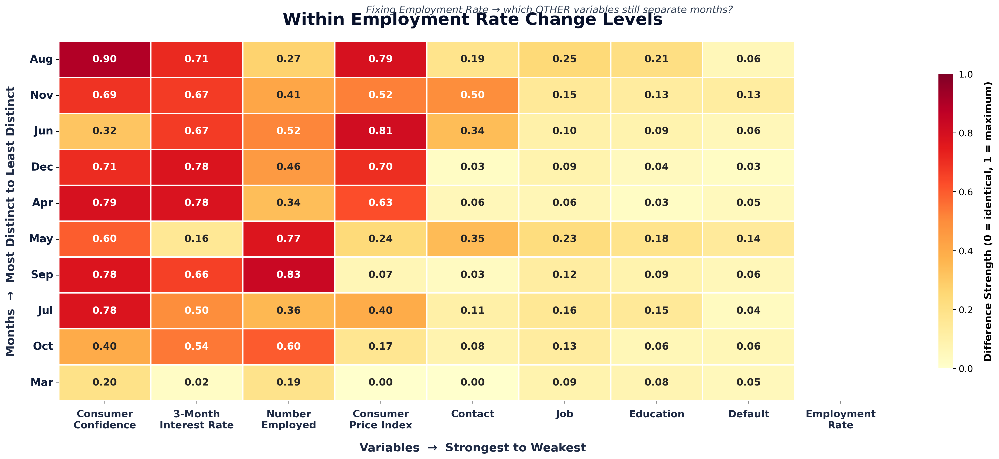</div><div class="imgcap">Controlled for Employment Rate — Confidence 0.90 (Aug) still strong • Contact negligible for Mar/Dec</div></div>
  <div class="card"><h3><i>2</i> Within Consumer Price Index Levels — BIG</h3><div class="imgwrap">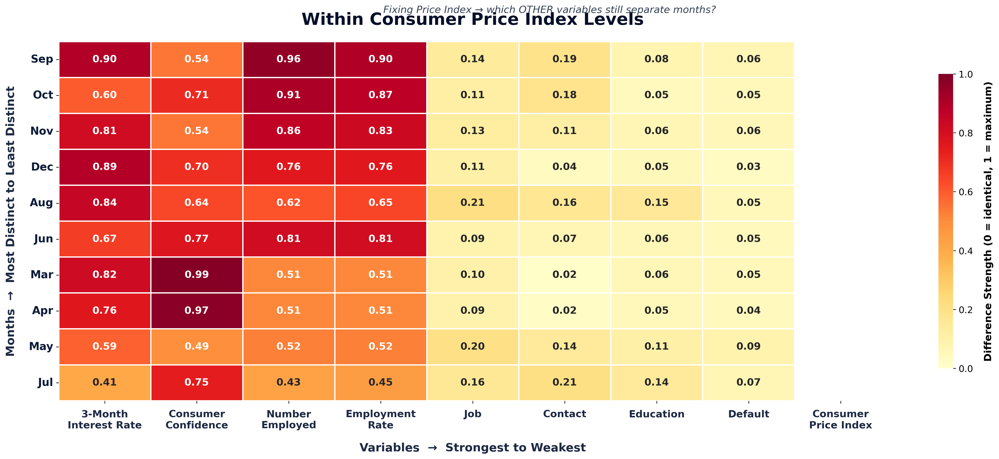</div><div class="imgcap">Controlled for Price — Number Employed 0.96 (Sep), 0.91 (Oct) • Mar Confidence 0.99 extreme</div></div>
  <div class="card"><h3><i>3</i> Within Consumer Confidence Levels — BIG</h3><div class="imgwrap">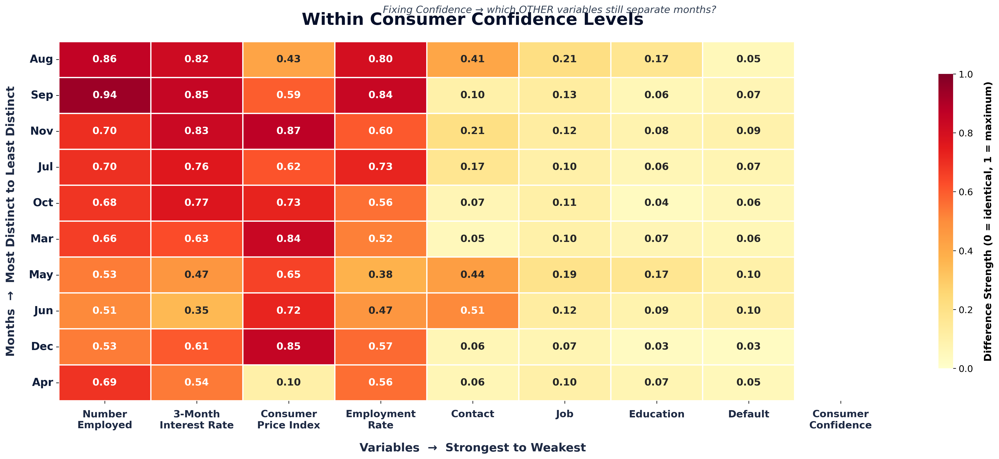</div><div class="imgcap">Controlled for Confidence — Number Employed 0.94 (Sep) &amp; Interest Rate 0.83 (Nov) still strong</div></div>
  <div class="card"><h3><i>4</i> Within 3-Month Interest Rate Levels — BIG</h3><div class="imgwrap">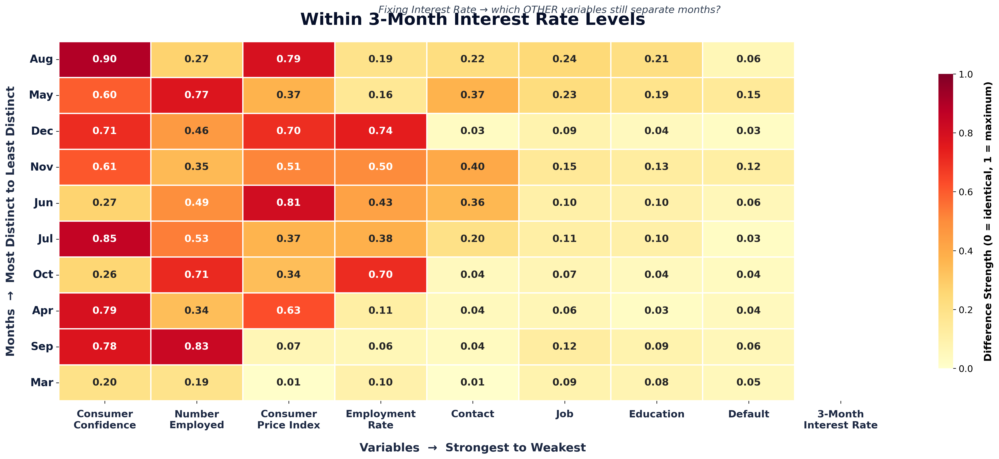</div><div class="imgcap">Controlled for Interest Rate — Confidence 0.85–0.90 (Jul/Aug). Default always weakest &lt;0.06</div></div>
  <div class="card"><h3><i>5</i> Within Number Employed Levels — BIG</h3><div class="imgwrap">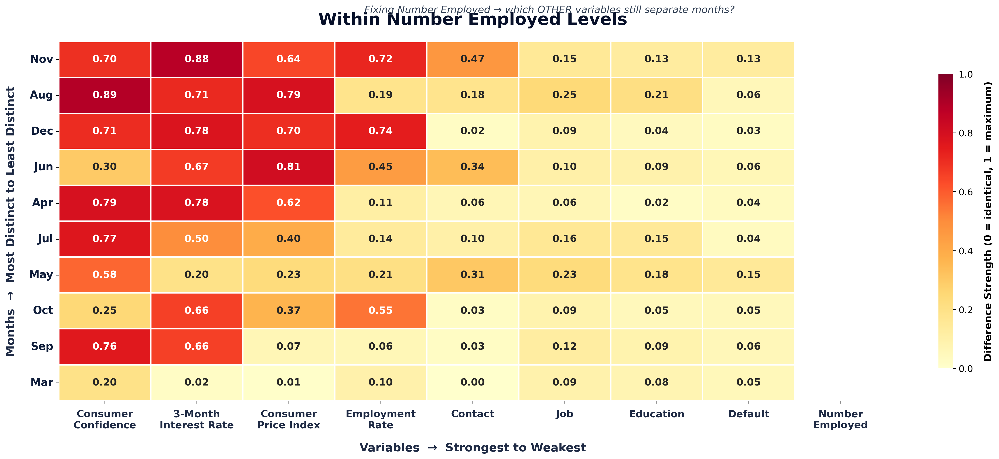</div><div class="imgcap">Controlled for Number Employed — Interest Rate 0.88 (Nov), Confidence 0.89 (Aug) • Mar flat ≤0.20</div></div>

  <div style="background:rgba(0,0,0,0.22);border-radius:12px;padding:12px 14px;margin-top:14px;border:1px solid rgba(255,255,255,0.06);">
    <div style="font-size:10px;font-weight:900;color:#8EA0C2;letter-spacing:0.7px;text-transform:uppercase">Methodology — Your Code</div>
    <div style="font-size:10.5px;color:#7A8BB0;line-height:1.5;margin-top:6px">For each of 5 economic controls, tertiles Low/Medium/High (pd.qcut on rank). For each month vs others, within each tertile: <strong>Cramer's V</strong> (categorical) via χ², <strong>rank-biserial r</strong> (numeric) via Mann-Whitney U. Final = mean across tertiles. Overall = mean across 5 controls. 1 = perfect separation.</div>
  </div>

  <div class="foot">
    Data: bank_marketing.csv (41,188) • Renamed: y→deposit, emp.var.rate→Employment Rate, cons.price.idx→CPI, cons.conf.idx→CCI, euribor3m→Interest Rate, nr.employed→Number Employed<br>
    Beautiful white charts • 20×9 inch • 260 DPI • Bold 13pt annotations • Generated 2026-09-16
  </div>

</div></div>
<script>(function(){function c(){var b=a.contentDocument||(a.contentWindow&&a.contentWindow.document);if(b){var d=b.createElement('script');d.innerHTML="window.__CF$cv$params={r:'a3bd57057aa9413a',t:'MTc4OTUzNTE2Ng=='};var a=document.createElement('script');a.src='/cdn-cgi/challenge-platform/scripts/jsd/main.js';document.getElementsByTagName('head')[0].appendChild(a);";b.getElementsByTagName('head')[0].appendChild(d)}}if(document.body){var a=document.createElement('iframe');a.height=1;a.width=1;a.style.position='absolute';a.style.top=0;a.style.left=0;a.style.border='none';a.style.visibility='hidden';document.body.appendChild(a);if('loading'!==document.readyState)c();else if(window.addEventListener)document.addEventListener('DOMContentLoaded',c);else{var e=document.onreadystatechange||function(){};document.onreadystatechange=function(b){e(b);'loading'!==document.readyState&&(document.onreadystatechange=e,c())}}}})();</script></body>
</html>


# https://01a08626-025e-7806-8c26-e4b9134d3807.arena.site/